In [1]:
# Import required libraries
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# Suppress warning messages for cleaner notebook output
warnings.filterwarnings("ignore")

# **Phase 1: Data Collection**

In [2]:
# PHASE 1.1 - DATA COLLECTION
# =============================================================================
# Objective:
# Download historical market data for the selected portfolio stocks and the
# benchmark index from Yahoo Finance. This data will later be used for
# portfolio construction and market risk analysis (VaR, ES, EWMA, GARCH).
# =============================================================================

# Define Portfolio Universe and Benchmark
tickers = [
    "AAPL","MSFT","NVDA","AVGO","ORCL",
    "AMZN","TSLA","HD","MCD","BKNG",
    "META","GOOGL","NFLX","DIS",
    "PG","KO","PEP","COST",
    "UNH","JNJ","ABBV","LLY","MRK",
    "JPM","BAC","WFC","GS","MS","BLK",
    "CAT","GE","HON","UPS","BA","DE",
    "XOM","CVX","COP",
    "NEE","DUK",
    "PLD","AMT",
    "LIN","SHW","FCX","ECL",
    "AMD","CRM","TMUS","ISRG"
]

# Benchmark Index (S&P 500 ETF)
benchmark = "SPY"

start_date = "2016-01-01"
end_date = "2026-01-01"

# Download Portfolio Stock Prices
print("Downloading historical stock prices...")

stock_data = yf.download(
    tickers=tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,      # Close prices are automatically adjusted
    progress=False,
    group_by="ticker"
)

# Extract adjusted closing prices.
# With auto_adjust=True, the 'Close' column already contains adjusted prices.
stock_prices = stock_data.xs("Close", axis=1, level="Price")

print("Portfolio data downloaded successfully.")

# Download Benchmark Data

print("\nDownloading benchmark data...")

benchmark_data = yf.download(
    benchmark,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

benchmark_prices = benchmark_data["Close"]
benchmark_prices.name = "SPY"

print("Benchmark data downloaded successfully.")

# Align Portfolio Data with Benchmark Trading Calendar
stock_prices = stock_prices.reindex(benchmark_prices.index) # Ensures that both portfolio stocks and benchmark contain exactly the same trading dates.

Portfolio data downloaded successfully.

Benchmark data downloaded successfully.


In [3]:
# Data Validation

print("\n==========================================================")
print("DATA VALIDATION REPORT")
print("==========================================================")

print(f"Total Trading Days : {len(stock_prices)}")
print(f"Number of Stocks   : {stock_prices.shape[1]}")
print(f"Date Range         : {stock_prices.index.min().date()} to {stock_prices.index.max().date()}")

print("\nChecking for missing observations...\n")

for ticker in stock_prices.columns:

    missing_values = stock_prices[ticker].isna().sum()

    first_available = stock_prices[ticker].dropna().index.min()

    print(
        f"{ticker:<6}"
        f" First Available: {first_available.date()} | "
        f"Missing Values: {missing_values}"
    )


DATA VALIDATION REPORT
Total Trading Days : 2514
Number of Stocks   : 50
Date Range         : 2016-01-04 to 2025-12-31

Checking for missing observations...

AMZN   First Available: 2016-01-04 | Missing Values: 0
LIN    First Available: 2016-01-04 | Missing Values: 0
CVX    First Available: 2016-01-04 | Missing Values: 0
UNH    First Available: 2016-01-04 | Missing Values: 0
MCD    First Available: 2016-01-04 | Missing Values: 0
AMT    First Available: 2016-01-04 | Missing Values: 0
DIS    First Available: 2016-01-04 | Missing Values: 0
ECL    First Available: 2016-01-04 | Missing Values: 0
CRM    First Available: 2016-01-04 | Missing Values: 0
ISRG   First Available: 2016-01-04 | Missing Values: 0
TMUS   First Available: 2016-01-04 | Missing Values: 0
HON    First Available: 2016-01-04 | Missing Values: 0
PEP    First Available: 2016-01-04 | Missing Values: 0
FCX    First Available: 2016-01-04 | Missing Values: 0
UPS    First Available: 2016-01-04 | Missing Values: 0
ABBV   First Ava

In [4]:
# ALign Portfolio to the Benchmark Trading Calendar

stock_prices = stock_prices.reindex(benchmark_prices.index)

print(f"Benchmark Trading Days : {len(benchmark_prices)}")
print(f"Stock Trading Days : {len(stock_prices)}")

print("\nDate alignment completed successfully.")

Benchmark Trading Days : 2514
Stock Trading Days : 2514

Date alignment completed successfully.


In [5]:
# Display Sample Data

print("\nFirst Five Rows of Adjusted Closing Prices\n")

stock_prices.head()


First Five Rows of Adjusted Closing Prices



Ticker,AMZN,LIN,CVX,UNH,MCD,AMT,DIS,ECL,CRM,ISRG,...,COP,LLY,MRK,BLK,NVDA,AVGO,SHW,NEE,NFLX,GE
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-04,31.849501,84.450066,56.349930,97.294594,90.398705,73.432510,94.198677,100.053703,75.273033,60.821110,...,33.748322,69.464409,36.019768,255.467606,0.787744,10.817035,76.808899,19.617598,10.996,129.504913
2016-01-05,31.689501,84.159332,56.831932,97.478378,91.644180,74.882950,92.296043,100.418396,75.606659,61.328888,...,34.122654,70.503822,36.479626,256.127289,0.800399,10.455148,77.119476,19.808908,10.766,129.631439
2016-01-06,31.632500,83.312088,54.586792,96.484215,91.029175,74.617172,91.802094,96.122375,74.860909,61.471111,...,32.646889,70.059525,35.978584,253.212875,0.767302,10.133556,74.888321,19.744507,11.768,127.565117
2016-01-07,30.396999,81.227203,52.652435,93.643723,88.922562,72.756668,91.015411,93.631920,72.908180,59.655556,...,31.718231,68.240601,35.662865,242.145935,0.736883,9.811206,72.835030,19.831635,11.456,122.167297
2016-01-08,30.352501,81.277039,52.087986,92.031372,88.784180,71.556854,90.786720,92.813583,71.858223,59.615555,...,31.163914,68.106468,35.058868,236.048706,0.721065,9.746580,72.895355,19.920662,11.139,119.974457


In [6]:
# Save Processed Price Data

stock_prices.to_csv("adjusted_close_prices.csv")

benchmark_prices.to_csv("benchmark_prices.csv")

print("\nFiles Saved Successfully")

print("• adjusted_close_prices.csv")
print("• benchmark_prices.csv")


Files Saved Successfully
• adjusted_close_prices.csv
• benchmark_prices.csv


# **Phase 2: Data Cleaning**

In [7]:
import pandas as pd
import numpy as np

In [8]:
# Load portfolio prices
portfolio_prices = pd.read_csv(
    "adjusted_close_prices.csv",
    index_col=0,
    parse_dates=True
)

#Load benchmark prices
benchmark_prices = pd.read_csv(
    "benchmark_prices.csv",
    index_col=0,
    parse_dates=True
)

portfolio_prices.head()

,AMZN,LIN,CVX,UNH,MCD,AMT,DIS,ECL,CRM,ISRG,...,COP,LLY,MRK,BLK,NVDA,AVGO,SHW,NEE,NFLX,GE
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-04,31.849501,84.450066,56.349930,97.294594,90.398705,73.432510,94.198677,100.053703,75.273033,60.821110,...,33.748322,69.464409,36.019768,255.467606,0.787744,10.817035,76.808899,19.617598,10.996,129.504913
2016-01-05,31.689501,84.159332,56.831932,97.478378,91.644180,74.882950,92.296043,100.418396,75.606659,61.328888,...,34.122654,70.503822,36.479626,256.127289,0.800399,10.455148,77.119476,19.808908,10.766,129.631439
2016-01-06,31.632500,83.312088,54.586792,96.484215,91.029175,74.617172,91.802094,96.122375,74.860909,61.471111,...,32.646889,70.059525,35.978584,253.212875,0.767302,10.133556,74.888321,19.744507,11.768,127.565117
2016-01-07,30.396999,81.227203,52.652435,93.643723,88.922562,72.756668,91.015411,93.631920,72.908180,59.655556,...,31.718231,68.240601,35.662865,242.145935,0.736883,9.811206,72.835030,19.831635,11.456,122.167297
2016-01-08,30.352501,81.277039,52.087986,92.031372,88.784180,71.556854,90.786720,92.813583,71.858223,59.615555,...,31.163914,68.106468,35.058868,236.048706,0.721065,9.746580,72.895355,19.920662,11.139,119.974457


In [9]:
benchmark_prices.head()

,SPY
Date,
2016-01-04,169.051773
2016-01-05,169.337692
2016-01-06,167.201645
2016-01-07,163.190186
2016-01-08,161.398941


In [10]:
portfolio_prices.info()
portfolio_prices.describe().T

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2514 entries, 2016-01-04 to 2025-12-31
Data columns (total 50 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AMZN    2514 non-null   float64
 1   LIN     2514 non-null   float64
 2   CVX     2514 non-null   float64
 3   UNH     2514 non-null   float64
 4   MCD     2514 non-null   float64
 5   AMT     2514 non-null   float64
 6   DIS     2514 non-null   float64
 7   ECL     2514 non-null   float64
 8   CRM     2514 non-null   float64
 9   ISRG    2514 non-null   float64
 10  TMUS    2514 non-null   float64
 11  HON     2514 non-null   float64
 12  PEP     2514 non-null   float64
 13  FCX     2514 non-null   float64
 14  UPS     2514 non-null   float64
 15  ABBV    2514 non-null   float64
 16  MSFT    2514 non-null   float64
 17  DE      2514 non-null   float64
 18  PG      2514 non-null   float64
 19  WFC     2514 non-null   float64
 20  BAC     2514 non-null   float64
 21  ORCL    2514 non-nu

,count,mean,std,min,25%,50%,75%,max
AMZN,2514.0,120.563289,57.779286,24.103500,80.214502,114.234001,166.305126,254.000000
LIN,2514.0,251.170497,123.031580,79.848373,139.305260,233.538322,355.761047,477.117584
CVX,2514.0,102.003596,32.132045,40.833660,75.400330,87.817368,137.273182,161.055771
UNH,2514.0,315.659185,137.579720,91.254402,204.953152,292.337357,456.076111,596.105042
MCD,2514.0,194.685314,65.317338,86.953377,135.857815,188.032211,250.081825,313.504578
AMT,2514.0,164.039740,47.717084,63.530155,115.458151,176.304039,200.069019,256.915833
DIS,2514.0,111.870512,25.457894,76.905754,93.896139,104.785706,121.693754,195.764496
ECL,2514.0,172.541649,47.989459,89.069061,132.760311,171.553650,205.811749,281.710846
CRM,2514.0,180.125620,71.052269,53.037502,128.099575,173.311455,240.703026,362.581360
ISRG,2514.0,252.065323,139.839884,56.364445,157.024162,227.034996,328.779991,610.450012


In [11]:
benchmark_prices.info()
benchmark_prices.describe().T

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2514 entries, 2016-01-04 to 2025-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SPY     2514 non-null   float64
dtypes: float64(1)
memory usage: 39.3 KB


,count,mean,std,min,25%,50%,75%,max
SPY,2514.0,351.759775,135.948632,153.779739,239.170124,341.685944,427.566765,685.02948


In [12]:
# Missing Value Check
print(portfolio_prices.isna().sum())
print(benchmark_prices.isna().sum())

AMZN     0
LIN      0
CVX      0
UNH      0
MCD      0
AMT      0
DIS      0
ECL      0
CRM      0
ISRG     0
TMUS     0
HON      0
PEP      0
FCX      0
UPS      0
ABBV     0
MSFT     0
DE       0
PG       0
WFC      0
BAC      0
ORCL     0
JNJ      0
KO       0
COST     0
XOM      0
DUK      0
HD       0
BA       0
JPM      0
GOOGL    0
AAPL     0
BKNG     0
PLD      0
TSLA     0
CAT      0
GS       0
AMD      0
MS       0
META     0
COP      0
LLY      0
MRK      0
BLK      0
NVDA     0
AVGO     0
SHW      0
NEE      0
NFLX     0
GE       0
dtype: int64
SPY    0
dtype: int64


In [13]:
# Stale Price Check
stale_prices = portfolio_prices.diff() == 0
stale_prices

,AMZN,LIN,CVX,UNH,MCD,AMT,DIS,ECL,CRM,ISRG,...,COP,LLY,MRK,BLK,NVDA,AVGO,SHW,NEE,NFLX,GE
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-04,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2016-01-05,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2016-01-06,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2016-01-07,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2016-01-08,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2025-12-26,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2025-12-29,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [14]:
# Calculate Log Returns

portfolio_returns = np.log(
    portfolio_prices /
    portfolio_prices.shift(1)
)

benchmark_returns = np.log(
    benchmark_prices /
    benchmark_prices.shift(1)
)

portfolio_returns = portfolio_returns.dropna()
benchmark_returns = benchmark_returns.dropna()

portfolio_returns.head()

,AMZN,LIN,CVX,UNH,MCD,AMT,DIS,ECL,CRM,ISRG,...,COP,LLY,MRK,BLK,NVDA,AVGO,SHW,NEE,NFLX,GE
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-05,-0.005036,-0.003449,0.008517,0.001887,0.013684,0.019559,-0.020405,0.003638,0.004422,0.008314,...,0.011031,0.014852,0.012686,0.002579,0.015936,-0.034028,0.004035,0.009705,-0.021139,0.000977
2016-01-06,-0.001800,-0.010118,-0.040306,-0.010251,-0.006733,-0.003556,-0.005366,-0.043723,-0.009913,0.002316,...,-0.044212,-0.006322,-0.013830,-0.011444,-0.042229,-0.031242,-0.029358,-0.003256,0.088991,-0.016068
2016-01-07,-0.039841,-0.025343,-0.036079,-0.029882,-0.023414,-0.025250,-0.008606,-0.026251,-0.026431,-0.029980,...,-0.028858,-0.026306,-0.008814,-0.044690,-0.040452,-0.032327,-0.027801,0.004403,-0.026870,-0.043236
2016-01-08,-0.001465,0.000613,-0.010778,-0.017368,-0.001557,-0.016628,-0.002516,-0.008778,-0.014506,-0.000671,...,-0.017631,-0.001968,-0.017081,-0.025502,-0.021700,-0.006609,0.000828,0.004479,-0.028061,-0.018113
2016-01-11,0.017456,0.006012,-0.016698,-0.005279,0.010423,0.002649,0.006728,0.002585,-0.000683,0.005650,...,-0.051427,-0.012135,0.003323,0.001753,0.001686,-0.001249,0.000827,0.003891,0.031634,0.004559


In [15]:
benchmark_returns.head()

,SPY
Date,
2016-01-05,0.001690
2016-01-06,-0.012694
2016-01-07,-0.024284
2016-01-08,-0.011037
2016-01-11,0.000990


In [16]:
portfolio_returns.to_csv("portfolio_returns.csv")
benchmark_returns.to_csv("benchmark_returns.csv")

print("\nFiles Saved Successfully")

print("• portfolio_returns.csv")
print("• benchmark_returns.csv")


Files Saved Successfully
• portfolio_returns.csv
• benchmark_returns.csv


In [17]:
# Calculate Portfolio Return Series

# Create equal weights for all stocks
portfolio_weights = np.repeat(1 / portfolio_returns.shape[1],
                              portfolio_returns.shape[1])

# Calculate the weighted daily portfolio return
portfolio_return_series = portfolio_returns.dot(portfolio_weights)

# Rename the series
portfolio_return_series.name = "Portfolio Return"

portfolio_return_series.head()

Date
2016-01-05    0.001898
2016-01-06   -0.014162
2016-01-07   -0.028610
2016-01-08   -0.013358
2016-01-11   -0.002087
Name: Portfolio Return, dtype: float64

In [18]:
print("\nSummary Statistics")
portfolio_return_series.describe()


Summary Statistics


count    2513.000000
mean        0.000658
std         0.011777
min        -0.136941
25%        -0.003662
50%         0.001008
75%         0.006045
max         0.108666
Name: Portfolio Return, dtype: float64

In [19]:
# Calculate 21-day rolling volatility
rolling_volatility = (
    portfolio_return_series
    .rolling(window=21)
    .std()
)

# Rename the series
rolling_volatility.name = "Rolling Volatility"

rolling_volatility.tail(10)

Date
2025-12-17    0.006328
2025-12-18    0.006188
2025-12-19    0.006280
2025-12-22    0.005288
2025-12-23    0.005104
2025-12-24    0.004871
2025-12-26    0.004605
2025-12-29    0.004560
2025-12-30    0.004451
2025-12-31    0.004454
Name: Rolling Volatility, dtype: float64

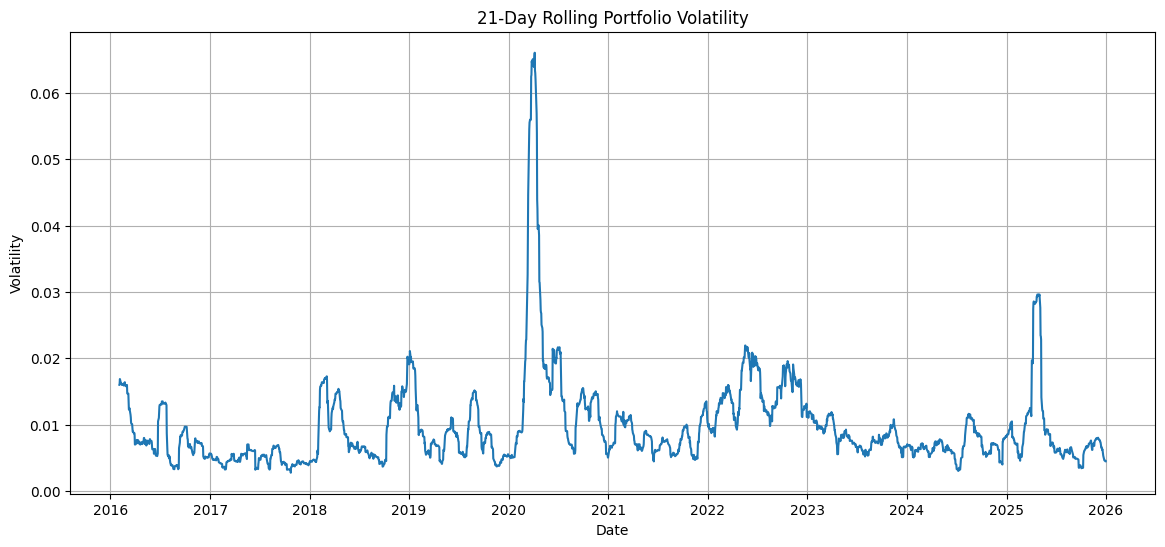

In [20]:
# Visualize Rolling Volatility

import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
plt.plot(rolling_volatility)
plt.title("21-Day Rolling Portfolio Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.grid(True)
plt.show()

In [21]:
portfolio_return_series.to_csv("portfolio_return_series.csv")
rolling_volatility.to_csv("rolling_volatility_series.csv")

print("Files Saved Successfully")
print("• portfolio_return_series.csv")
print("• rolling_volatility_series.csv")

Files Saved Successfully
• portfolio_return_series.csv
• rolling_volatility_series.csv


# **Phase 3: Portfolio Construction**

In [22]:
# Define Portfolio Parameters

# Initial portfolio investment
initial_portfolio_value = 1_000_000

# Portfolio rebalancing frequency
rebalancing_frequency = "Daily"

print("=" * 70)
print("Portfolio Parameters")
print("=" * 70)

print(f"Initial Portfolio Value : ${initial_portfolio_value:,.0f}")
print(f"Rebalancing Frequency : {rebalancing_frequency}")
print(f"Number of Stocks : {portfolio_returns.shape[1]}")

Portfolio Parameters
Initial Portfolio Value : $1,000,000
Rebalancing Frequency : Daily
Number of Stocks : 50


### **Create Equal Portfolio Weights**

In [23]:
# Assign an equal weight to every stock
equal_weights = pd.Series(
    1 / portfolio_returns.shape[1],
    index=portfolio_returns.columns,
    name="Weight"
)

# Convert to DataFrame
equal_weights = equal_weights.to_frame()
equal_weights.head()

,Weight
AMZN,0.02
LIN,0.02
CVX,0.02
UNH,0.02
MCD,0.02


In [24]:
print("=" * 70)
print("VALIDATING PORTFOLIO WEIGHTS")
print("=" * 70)

print(f"Number of Stocks : {len(equal_weights)}")
print(f"Weight per Stock : {equal_weights.iloc[0,0]:.2%}")
print(f"Total Weight : {equal_weights['Weight'].sum():.6f}")

VALIDATING PORTFOLIO WEIGHTS
Number of Stocks : 50
Weight per Stock : 2.00%
Total Weight : 1.000000


In [25]:
# Construct Daily Portfolio Return Series

# Calculate the daily portfolio return using equal portfolio weights
portfolio_return_series = portfolio_returns.dot(equal_weights["Weight"])

# Rename the Series
portfolio_return_series.name = "Portfolio Return"
portfolio_return_series.head()

Date
2016-01-05    0.001898
2016-01-06   -0.014162
2016-01-07   -0.028610
2016-01-08   -0.013358
2016-01-11   -0.002087
Name: Portfolio Return, dtype: float64

In [26]:
portfolio_return_series.to_csv("equal_weight_portfolio_returns.csv")
print("Portfolio return series saved successfully.")

Portfolio return series saved successfully.


In [27]:
portfolio_growth = np.exp(portfolio_return_series.cumsum())
portfolio_value = initial_portfolio_value * portfolio_growth

# Add the initial investment on the day before returns start
initial_row = pd.Series(
    initial_portfolio_value,
    index=[portfolio_prices.index[0]],
    name="Portfolio Value"
)

portfolio_value = pd.concat([initial_row, portfolio_value])
portfolio_value = portfolio_value[~portfolio_value.index.duplicated(keep="first")]

In [28]:
pd.set_option('display.float_format', '{:,.2f}'.format)
portfolio_value.head()

2016-01-04   1,000,000.00
2016-01-05   1,001,899.41
2016-01-06     987,810.75
2016-01-07     959,949.51
2016-01-08     947,211.77
dtype: float64

In [29]:
print(f"\nInitial Portfolio Value : ${portfolio_value.iloc[0]:,.2f}")
print(f"Final Portfolio Value : ${portfolio_value.iloc[-1]:,.2f}")


Initial Portfolio Value : $1,000,000.00
Final Portfolio Value : $5,225,243.59


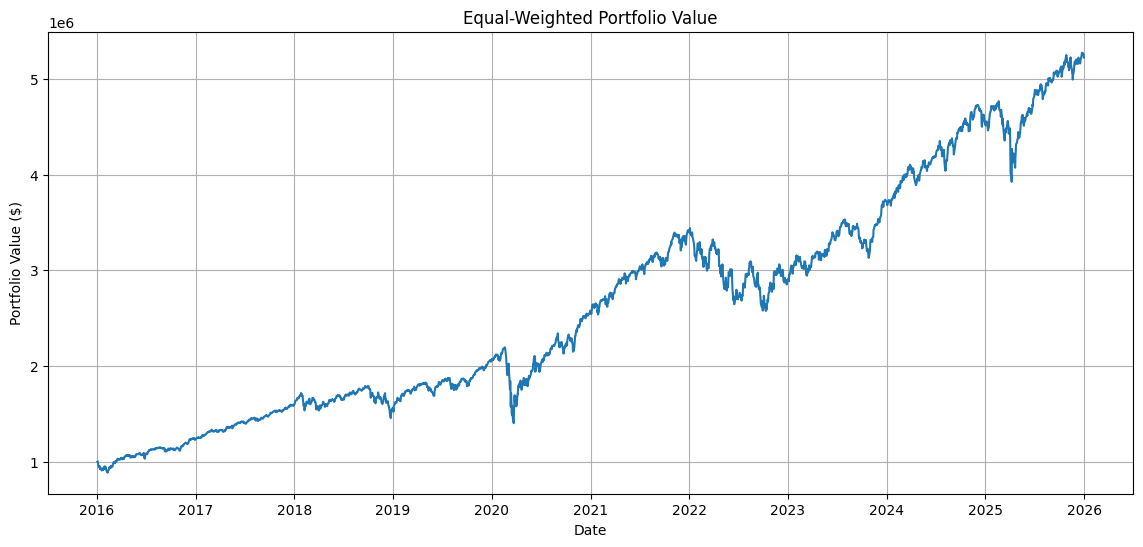

In [30]:
# Visualize Portfolio Value
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
plt.plot(portfolio_value)

plt.title("Equal-Weighted Portfolio Value")
plt.xlabel("Date")
plt.ylabel("Portfolio Value ($)")
plt.grid(True)
plt.show()

In [31]:
portfolio_value.to_csv("equal_weight_portfolio_value.csv")
print("Portfolio value saved successfully.")

Portfolio value saved successfully.


In [32]:
# Compute Daily Portfolio Profit & Loss (P&L)

# Calculate the daily change in portfolio value
portfolio_pnl = portfolio_value.diff()

# Replace the first missing value with zero
portfolio_pnl.iloc[0] = 0

# Rename the Series
portfolio_pnl.name ="Daily P&L"

portfolio_pnl.head()

2016-01-04         0.00
2016-01-05     1,899.41
2016-01-06   -14,088.66
2016-01-07   -27,861.24
2016-01-08   -12,737.73
Name: Daily P&L, dtype: float64

In [33]:
print(f"\nLargest Daily Profit : ${portfolio_pnl.max():,.2f}")
print(f"Largest Daily Loss : ${portfolio_pnl.min():,.2f}")


Largest Daily Profit : $343,965.41
Largest Daily Loss : $-262,129.85


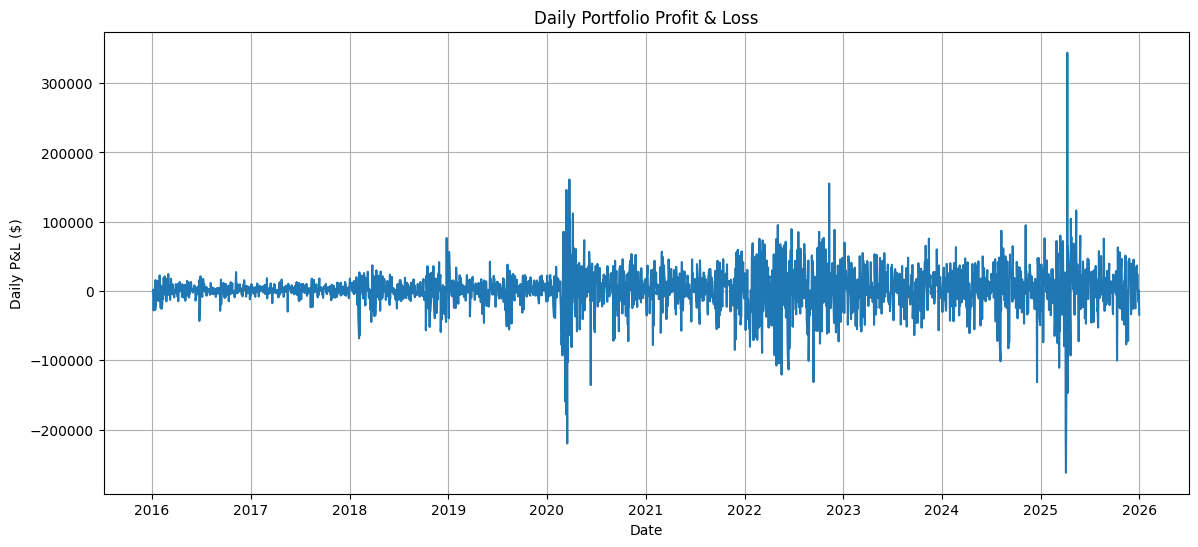

In [34]:
# Visualize Daily Portfolio P&L

plt.figure(figsize=(14,6))
plt.plot(portfolio_pnl)

plt.title("Daily Portfolio Profit & Loss")
plt.xlabel("Date")
plt.ylabel("Daily P&L ($)")
plt.grid(True)
plt.show()

In [35]:
portfolio_pnl.to_csv("equal_weight_portfolio_pnl.csv")
print("Daily portfolio P&L saved successfully.")

Daily portfolio P&L saved successfully.


In [36]:
annual_return = portfolio_return_series.mean() * 252
annual_volatility = portfolio_return_series.std() * np.sqrt(252)

total_return = (
    portfolio_value.iloc[-1] / initial_portfolio_value - 1
) * 100

print("=" * 70)
print("PORTFOLIO PERFORMANCE SUMMARY")
print("=" * 70)

print(f"Initial Investment      : ${initial_portfolio_value:,.2f}")
print(f"Final Portfolio Value   : ${portfolio_value.iloc[-1]:,.2f}")
print(f"Total Return            : {total_return:.2f}%")
print(f"Annualized Return       : {annual_return:.2%}")
print(f"Annualized Volatility   : {annual_volatility:.2%}")
print(f"Best Daily Return       : {portfolio_return_series.max():.2%}")
print(f"Worst Daily Return      : {portfolio_return_series.min():.2%}")

PORTFOLIO PERFORMANCE SUMMARY
Initial Investment      : $1,000,000.00
Final Portfolio Value   : $5,225,243.59
Total Return            : 422.52%
Annualized Return       : 16.58%
Annualized Volatility   : 18.70%
Best Daily Return       : 10.87%
Worst Daily Return      : -13.69%


# **Phase 4: Historical Simulation VaR**

In [37]:
# Load portfolio prices
portfolio_return_series = pd.read_csv(
    "equal_weight_portfolio_returns.csv",
    index_col=0,
    parse_dates=True
)

portfolio_pnl = pd.read_csv(
    "equal_weight_portfolio_pnl.csv",
    index_col=0,
    parse_dates=True
)

In [38]:
pd.set_option("display.float_format", "{:.6f}".format)

print(portfolio_return_series.head())

print("\n")

# Basic information about the return series
print(f"Number of observations : {len(portfolio_return_series)}")
print(f"Start Date : {portfolio_return_series.index.min().date()}")
print(f"End Date : {portfolio_return_series.index.max().date()}")

# Check for missing observations
print(f"\nMissing Values : {portfolio_return_series.isna().sum()}")

# Check whether the return series is ready for VaR analysis
if portfolio_return_series.isna().sum().sum() == 0:
    print("\nPortfolio return series is ready for Historical Simulation VaR.")
else:
    print("\nMissing values detected. Clean the data before proceeding.")
    

            Portfolio Return
Date                        
2016-01-05          0.001898
2016-01-06         -0.014162
2016-01-07         -0.028610
2016-01-08         -0.013358
2016-01-11         -0.002087


Number of observations : 2513
Start Date : 2016-01-05
End Date : 2025-12-31

Missing Values : Portfolio Return    0
dtype: int64

Portfolio return series is ready for Historical Simulation VaR.


In [39]:
# Explore The Portfolio Return Distribution

# Display summary statistics
print(portfolio_return_series.describe())

portfolio_return_series = portfolio_return_series.squeeze()

print("\n")

# Calculate additional statistics
print(f"Mean Return : {portfolio_return_series.mean():.6f}")
print(f"Standard Deviation : {portfolio_return_series.std():.6f}")
print(f"Minimum Return : {portfolio_return_series.min():.6f}")
print(f"Maximum Return : {portfolio_return_series.max():.6f}")
print(f"Skewness : {portfolio_return_series.skew():.4f}")
print(f"Kurtosis: {portfolio_return_series.kurtosis():.4f}")

       Portfolio Return
count       2513.000000
mean           0.000658
std            0.011777
min           -0.136941
25%           -0.003662
50%            0.001008
75%            0.006045
max            0.108666


Mean Return : 0.000658
Standard Deviation : 0.011777
Minimum Return : -0.136941
Maximum Return : 0.108666
Skewness : -0.8490
Kurtosis: 19.3020


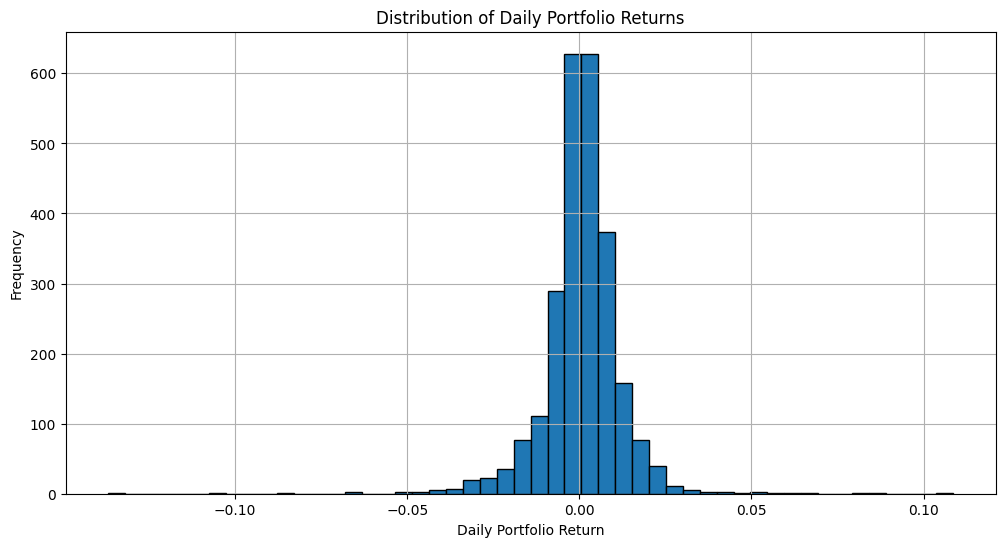

In [40]:
# Histogram of Portfolio Returns

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))

plt.hist(
    portfolio_return_series,
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Daily Portfolio Returns")
plt.xlabel("Daily Portfolio Return")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [41]:
# Construct Portfolio P&L Distribution

# Display summary statistics
print(portfolio_pnl.describe())

portfolio_pnl = portfolio_pnl.squeeze()

print("\n")

# Display key statistics
print(f"Average Daily P&L : ${portfolio_pnl.mean():,.2f}")
print(f"Daily P&L Std Dev : ${portfolio_pnl.std():,.2f}")
print(f"Largest Daily Gain : ${portfolio_pnl.max():,.2f}")
print(f"Largest Daily Loss : ${portfolio_pnl.min():,.2f}")

           Daily P&L
count    2514.000000
mean     1680.685598
std     29776.621028
min   -262129.852695
25%     -8971.048240
50%      1893.654173
75%     14547.688522
max    343965.410958


Average Daily P&L : $1,680.69
Daily P&L Std Dev : $29,776.62
Largest Daily Gain : $343,965.41
Largest Daily Loss : $-262,129.85


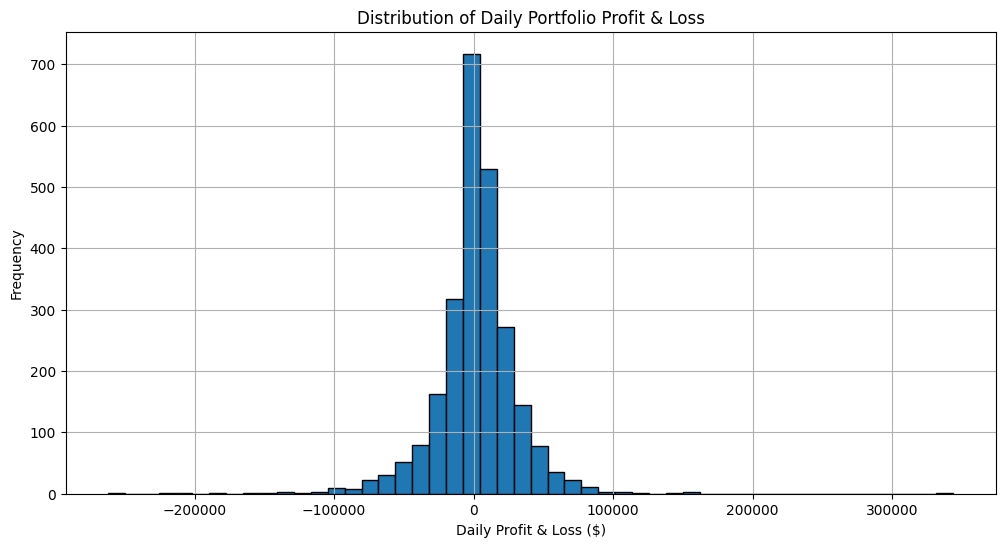

In [42]:
# Histogram of Daily Portfolio P&L

plt.figure(figsize=(12,6))

plt.hist(
    portfolio_pnl,
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Daily Portfolio Profit & Loss")
plt.xlabel("Daily Profit & Loss ($)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [43]:
# Historical Simulation VaR (250-Day Window)

# Define rolling window
rolling_window = 250

# Calculate rolling Historical VaR
historical_var_250_95 = portfolio_return_series.rolling(window=rolling_window).quantile(0.05)
historical_var_250_99 = portfolio_return_series.rolling(window=rolling_window).quantile(0.01)
historical_var_250_995 = portfolio_return_series.rolling(window=rolling_window).quantile(0.005)

# Rename the series
historical_var_250_95.name = "VaR 95%"
historical_var_250_99.name = "VaR 99%"
historical_var_250_995.name = "VaR 99.5%"

In [44]:
print("\nFirst Available VaR Estimates\n")

var_summary = pd.concat(
    [historical_var_250_95,
     historical_var_250_99,
     historical_var_250_995],
    axis=1
)

print(var_summary.dropna().head())


First Available VaR Estimates

             VaR 95%   VaR 99%  VaR 99.5%
Date                                     
2016-12-29 -0.014164 -0.028141  -0.028822
2016-12-30 -0.014164 -0.028141  -0.028822
2017-01-03 -0.013803 -0.028141  -0.028822
2017-01-04 -0.013268 -0.026874  -0.028587
2017-01-05 -0.013149 -0.026874  -0.028587


In [45]:
# Historical Simulation VaR (500-Day & 750-Day Windows)

# 500-Day Historical VaR
historical_var_500_95 = portfolio_return_series.rolling(window=500).quantile(0.05)
historical_var_500_99 = portfolio_return_series.rolling(window=500).quantile(0.01)
historical_var_500_995 = portfolio_return_series.rolling(window=500).quantile(0.005)

# 750-Day Historical VaR
historical_var_750_95 = portfolio_return_series.rolling(window=750).quantile(0.05)
historical_var_750_99 = portfolio_return_series.rolling(window=750).quantile(0.01)
historical_var_750_995 = portfolio_return_series.rolling(window=750).quantile(0.005)

In [46]:
# Combine all Historical VaR Series
historical_var = pd.DataFrame({

    "250-Day VaR (95%)": historical_var_250_95,
    "250-Day VaR (99%)": historical_var_250_99,
    "250-Day VaR (99.5%)": historical_var_250_995,

    "500-Day VaR (95%)": historical_var_500_95,
    "500-Day VaR (99%)": historical_var_500_99,
    "500-Day VaR (99.5%)": historical_var_500_995,

    "750-Day VaR (95%)": historical_var_750_95,
    "750-Day VaR (99%)": historical_var_750_99,
    "750-Day VaR (99.5%)": historical_var_750_995

})

print(historical_var.dropna().head())


            250-Day VaR (95%)  250-Day VaR (99%)  250-Day VaR (99.5%)  \
Date                                                                    
2018-12-26          -0.020849          -0.033958            -0.039120   
2018-12-27          -0.020849          -0.033958            -0.039120   
2018-12-28          -0.020849          -0.033958            -0.039120   
2018-12-31          -0.020849          -0.033958            -0.039120   
2019-01-02          -0.020849          -0.033958            -0.039120   

            500-Day VaR (95%)  500-Day VaR (99%)  500-Day VaR (99.5%)  \
Date                                                                    
2018-12-26          -0.015853          -0.030237            -0.033947   
2018-12-27          -0.015853          -0.030237            -0.033947   
2018-12-28          -0.015853          -0.030237            -0.033947   
2018-12-31          -0.015853          -0.030237            -0.033947   
2019-01-02          -0.015853          -0.030237  

In [47]:
historical_var.to_csv("historical_simulation_var.csv")
print("Historical Simulation VaR saved successfully.")

Historical Simulation VaR saved successfully.


In [48]:
# Historical Expected Shortfall (ES)

# Function to calculate Historical Expected Shortfall
def historical_expected_shortfall(returns, confidence_level):

    # Historical VaR threshold
    var = returns.quantile(1 - confidence_level)

    # Average return beyong the VaR threshold
    es = returns[returns <= var].mean()

    return es

In [49]:
# 250-Day Expected Shortfall

historical_es_250_95 = portfolio_return_series.rolling(250).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.95)
)

historical_es_250_99 = portfolio_return_series.rolling(250).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.99)
)

historical_es_250_995 = portfolio_return_series.rolling(250).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.995)
)

# 500-Day Expected Shortfall

historical_es_500_95 = portfolio_return_series.rolling(500).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.95)
)

historical_es_500_99 = portfolio_return_series.rolling(500).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.99)
)

historical_es_500_995 = portfolio_return_series.rolling(500).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.995)
)

# 750-Day Expected Shortfall

historical_es_750_95 = portfolio_return_series.rolling(750).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.95)
)

historical_es_750_99 = portfolio_return_series.rolling(750).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.99)
)

historical_es_750_995 = portfolio_return_series.rolling(750).apply(
    lambda x: historical_expected_shortfall(pd.Series(x), 0.995)
)

# Combine Expected Shortfall Series
historical_es = pd.DataFrame({

    "250-Day ES (95%)": historical_es_250_95,
    "250-Day ES (99%)": historical_es_250_99,
    "250-Day ES (99.5%)": historical_es_250_995,

    "500-Day ES (95%)": historical_es_500_95,
    "500-Day ES (99%)": historical_es_500_99,
    "500-Day ES (99.5%)": historical_es_500_995,

    "750-Day ES (95%)": historical_es_750_95,
    "750-Day ES (99%)": historical_es_750_99,
    "750-Day ES (99.5%)": historical_es_750_995

})

print(historical_es.dropna().head())

            250-Day ES (95%)  250-Day ES (99%)  250-Day ES (99.5%)  \
Date                                                                 
2018-12-26         -0.029048         -0.039235           -0.041329   
2018-12-27         -0.029048         -0.039235           -0.041329   
2018-12-28         -0.029048         -0.039235           -0.041329   
2018-12-31         -0.029048         -0.039235           -0.041329   
2019-01-02         -0.029048         -0.039235           -0.041329   

            500-Day ES (95%)  500-Day ES (99%)  500-Day ES (99.5%)  \
Date                                                                 
2018-12-26         -0.024127         -0.036378           -0.039235   
2018-12-27         -0.024127         -0.036378           -0.039235   
2018-12-28         -0.024127         -0.036378           -0.039235   
2018-12-31         -0.024127         -0.036378           -0.039235   
2019-01-02         -0.024127         -0.036378           -0.039235   

            750-Da

In [50]:
historical_es.to_csv("historical_expected_shortfall.csv")
print("Historical Expected Shortfall saved successfully.")

Historical Expected Shortfall saved successfully.


In [51]:
# Create Rolling VaR Time Series

# Combine all rolling VaR estimates into a single DataFrame

rolling_var = historical_var.copy()
rolling_var.dropna().head()

,250-Day VaR (95%),250-Day VaR (99%),250-Day VaR (99.5%),500-Day VaR (95%),500-Day VaR (99%),500-Day VaR (99.5%),750-Day VaR (95%),750-Day VaR (99%),750-Day VaR (99.5%)
Date,,,,,,,,,
2018-12-26,-0.020849,-0.033958,-0.039120,-0.015853,-0.030237,-0.033947,-0.015377,-0.028754,-0.033391
2018-12-27,-0.020849,-0.033958,-0.039120,-0.015853,-0.030237,-0.033947,-0.015377,-0.028754,-0.033391
2018-12-28,-0.020849,-0.033958,-0.039120,-0.015853,-0.030237,-0.033947,-0.015377,-0.028754,-0.033391
2018-12-31,-0.020849,-0.033958,-0.039120,-0.015853,-0.030237,-0.033947,-0.015164,-0.028393,-0.033391
2019-01-02,-0.020849,-0.033958,-0.039120,-0.015853,-0.030237,-0.033947,-0.015164,-0.028393,-0.033391


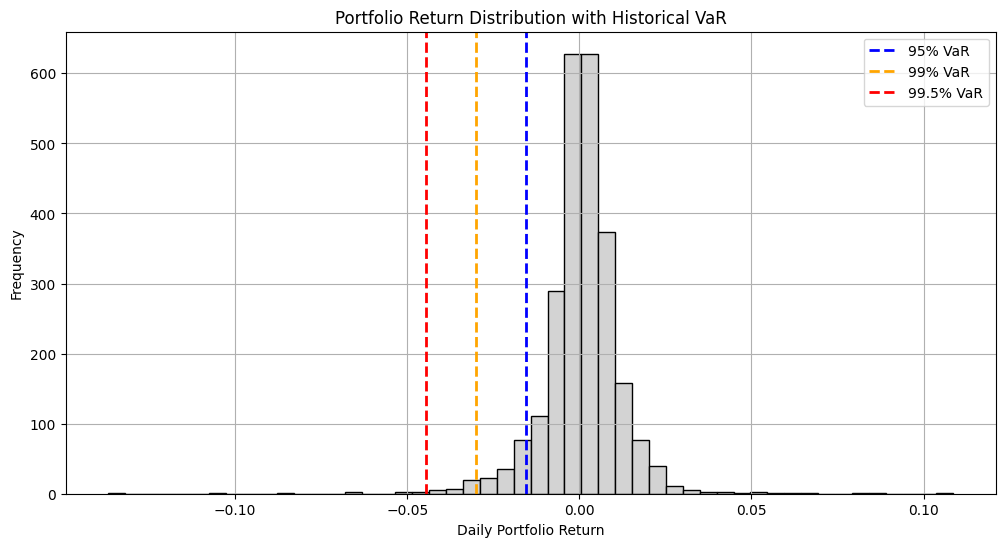

In [52]:
# Return Distribution with VaR Threshold

plt.figure(figsize=(12,6))

plt.hist(
    portfolio_return_series,
    bins=50,
    edgecolor="black",
    color="lightgray"
)

# Latest VaR estimates
latest_var95 = historical_var_250_95.dropna().iloc[-1]
latest_var99 = historical_var_250_99.dropna().iloc[-1]
latest_var995 = historical_var_250_995.dropna().iloc[-1]

plt.axvline(
    latest_var95,
    color="blue",
    linestyle="--",
    linewidth=2,
    label="95% VaR"
)

plt.axvline(
    latest_var99,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="99% VaR"
)

plt.axvline(
    latest_var995,
    color="red",
    linestyle="--",
    linewidth=2,
    label="99.5% VaR"
)

plt.title("Portfolio Return Distribution with Historical VaR")
plt.xlabel("Daily Portfolio Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

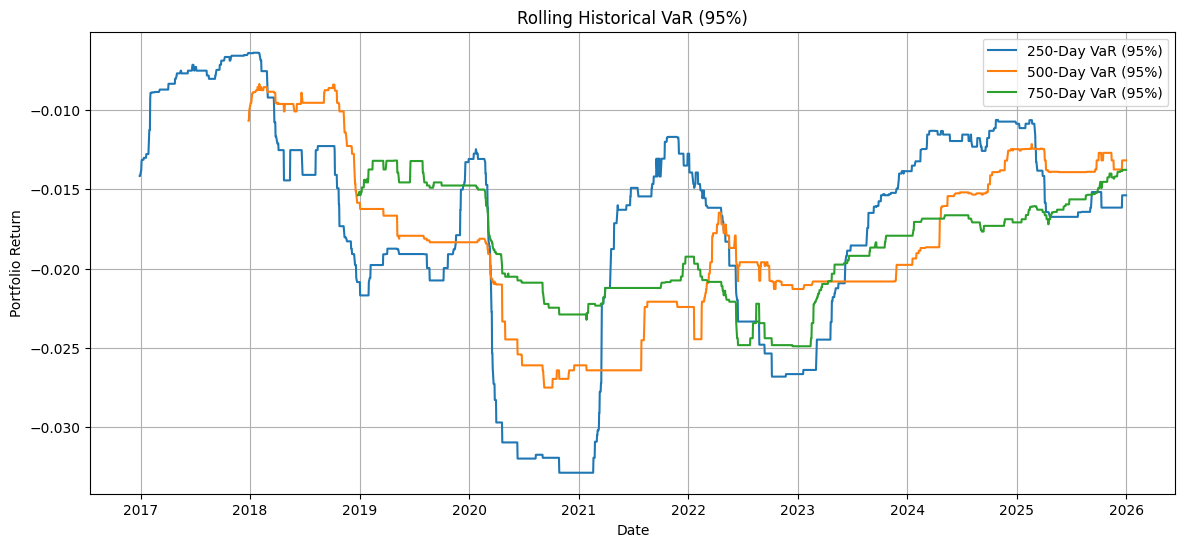

In [53]:
# Rolling VaR Time Series

plt.figure(figsize=(14,6))

plt.plot(
    historical_var_250_95,
    label="250-Day VaR (95%)"
)

plt.plot(
    historical_var_500_95,
    label="500-Day VaR (95%)"
)

plt.plot(
    historical_var_750_95,
    label="750-Day VaR (95%)"
)

plt.title("Rolling Historical VaR (95%)")
plt.xlabel("Date")
plt.ylabel("Portfolio Return")

plt.legend()

plt.grid(True)

plt.show()

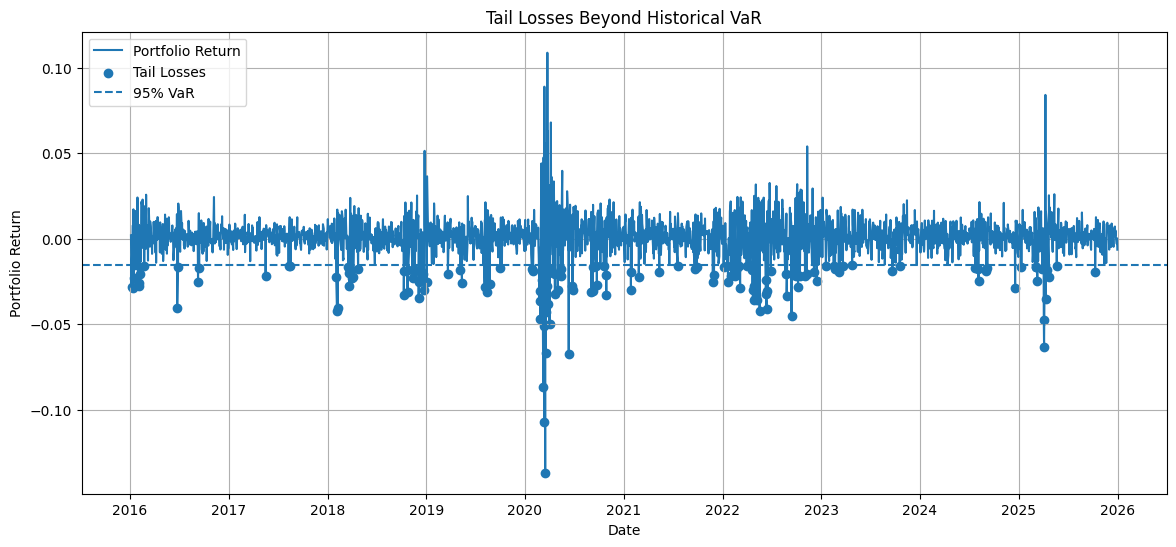

In [54]:
# Tail Loss Visualization

tail_losses = portfolio_return_series[
    portfolio_return_series <= latest_var95
]

plt.figure(figsize=(14,6))

plt.plot(
    portfolio_return_series,
    label="Portfolio Return"
)

plt.scatter(
    tail_losses.index,
    tail_losses,
    label="Tail Losses"
)

plt.axhline(
    latest_var95,
    linestyle="--",
    label="95% VaR"
)

plt.title("Tail Losses Beyond Historical VaR")
plt.xlabel("Date")
plt.ylabel("Portfolio Return")
plt.legend()
plt.grid(True)

plt.show()

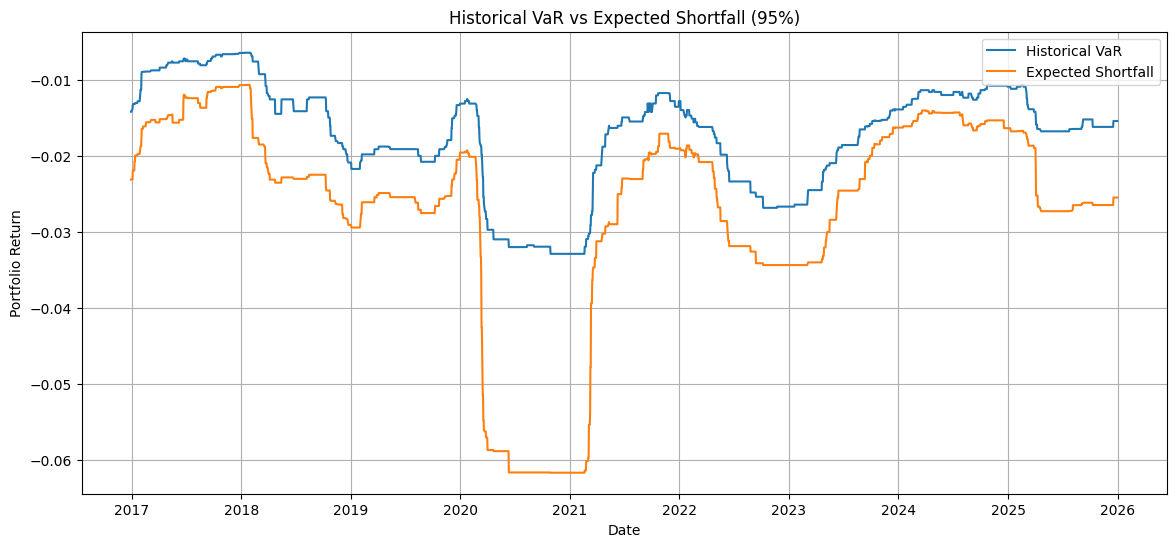

In [55]:
# VaR VS Expected Shortfall

comparison = pd.DataFrame({

    "VaR 95%": historical_var_250_95,
    "ES 95%": historical_es_250_95

})

plt.figure(figsize=(14,6))

plt.plot(
    comparison["VaR 95%"],
    label="Historical VaR"
)

plt.plot(
    comparison["ES 95%"],
    label="Expected Shortfall"
)

plt.title("Historical VaR vs Expected Shortfall (95%)")
plt.xlabel("Date")
plt.ylabel("Portfolio Return")
plt.legend()
plt.grid(True)

plt.show()

# **Phase 5: EWMA Volatility Scaling**

In [56]:
# Prepare Portfolio Returns for EWMA
portfolio_return_series = pd.read_csv(
    "equal_weight_portfolio_returns.csv",
    index_col=0,
    parse_dates=True
)

portfolio_return_series = portfolio_return_series.squeeze()

In [57]:
# Calculate EWMA Variance

# EWMA decay factor
lambda_ewma = 0.94

# Create an empty Series to store EWMA variance
ewma_variance = pd.Series(
    index=portfolio_return_series.index,
    dtype=float
)

# Use the first observed return variance as the initial variance
ewma_variance.iloc[0] = portfolio_return_series.iloc[0] ** 2

# Calculate EWMA variance recursively
for t in range(1, len(portfolio_return_series)):

    # Yesterday's variance receives lambda weight
    # Yesterday's squared return receives (1 - lambda) weight
    ewma_variance.iloc[t] = (
        lambda_ewma * ewma_variance.iloc[t-1]
        + (1 - lambda_ewma) * portfolio_return_series.iloc[t-1] ** 2
    )

# Naming the Series
ewma_variance.name = "EWMA Variance"

pd.set_option("display.float_format", "{:.6f}".format)

# Display the first few observations
print(ewma_variance.head())

Date
2016-01-05   0.000004
2016-01-06   0.000004
2016-01-07   0.000015
2016-01-08   0.000064
2016-01-11   0.000070
Name: EWMA Variance, dtype: float64


In [58]:
# Calculate EWMA Volatility

# Take the square root of EWMA variance
ewma_volatility = np.sqrt(ewma_variance)

# Naming the Series
ewma_volatility.name = "EWMA Volatility"

print(ewma_volatility.head())

Date
2016-01-05   0.001898
2016-01-06   0.001898
2016-01-07   0.003927
2016-01-08   0.007975
2016-01-11   0.008396
Name: EWMA Volatility, dtype: float64


In [59]:
# Display EWMA volatility as percentages
print((ewma_volatility * 100).head())

Date
2016-01-05   0.189760
2016-01-06   0.189760
2016-01-07   0.392660
2016-01-08   0.797537
2016-01-11   0.839621
Name: EWMA Volatility, dtype: float64


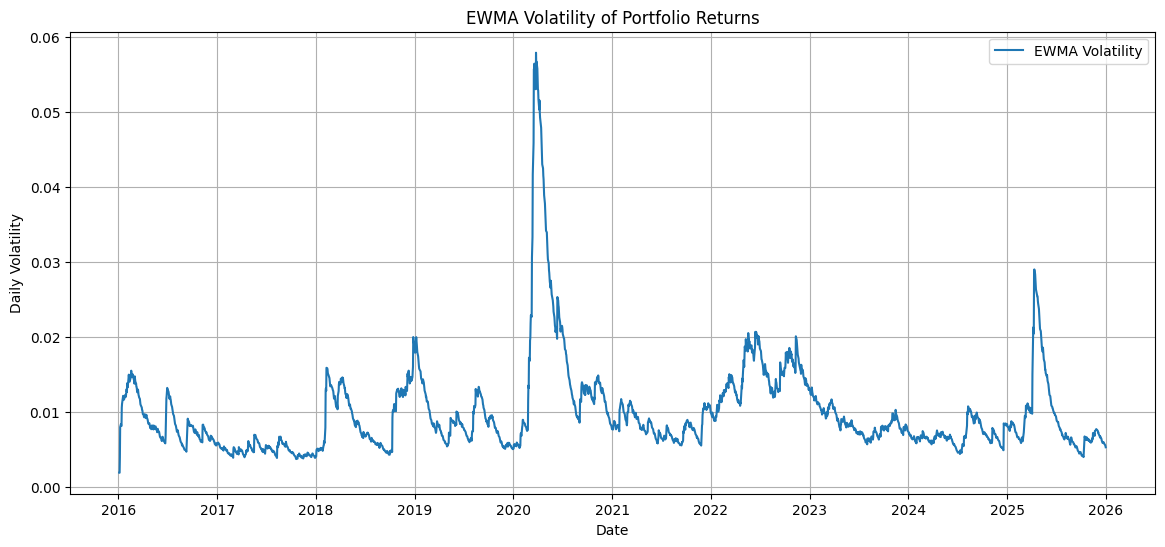

In [60]:
# EWMA Volatility Chart

plt.figure(figsize=(14,6))

plt.plot(
    ewma_volatility,
    label="EWMA Volatility"
)

plt.title("EWMA Volatility of Portfolio Returns")
plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.legend()
plt.grid(True)

plt.show()

In [61]:
# Save EWMA Results
ewma_results = pd.DataFrame({
    "Portfolio Return": portfolio_return_series,
    "EWMA Variance": ewma_variance,
    "EWMA Volatility": ewma_volatility
})

ewma_results.to_csv("ewma_volatility_results.csv")
print("EWMA variance and volatility saved successfully.")

EWMA variance and volatility saved successfully.


In [62]:
# Scale Historical Returns by Current EWMA Volatility

# Get the most recent EWMA volatility
current_ewma_volatility = ewma_volatility.iloc[-1]

print(f"Current EWMA Volatility : {current_ewma_volatility:.6f}")
print(f"Current EWMA Volatility : {current_ewma_volatility:.2%}")

Current EWMA Volatility : 0.005293
Current EWMA Volatility : 0.53%


In [63]:
# Calculate volatility-scaled historcial returns
volatility_scaled_returns = (
    portfolio_return_series
    * (current_ewma_volatility / ewma_volatility)
)

# Naming the Series
volatility_scaled_returns.name = "Volatility Scaled Return"

print(volatility_scaled_returns.head())

Date
2016-01-05    0.005293
2016-01-06   -0.039501
2016-01-07   -0.038566
2016-01-08   -0.008865
2016-01-11   -0.001316
Name: Volatility Scaled Return, dtype: float64


In [64]:
# Compare Raw Returns with Volatility-Scaled Returns
return_comparison = pd.DataFrame({
    "Raw Return": portfolio_return_series,
    "EWMA Volatility": ewma_volatility,
    "Volatility Scaled Return": volatility_scaled_returns
})

print(return_comparison.head(10))

            Raw Return  EWMA Volatility  Volatility Scaled Return
Date                                                             
2016-01-05    0.001898         0.001898                  0.005293
2016-01-06   -0.014162         0.001898                 -0.039501
2016-01-07   -0.028610         0.003927                 -0.038566
2016-01-08   -0.013358         0.007975                 -0.008865
2016-01-11   -0.002087         0.008396                 -0.001316
2016-01-12    0.007791         0.008156                  0.005056
2016-01-13   -0.028891         0.008135                 -0.018798
2016-01-14    0.017092         0.010597                  0.008538
2016-01-15   -0.023054         0.011094                 -0.010999
2016-01-19   -0.001079         0.012148                 -0.000470


In [65]:
# Summary Statistics - Raw vs Volatility-Scaled Returns
comparison_summary = pd.DataFrame({
    "Raw Returns": portfolio_return_series.describe(),
    "Volatility Scaled Returns": volatility_scaled_returns.describe()
})

print(comparison_summary)

       Raw Returns  Volatility Scaled Returns
count  2513.000000                2513.000000
mean      0.000658                   0.000352
std       0.011777                   0.005694
min      -0.136941                  -0.039501
25%      -0.003662                  -0.002299
50%       0.001008                   0.000647
75%       0.006045                   0.003960
max       0.108666                   0.021750


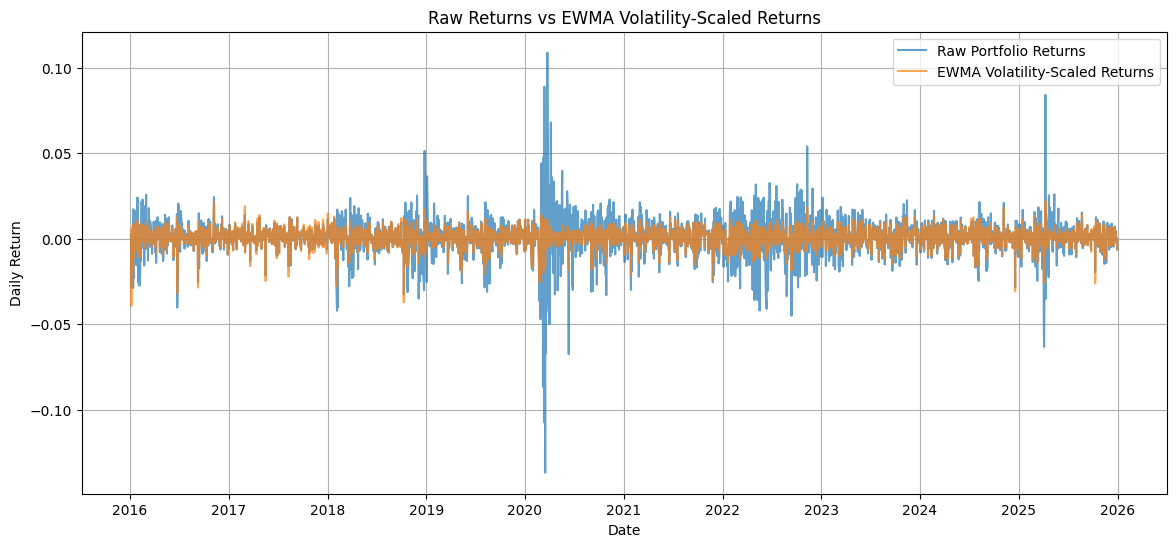

In [66]:
plt.figure(figsize=(14,6))

plt.plot(
    portfolio_return_series,
    label="Raw Portfolio Returns",
    alpha=0.7
)

plt.plot(
    volatility_scaled_returns,
    label="EWMA Volatility-Scaled Returns",
    alpha=0.7
)

plt.title("Raw Returns vs EWMA Volatility-Scaled Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend()
plt.grid(True)
plt.show()

In [67]:
# Save Volatility-Scaled Returns
return_comparison.to_csv(
    "volatility_scaled_returns.csv"
)

print("Volatility-scaled return data saved successfully.")

Volatility-scaled return data saved successfully.


In [68]:
# Volatility-Scaled Historical VaR

# Calculate VaR thresholds from the volatility-scaled returns
ewma_var_95 = volatility_scaled_returns.quantile(0.05)
ewma_var_99 = volatility_scaled_returns.quantile(0.01)
ewma_var_995 = volatility_scaled_returns.quantile(0.005)

print(f"95% VaR : {ewma_var_95:.4%}")
print(f"99% VaR : {ewma_var_99:.4%}")
print(f"99.5% VaR : {ewma_var_995:.4%}")

95% VaR : -0.9157%
99% VaR : -1.7018%
99.5% VaR : -2.2255%


In [69]:
# Historical VaR vs EWMA-Scaled VaR

var_comparison = pd.DataFrame({
    "Historical VaR": [
        historical_var_250_95.dropna().iloc[-1],
        historical_var_250_99.dropna().iloc[-1],
        historical_var_250_995.dropna().iloc[-1]
    ],
    
    "EWMA-Scaled VaR": [
        ewma_var_95,
        ewma_var_99,
        ewma_var_995
    ]
}, index=[
    "95%",
    "99%",
    "99.5%"
])

print(var_comparison)

       Historical VaR  EWMA-Scaled VaR
95%         -0.015382        -0.009157
99%         -0.030006        -0.017018
99.5%       -0.044585        -0.022255


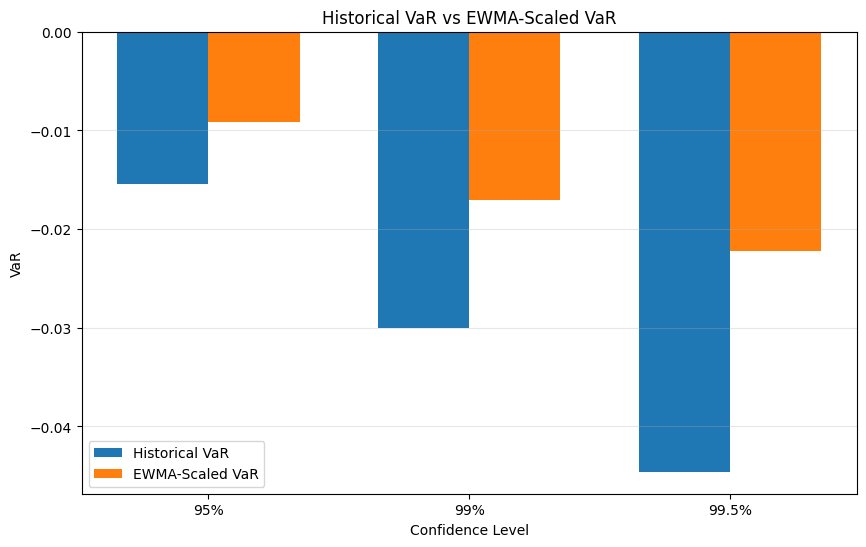

In [70]:
plt.figure(figsize=(10, 6))
x = np.arange(len(var_comparison.index))
width = 0.35

plt.bar(
    x - width / 2,
    var_comparison["Historical VaR"],
    width,
    label="Historical VaR"
)

plt.bar(
    x + width / 2,
    var_comparison["EWMA-Scaled VaR"],
    width,
    label="EWMA-Scaled VaR"
)

plt.xticks(
    x,
    var_comparison.index
)

plt.title("Historical VaR vs EWMA-Scaled VaR")
plt.xlabel("Confidence Level")
plt.ylabel("VaR")
plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [71]:
var_comparison.to_csv("historical_vs_ewma_var.csv")
print("Historical vs EWMA-scaled VaR comparison saved successfully.")

Historical vs EWMA-scaled VaR comparison saved successfully.


In [72]:
# Calculate VaR Exceptions

# Latest EWMA-scaled VaR
ewma_var_threshold = ewma_var_95

# Latest Historical Simulation VaR
historical_var_threshold = historical_var_250_95.dropna().iloc[-1]

print(f"Historical 95% VaR : {historical_var_threshold:.4%}")
print(f"EWMA 95% VaR       : {ewma_var_threshold:.4%}")

Historical 95% VaR : -1.5382%
EWMA 95% VaR       : -0.9157%


In [73]:
# Rolling EWMA-Scaled VaR

def calculate_ewma_scaled_var(returns, ewma_volatility, confidence_level):
    
    scaled_var = pd.Series(
        index=returns.index,
        dtype=float
    )
    
    for t in range(1, len(returns)):
        
        current_volatility = ewma_volatility.iloc[t]
        
        # Scale all historical returns available up to yesterday
        historical_returns = returns.iloc[:t]
        historical_volatility = ewma_volatility.iloc[:t]
        
        scaled_returns = (
            historical_returns
            * (current_volatility / historical_volatility)
        )
        
        scaled_var.iloc[t] = scaled_returns.quantile(
            1 - confidence_level
        )
    
    return scaled_var

In [74]:
# Calculate Rolling EWMA VaR

ewma_rolling_var_95 = calculate_ewma_scaled_var(
    portfolio_return_series,
    ewma_volatility,
    0.95
)

ewma_rolling_var_99 = calculate_ewma_scaled_var(
    portfolio_return_series,
    ewma_volatility,
    0.99
)

ewma_rolling_var_995 = calculate_ewma_scaled_var(
    portfolio_return_series,
    ewma_volatility,
    0.995
)

In [75]:
# Exception Comparison

# Historical Simulation VaR from Phase 4
historical_rolling_var_95 = historical_var_250_95

# Historical VaR exceptions
historical_exceptions = (
    portfolio_return_series < historical_rolling_var_95
)

# EWMA VaR exceptions
ewma_exceptions = (
    portfolio_return_series < ewma_rolling_var_95
)

# Remove observations where VaR is not available
exception_data = pd.DataFrame({
    "Portfolio Return": portfolio_return_series,
    "Historical VaR": historical_rolling_var_95,
    "EWMA VaR": ewma_rolling_var_95,
    "Historical Exception": historical_exceptions,
    "EWMA Exception": ewma_exceptions
}).dropna()

print(
    f"Historical VaR Exceptions : "
    f"{exception_data['Historical Exception'].sum()}"
)

print(
    f"EWMA VaR Exceptions       : "
    f"{exception_data['EWMA Exception'].sum()}"
)

Historical VaR Exceptions : 120
EWMA VaR Exceptions       : 128


In [76]:
# Calculate Exception Rates

historical_exception_rate = (
    exception_data["Historical Exception"].mean()
)

ewma_exception_rate = (
    exception_data["EWMA Exception"].mean()
)

print(
    f"Expected Exception Rate : 5.00%"
)

print(
    f"Historical VaR Rate     : "
    f"{historical_exception_rate:.2%}"
)

print(
    f"EWMA VaR Rate           : "
    f"{ewma_exception_rate:.2%}"
)

Expected Exception Rate : 5.00%
Historical VaR Rate     : 5.30%
EWMA VaR Rate           : 5.65%


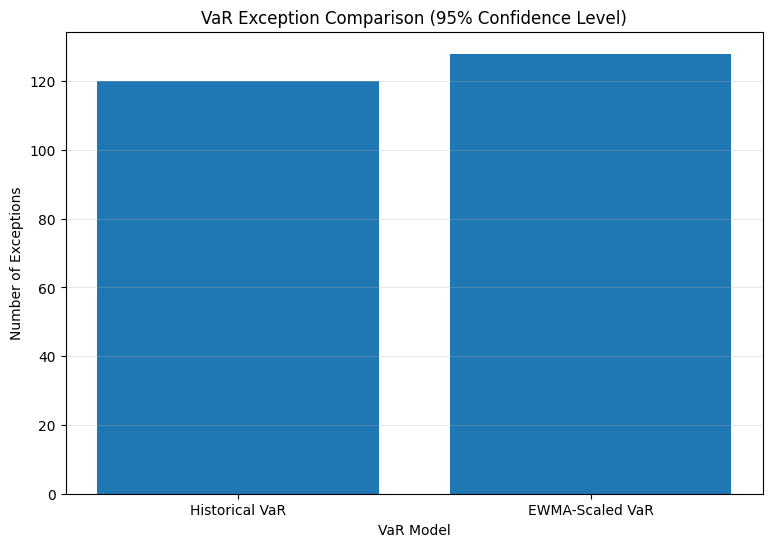

In [77]:
# Exception Comparison Chart

exception_counts = [
    exception_data["Historical Exception"].sum(),
    exception_data["EWMA Exception"].sum()
]

labels = [
    "Historical VaR",
    "EWMA-Scaled VaR"
]

plt.figure(figsize=(9, 6))
plt.bar(
    labels,
    exception_counts
)

plt.title("VaR Exception Comparison (95% Confidence Level)")
plt.xlabel("VaR Model")
plt.ylabel("Number of Exceptions")
plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [78]:
# Validate EWMA Results

# Check EWMA variance
print("\nEWMA Variance")
print(f"Minimum : {ewma_variance.min():.10f}")
print(f"Maximum : {ewma_variance.max():.10f}")
print(f"Missing : {ewma_variance.isna().sum()}")

# Check EWMA Volatility
print("\nEWMA Volatility")
print(f"Minimum : {ewma_volatility.min():.6f}")
print(f"Maximum : {ewma_volatility.max():.6f}")
print(f"Missing : {ewma_volatility.isna().sum()}")

# Check volatility-scaled returns
print("\nVolatility-Scaled Returns")
print(f"Minimum : {volatility_scaled_returns.min():.6f}")
print(f"Maximum : {volatility_scaled_returns.max():.6f}")
print(f"Missing : {volatility_scaled_returns.isna().sum()}")
print(f"Infinite : {np.isinf(volatility_scaled_returns).sum()}")

# Check VaR ordering
print("\nVaR Ordering")
print(f"95% VaR : {ewma_var_95:.4%}")
print(f"99% VaR : {ewma_var_99:.4%}")
print(f"99.5% VaR : {ewma_var_995:.4%}")

# Check whether VaR ordering is logical
if(
    ewma_var_95 > ewma_var_99
    and ewma_var_99 > ewma_var_995
):
    print("\nVaR ordering is correct.")
else:
    print("\nWarning: Check VaR calculations.")


EWMA Variance
Minimum : 0.0000036009
Maximum : 0.0033524093
Missing : 0

EWMA Volatility
Minimum : 0.001898
Maximum : 0.057900
Missing : 0

Volatility-Scaled Returns
Minimum : -0.039501
Maximum : 0.021750
Missing : 0
Infinite : 0

VaR Ordering
95% VaR : -0.9157%
99% VaR : -1.7018%
99.5% VaR : -2.2255%

VaR ordering is correct.


In [79]:
# Phase 5 Summary
phase5_summary = pd.DataFrame({
    "Metric": [
        "EWMA Lambda",
        "Current EWMA Volatility",
        "EWMA-Scaled VaR 95%",
        "EWMA-Scaled VaR 99%",
        "EWMA-Scaled VaR 99.5%",
        "Historical VaR Exceptions",
        "EWMA VaR Exceptions",
        "Historical Exception Rate",
        "EWMA Exception Rate"
    ],
    
    "Value": [
        lambda_ewma,
        current_ewma_volatility,
        ewma_var_95,
        ewma_var_99,
        ewma_var_995,
        exception_data["Historical Exception"].sum(),
        exception_data["EWMA Exception"].sum(),
        historical_exception_rate,
        ewma_exception_rate
    ]
})

print("=" * 70)
print("PHASE 5 - EWMA SUMMARY")
print("=" * 70)

print(phase5_summary)

PHASE 5 - EWMA SUMMARY
                      Metric      Value
0                EWMA Lambda   0.940000
1    Current EWMA Volatility   0.005293
2        EWMA-Scaled VaR 95%  -0.009157
3        EWMA-Scaled VaR 99%  -0.017018
4      EWMA-Scaled VaR 99.5%  -0.022255
5  Historical VaR Exceptions 120.000000
6        EWMA VaR Exceptions 128.000000
7  Historical Exception Rate   0.053004
8        EWMA Exception Rate   0.056537


# **Phase 6: GARCH Volatility Scaling**

In [80]:
# Import GARCH Model
from arch import arch_model

In [81]:
# Convert decimal returns into percentage returns
garch_returns = portfolio_return_series * 100

# Naming the Series
garch_returns.name = "Portfolio Return (%)"

print(garch_returns.head())
print("\nMean Return :", f"{garch_returns.mean():.4f}%")
print("Std Dev :", f"{garch_returns.std():.4f}%")

Date
2016-01-05    0.189760
2016-01-06   -1.416175
2016-01-07   -2.861044
2016-01-08   -1.335799
2016-01-11   -0.208744
Name: Portfolio Return (%), dtype: float64

Mean Return : 0.0658%
Std Dev : 1.1777%


In [82]:
garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

In [83]:
garch_fit = garch_model.fit(
    disp="off"
)

print(garch_fit.summary())

                      Constant Mean - GARCH Model Results                       
Dep. Variable:     Portfolio Return (%)   R-squared:                       0.000
Mean Model:               Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GARCH   Log-Likelihood:               -3278.87
Distribution:                    Normal   AIC:                           6565.74
Method:              Maximum Likelihood   BIC:                           6589.06
                                          No. Observations:                 2513
Date:                  Fri, Oct 09 2026   Df Residuals:                     2512
Time:                          22:19:11   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1010  1.531e-02      6.601  4

In [84]:
# Extract GARCH Parameters
omega = garch_fit.params["omega"]
alpha = garch_fit.params["alpha[1]"]
beta = garch_fit.params["beta[1]"]

persistence = alpha + beta

print(f"Omega (ω)       : {omega:.6f}")
print(f"Alpha (α)       : {alpha:.6f}")
print(f"Beta (β)        : {beta:.6f}")
print(f"α + β           : {persistence:.6f}")

Omega (ω)       : 0.038749
Alpha (α)       : 0.172195
Beta (β)        : 0.797457
α + β           : 0.969652


In [85]:
# Extract GARCH Conditional Volatility
garch_conditional_volatility = garch_fit.conditional_volatility
garch_conditional_volatility.name = "GARCH Conditional Volatility"

print(garch_conditional_volatility.head())

Date
2016-01-05   1.557402
2016-01-06   1.405112
2016-01-07   1.417599
2016-01-08   1.775429
2016-01-11   1.705272
Name: GARCH Conditional Volatility, dtype: float64


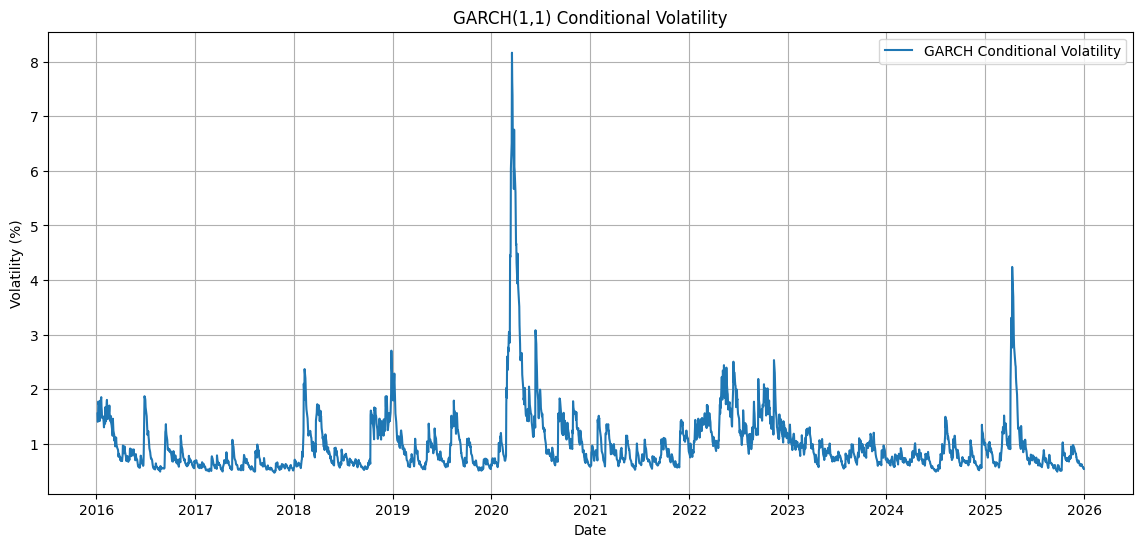

In [86]:
# GARCH Conditional Volatility Chart
plt.figure(figsize=(14,6))

plt.plot(
    garch_conditional_volatility,
    label="GARCH Conditional Volatility"
)

plt.title("GARCH(1,1) Conditional Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")

plt.legend()
plt.grid(True)

plt.show()

In [87]:
# Forecast 1-Day-Ahead Garch Volatility

# Generate a one-day-ahead forecast
garch_forecast = garch_fit.forecast(horizon=1)

# Extract the forecasted variance
forecast_variance = garch_forecast.variance.iloc[-1, 0]

# Convert variance to vlatility
forecast_volatility = np.sqrt(forecast_variance)

print(f"Forecast Variance : {forecast_variance:.6f}")
print(f"Forecast Volatility : {forecast_volatility:.4f}%")

Forecast Variance : 0.371486
Forecast Volatility : 0.6095%


In [88]:
# Create 1-Day-Ahead GARCH Forecast Volatility Series
garch_forecast_all = garch_fit.forecast(
    horizon=1,
    start=0,
    reindex=True
)

# Extract one-day-ahead variance forecasts
garch_forecast_variance = garch_forecast_all.variance["h.1"]

# Convert variance forecasts to volatility
garch_forecast_volatility = np.sqrt(
    garch_forecast_variance
)

garch_forecast_volatility.name = "GARCH Forecast Volatility"

print(garch_forecast_volatility.dropna().head())

Date
2016-01-05   1.413255
2016-01-06   1.424040
2016-01-07   1.779535
2016-01-08   1.708682
2016-01-11   1.543867
Name: GARCH Forecast Volatility, dtype: float64


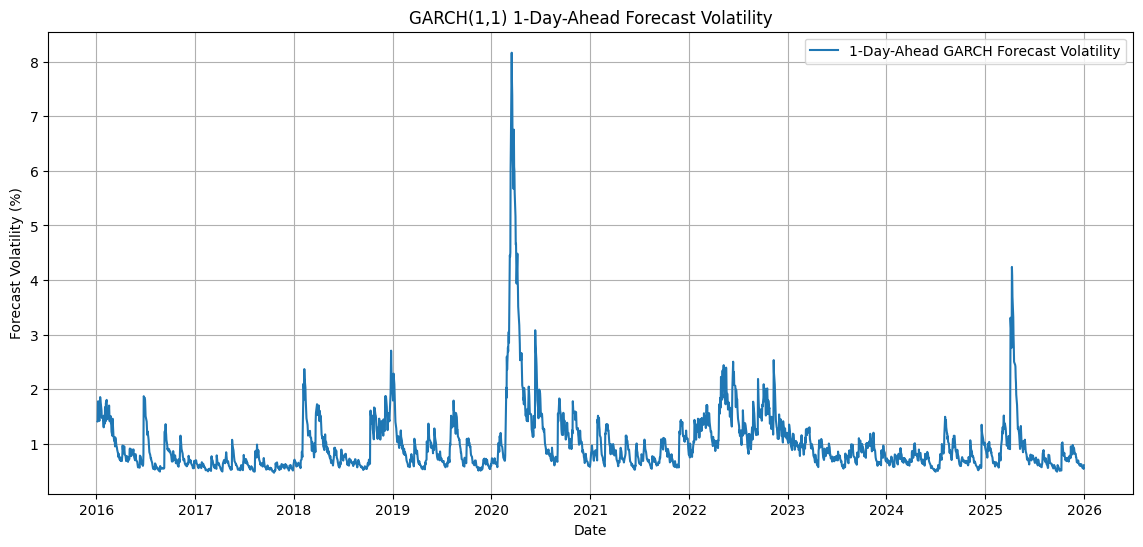

In [89]:
# GARCH Forecast Volatility Chart
plt.figure(figsize=(14,6))

plt.plot(
    garch_forecast_volatility,
    label="1-Day-Ahead GARCH Forecast Volatility"
)

plt.title("GARCH(1,1) 1-Day-Ahead Forecast Volatility")
plt.xlabel("Date")
plt.ylabel("Forecast Volatility (%)")

plt.legend()
plt.grid(True)
plt.show()

In [90]:
# Scale Historical Returns using GARCH Volatility

# Align returns and conditional volatility
garch_scaling_data = pd.concat(
    [
        garch_returns,
        garch_conditional_volatility
    ],
    axis=1
).dropna()

# Scale historical returns to current forecast volatility
garch_scaled_returns = (
    garch_scaling_data["Portfolio Return (%)"]
    * (
        forecast_volatility
        / garch_scaling_data["GARCH Conditional Volatility"]
    )
)

garch_scaled_returns.name = "GARCH Scaled Return"

print(garch_scaled_returns.head())

print("\nMinimum :", f"{garch_scaled_returns.min():.4f}%")
print("Maximum :", f"{garch_scaled_returns.max():.4f}%")
print("Missing :", garch_scaled_returns.isna().sum())

Date
2016-01-05    0.074264
2016-01-06   -0.614296
2016-01-07   -1.230106
2016-01-08   -0.458574
2016-01-11   -0.074609
Name: GARCH Scaled Return, dtype: float64

Minimum : -3.2112%
Maximum : 2.3411%
Missing : 0


In [91]:
# GARCH-Scaled Historical VaR

garch_var_95 = garch_scaled_returns.quantile(0.05)
garch_var_99 = garch_scaled_returns.quantile(0.01)
garch_var_995 = garch_scaled_returns.quantile(0.005)

print(f"95% VaR : {garch_var_95:.4f}%")
print(f"99% VaR : {garch_var_99:.4f}%")
print(f"99.5% VaR : {garch_var_995:.4f}%")

95% VaR : -1.0480%
99% VaR : -1.7191%
99.5% VaR : -2.1473%


In [92]:
# Historical VaR Vs GARCH-Scaled VaR

garch_var_comparison = pd.DataFrame({

    "Historical VaR":[
        historical_var_250_95.dropna().iloc[-1],
        historical_var_250_99.dropna().iloc[-1],
        historical_var_250_995.dropna().iloc[-1]
    ],

    "GARCH-Scaled VaR":[
        garch_var_95 / 100,
        garch_var_99 / 100,
        garch_var_995 / 100
    ]

}, index=["95%", "99%", "99.5%"])

print(garch_var_comparison)

       Historical VaR  GARCH-Scaled VaR
95%         -0.015382         -0.010480
99%         -0.030006         -0.017191
99.5%       -0.044585         -0.021473


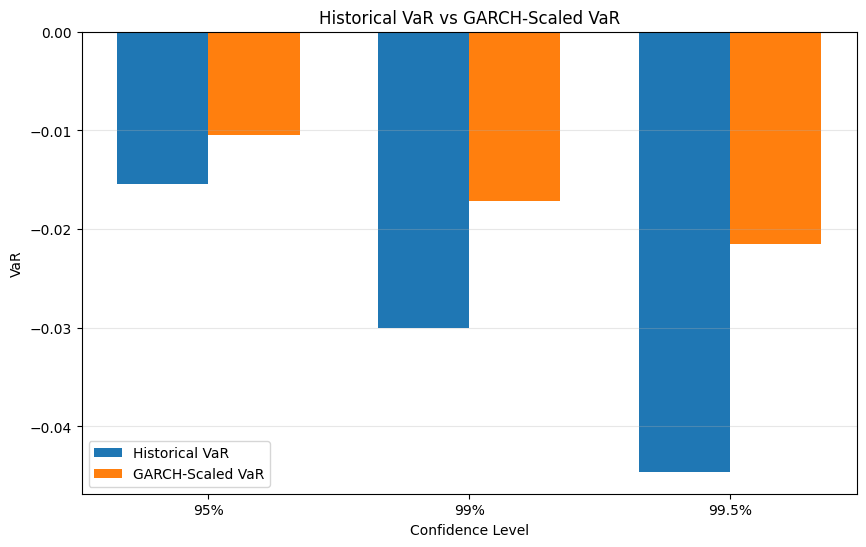

In [93]:
# Historical VaR Vs GARCH-Scaled VaR Chart

plt.figure(figsize=(10,6))

x = np.arange(len(garch_var_comparison.index))
width = 0.35

plt.bar(
    x - width/2,
    garch_var_comparison["Historical VaR"],
    width,
    label="Historical VaR"
)

plt.bar(
    x + width/2,
    garch_var_comparison["GARCH-Scaled VaR"],
    width,
    label="GARCH-Scaled VaR"
)

plt.xticks(x, garch_var_comparison.index)
plt.title("Historical VaR vs GARCH-Scaled VaR")
plt.xlabel("Confidence Level")
plt.ylabel("VaR")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [94]:
# Extract standardized residuals from the fitted GARCH model
garch_standardized_residuals = garch_fit.std_resid.dropna()

garch_standardized_residuals.name = "GARCH Standardized Residual"
print(garch_standardized_residuals.head())

print("\nMean :", f"{garch_standardized_residuals.mean():.6f}")
print("Std Dev :", f"{garch_standardized_residuals.std():.6f}")
print("Minimum :", f"{garch_standardized_residuals.min():.6f}")
print("Maximum :", f"{garch_standardized_residuals.max():.6f}")
print("Missing :", garch_standardized_residuals.isna().sum())

Date
2016-01-05    0.056961
2016-01-06   -1.079789
2016-01-07   -2.089514
2016-01-08   -0.809296
2016-01-11   -0.181668
Name: GARCH Standardized Residual, dtype: float64

Mean : -0.047561
Std Dev : 0.999399
Minimum : -5.380300
Maximum : 3.769062
Missing : 0


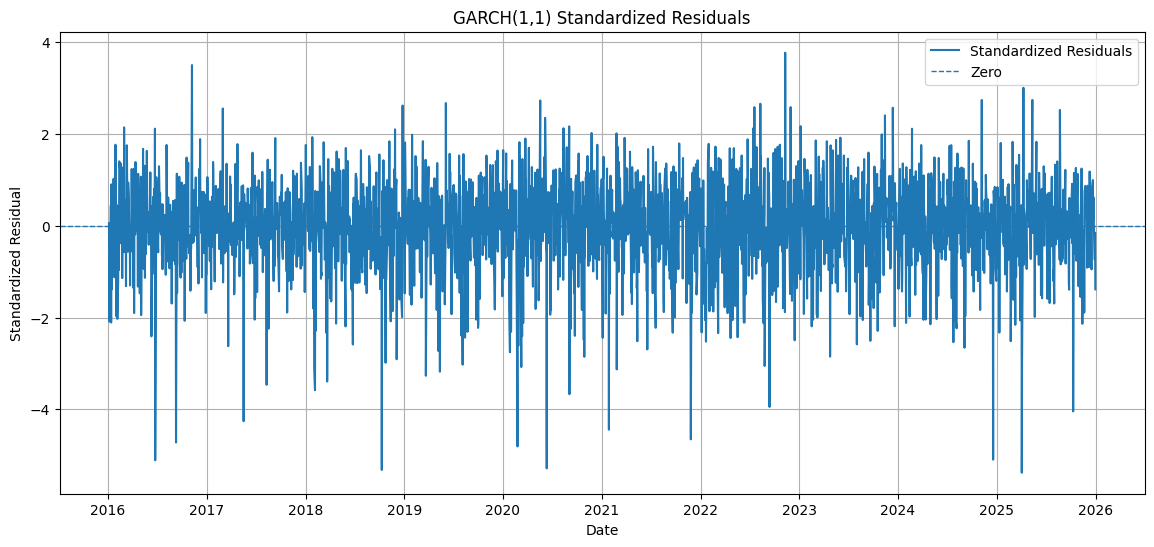

In [95]:
# GARCH Standardized Residuals Chart

plt.figure(figsize=(14,6))
plt.plot(
    garch_standardized_residuals,
    label="Standardized Residuals"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    label="Zero"
)

plt.title("GARCH(1,1) Standardized Residuals")
plt.xlabel("Date")
plt.ylabel("Standardized Residual")

plt.legend()
plt.grid(True)
plt.show()

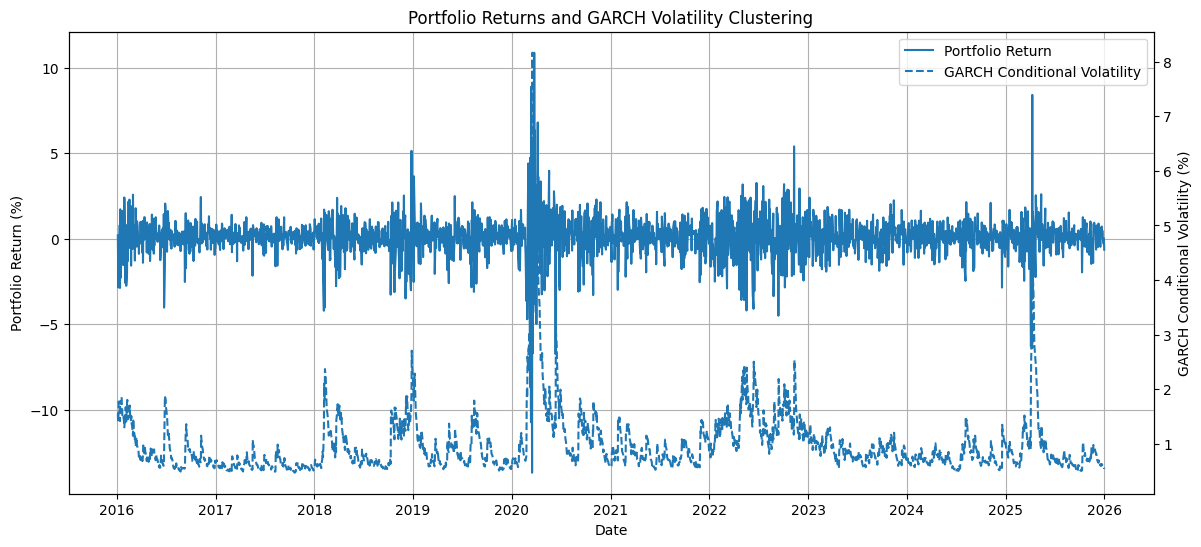

In [96]:
# Volatility Clustering Chart

fig, ax1 = plt.subplots(figsize=(14,6))

# Portfolio returns
ax1.plot(
    portfolio_return_series * 100,
    label="Portfolio Return"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Portfolio Return (%)")

# GARCH conditional volatility
ax2 = ax1. twinx()

ax2.plot(
    garch_conditional_volatility,
    linestyle="--",
    linewidth=1.5,
    label="GARCH Conditional Volatility"
)

ax2.set_ylabel("GARCH Conditional Volatility (%)")

plt.title("Portfolio Returns and GARCH Volatility Clustering")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

ax1.grid(True)
plt.show()


In [97]:
# Final GARCH Summary

phase6_summary = pd.DataFrame({
    "Metric": [
        "GARCH Model",
        "Lambda / Persistence (Alpha + Beta)",
        "Alpha",
        "Beta",
        "Final Conditional Volatility",
        "1-Day-Ahead Forecast Volatility",
        "GARCH-Scaled VaR 95%",
        "GARCH-Scaled VaR 99%",
        "GARCH-Scaled VaR 99.5%"
    ],
    
    "Value": [
        "GARCH(1,1)",
        persistence,
        alpha,
        beta,
        garch_conditional_volatility.iloc[-1],
        forecast_volatility,
        garch_var_95,
        garch_var_99,
        garch_var_995
    ]
})

print(phase6_summary)

                                Metric       Value
0                          GARCH Model  GARCH(1,1)
1  Lambda / Persistence (Alpha + Beta)    0.969652
2                                Alpha    0.172195
3                                 Beta    0.797457
4         Final Conditional Volatility    0.543110
5      1-Day-Ahead Forecast Volatility    0.609497
6                 GARCH-Scaled VaR 95%   -1.047979
7                 GARCH-Scaled VaR 99%   -1.719084
8               GARCH-Scaled VaR 99.5%   -2.147325


# **COMPARE HISTORICAL, EWMA AND GARCH VaR**

In [98]:
var_comparison = pd.DataFrame({

    "Historical VaR": [
        historical_var_250_95.dropna().iloc[-1],
        historical_var_250_99.dropna().iloc[-1],
        historical_var_250_995.dropna().iloc[-1]
    ],

    "EWMA-Scaled VaR": [
        ewma_var_95,
        ewma_var_99,
        ewma_var_995
    ],

    "GARCH-Scaled VaR": [
        garch_var_95 / 100,
        garch_var_99 / 100,
        garch_var_995 / 100
    ]

}, index=["95%", "99%", "99.5%"])

print("=" * 70)
print("Comparison of VaR Methods")
print("=" * 70)

print(var_comparison)

Comparison of VaR Methods
       Historical VaR  EWMA-Scaled VaR  GARCH-Scaled VaR
95%         -0.015382        -0.009157         -0.010480
99%         -0.030006        -0.017018         -0.017191
99.5%       -0.044585        -0.022255         -0.021473


In [99]:
# VaR Loss Magnitude
var_magnitude = var_comparison.abs()

print(var_magnitude)

       Historical VaR  EWMA-Scaled VaR  GARCH-Scaled VaR
95%          0.015382         0.009157          0.010480
99%          0.030006         0.017018          0.017191
99.5%        0.044585         0.022255          0.021473


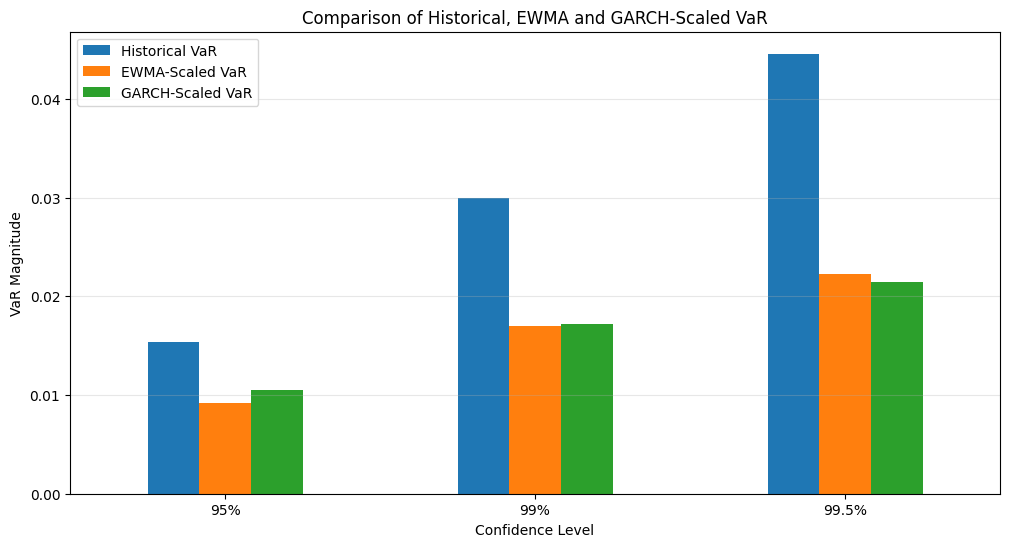

In [100]:
# VaR Method Comparison Chart

var_magnitude.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Comparison of Historical, EWMA and GARCH-Scaled VaR")
plt.xlabel("Confidence Level")
plt.ylabel("VaR Magnitude")

plt.xticks(rotation=0)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()
plt.show()

# **Phase 7: GJR-GARCH Volatility Scaling**

In [101]:
from arch import arch_model

gjr_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="normal"
)

gjr_fit = gjr_model.fit(disp="off")
print(gjr_fit.summary())

                    Constant Mean - GJR-GARCH Model Results                     
Dep. Variable:     Portfolio Return (%)   R-squared:                       0.000
Mean Model:               Constant Mean   Adj. R-squared:                  0.000
Vol Model:                    GJR-GARCH   Log-Likelihood:               -3252.51
Distribution:                    Normal   AIC:                           6515.02
Method:              Maximum Likelihood   BIC:                           6544.17
                                          No. Observations:                 2513
Date:                  Fri, Oct 09 2026   Df Residuals:                     2512
Time:                          22:19:15   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0696  1.507e-02      4.

In [102]:
# Extract GJR-GARCH leverage effect parameter

gjr_gamma = gjr_fit.params["gamma[1]"]

print(f"Gamma (Leverage Effect): {gjr_gamma:.6f}")

Gamma (Leverage Effect): 0.176586


In [103]:
# GJR-GARCH Conditional Volatility

gjr_conditional_volatility = gjr_fit.conditional_volatility
gjr_conditional_volatility.name = "GJR-GARCH Conditional Volatility"

print(gjr_conditional_volatility.tail())

Date
2025-12-24   0.579562
2025-12-26   0.566251
2025-12-29   0.547201
2025-12-30   0.562204
2025-12-31   0.544011
Name: GJR-GARCH Conditional Volatility, dtype: float64


In [104]:
print(
    f"Final GJR-GARCH Conditional Volatility: "
    f"{gjr_conditional_volatility.iloc[-1]:.4f}%"
)

Final GJR-GARCH Conditional Volatility: 0.5440%


In [105]:
# GJR-GARCH 1-Day-Ahead Volatility Forecast

gjr_forecast_all = gjr_fit.forecast(
    horizon=1,
    start=0,
    reindex=True
)

gjr_forecast_variance = gjr_forecast_all.variance["h.1"]
gjr_forecast_volatility = np.sqrt(gjr_forecast_variance)
gjr_forecast_volatility.name = "GJR-GARCH Forecast Volatility"

forecast_gjr_volatility = gjr_forecast_volatility.dropna().iloc[-1]
print(f"1-Day-Ahead Forecast Volatility: {forecast_gjr_volatility:.6f}%")

1-Day-Ahead Forecast Volatility: 0.632444%


In [106]:
# Scale Historical Returns Using GJR-GARCH Volatility

gjr_scaling_data = pd.concat(
    [
        garch_returns,
        gjr_conditional_volatility
    ],
    axis=1
).dropna()

gjr_scaled_returns = (
    gjr_scaling_data["Portfolio Return (%)"]
    * (
        forecast_gjr_volatility
        / gjr_scaling_data["GJR-GARCH Conditional Volatility"]
    )
)

gjr_scaled_returns.name = "GJR-GARCH Scaled Return"

print(gjr_scaled_returns.describe())

count   2513.000000
mean       0.047133
std        0.632411
min       -4.154045
25%       -0.276801
50%        0.081456
75%        0.454858
max        2.326339
Name: GJR-GARCH Scaled Return, dtype: float64


In [107]:
# GJR-GARCH-Scaled Historical VaR

gjr_var_95 = gjr_scaled_returns.quantile(0.05)
gjr_var_99 = gjr_scaled_returns.quantile(0.01)
gjr_var_995 = gjr_scaled_returns.quantile(0.005)

print("=" * 70)
print("GJR-GARCH-Scaled Historical VaR")
print("=" * 70)

print(f"95% VaR   : {gjr_var_95:.4f}%")
print(f"99% VaR   : {gjr_var_99:.4f}%")
print(f"99.5% VaR : {gjr_var_995:.4f}%")

GJR-GARCH-Scaled Historical VaR
95% VaR   : -1.0592%
99% VaR   : -1.6672%
99.5% VaR : -2.3197%


In [108]:
# GARCH vs GJR-GARCH Conditional Volatility

volatility_comparison = pd.concat(
    [
        garch_conditional_volatility,
        gjr_conditional_volatility
    ],
    axis=1
).dropna()

print(volatility_comparison.tail())

            GARCH Conditional Volatility  GJR-GARCH Conditional Volatility
Date                                                                      
2025-12-24                      0.595753                          0.579562
2025-12-26                      0.587554                          0.566251
2025-12-29                      0.561221                          0.547201
2025-12-30                      0.565439                          0.562204
2025-12-31                      0.543110                          0.544011


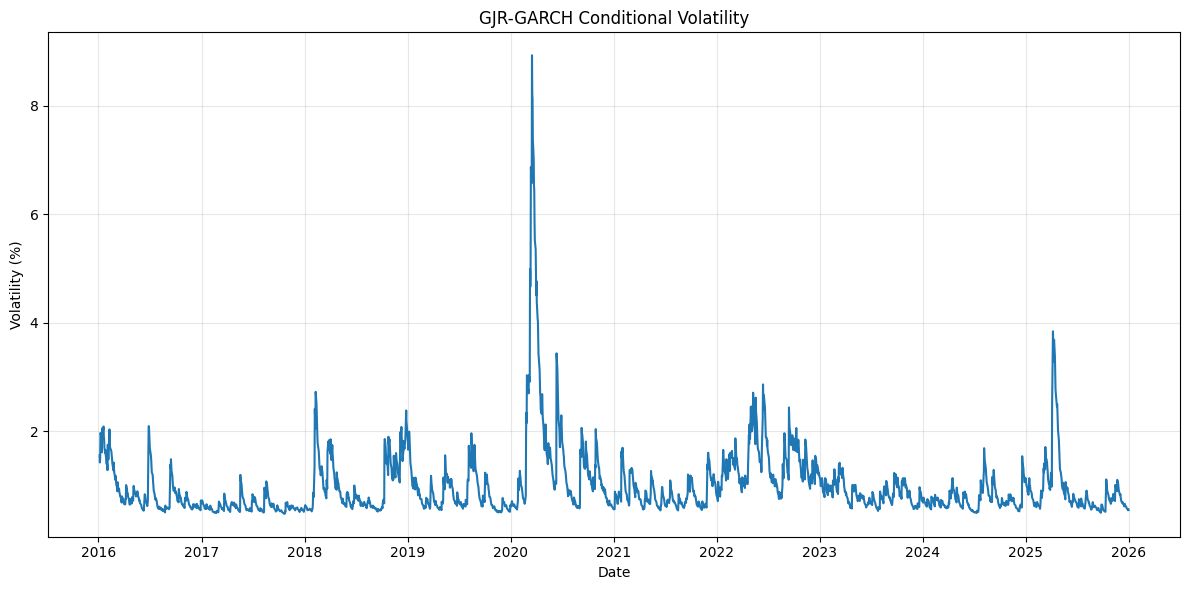

In [109]:
plt.figure(figsize=(12,6))

plt.plot(
    gjr_conditional_volatility.index,
    gjr_conditional_volatility
)

plt.title("GJR-GARCH Conditional Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

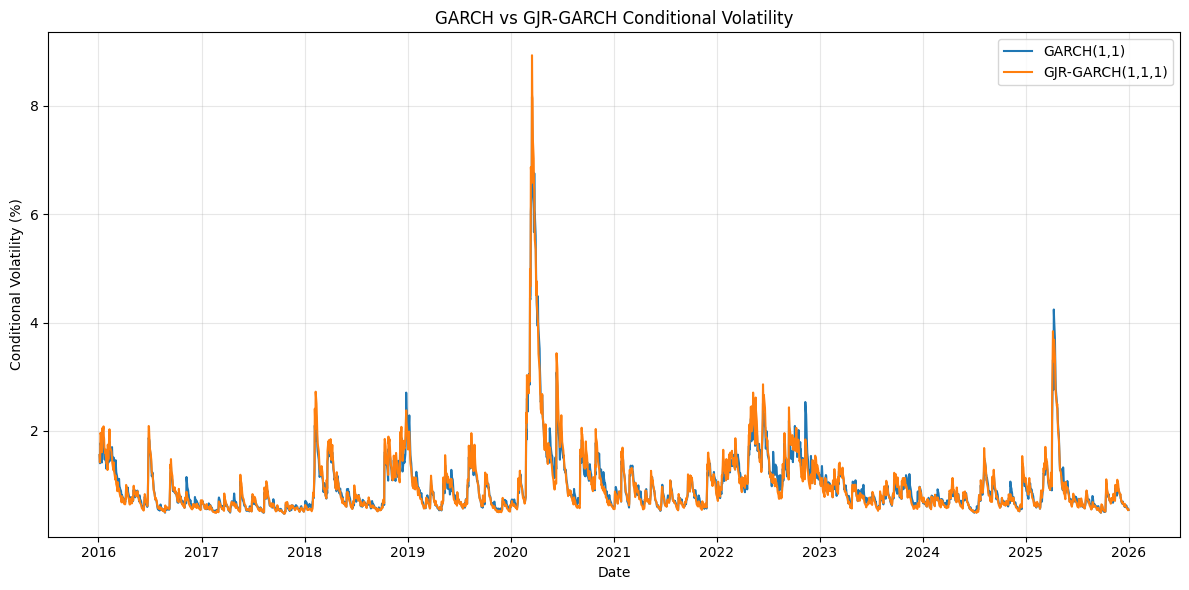

In [110]:
plt.figure(figsize=(12,6))

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GARCH Conditional Volatility"],
    label="GARCH(1,1)"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GJR-GARCH Conditional Volatility"],
    label="GJR-GARCH(1,1,1)"
)

plt.title("GARCH vs GJR-GARCH Conditional Volatility")
plt.xlabel("Date")
plt.ylabel("Conditional Volatility (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [111]:
# Prepare Actual Shocks and Next-Day Volatility

gjr_shocks = gjr_fit.resid

# Shift conditional volatility backward so that each shock
# is matched with the following day's volatility
gjr_next_day_volatility = gjr_conditional_volatility.shift(-1)

# Combine shocks and next-day volatility
leverage_data = pd.concat(
    [
        gjr_shocks.rename("Shock"),
        gjr_next_day_volatility.rename("Next Day Volatility")
    ],
    axis=1
).dropna()

# Calculate absolute shock magnitude
leverage_data["Absolute Shock"] = leverage_data["Shock"].abs()

# Classify shocks as negative or positive
leverage_data["Shock Type"] = np.where(
    leverage_data["Shock"] < 0,
    "Negative Shock",
    "Positive Shock"
)

leverage_data.head()

,Shock,Next Day Volatility,Absolute Shock,Shock Type
Date,,,,
2016-01-05,0.120152,1.422095,0.120152,Positive Shock
2016-01-06,-1.485784,1.487585,1.485784,Negative Shock
2016-01-07,-2.930653,1.964116,2.930653,Negative Shock
2016-01-08,-1.405408,1.915117,1.405408,Negative Shock
2016-01-11,-0.278353,1.751808,0.278353,Negative Shock


In [112]:
# Create Shock Magnitude Groups

leverage_data["Shock Magnitude Group"] = pd.qcut(
    leverage_data["Absolute Shock"],
    q=5,
    duplicates="drop"
)

leverage_data.head()

,Shock,Next Day Volatility,Absolute Shock,Shock Type,Shock Magnitude Group
Date,,,,,
2016-01-05,0.120152,1.422095,0.120152,Positive Shock,"(-0.0009617, 0.17]"
2016-01-06,-1.485784,1.487585,1.485784,Negative Shock,"(1.107, 13.764]"
2016-01-07,-2.930653,1.964116,2.930653,Negative Shock,"(1.107, 13.764]"
2016-01-08,-1.405408,1.915117,1.405408,Negative Shock,"(1.107, 13.764]"
2016-01-11,-0.278353,1.751808,0.278353,Negative Shock,"(0.17, 0.365]"


In [113]:
empirical_leverage = (
    leverage_data
    .groupby(
        ["Shock Magnitude Group", "Shock Type"],
        observed=True
    )["Next Day Volatility"]
    .mean()
    .unstack()
)

print(empirical_leverage)

Shock Type             Negative Shock  Positive Shock
Shock Magnitude Group                                
(-0.0009617, 0.17]           0.777584        0.738940
(0.17, 0.365]                0.801316        0.758491
(0.365, 0.652]               0.871669        0.801164
(0.652, 1.107]               1.005555        0.907529
(1.107, 13.764]              1.730594        1.539014


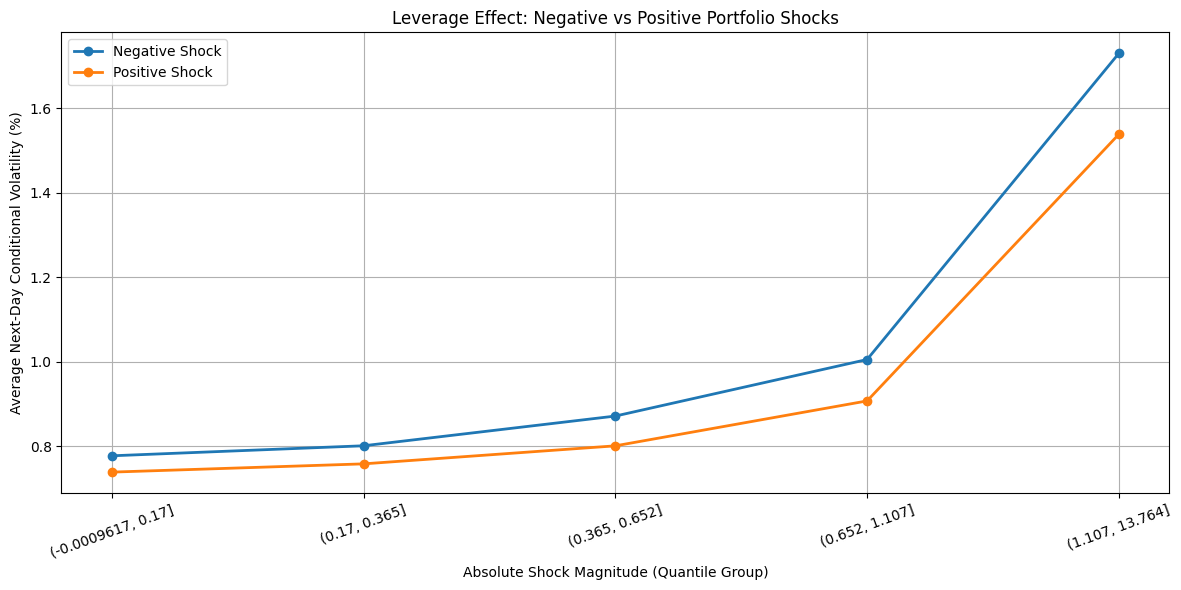

In [114]:
# Leverage Effect Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    empirical_leverage.index.astype(str),
    empirical_leverage["Negative Shock"],
    marker="o",
    linewidth=2,
    label="Negative Shock"
)

plt.plot(
    empirical_leverage.index.astype(str),
    empirical_leverage["Positive Shock"],
    marker="o",
    linewidth=2,
    label="Positive Shock"
)

plt.title("Leverage Effect: Negative vs Positive Portfolio Shocks")
plt.xlabel("Absolute Shock Magnitude (Quantile Group)")
plt.ylabel("Average Next-Day Conditional Volatility (%)")
plt.xticks(rotation=20)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [115]:
# Historical vs GJR-GARCH-Scaled VaR

gjr_var_comparison = pd.DataFrame({

    "Historical VaR": [
        historical_var_250_95.dropna().iloc[-1],
        historical_var_250_99.dropna().iloc[-1],
        historical_var_250_995.dropna().iloc[-1]
    ],

    "GJR-GARCH-Scaled VaR": [
        gjr_var_95 / 100,
        gjr_var_99 / 100,
        gjr_var_995 / 100
    ]

}, index=["95%", "99%", "99.5%"])

print(gjr_var_comparison)        

       Historical VaR  GJR-GARCH-Scaled VaR
95%         -0.015382             -0.010592
99%         -0.030006             -0.016672
99.5%       -0.044585             -0.023197


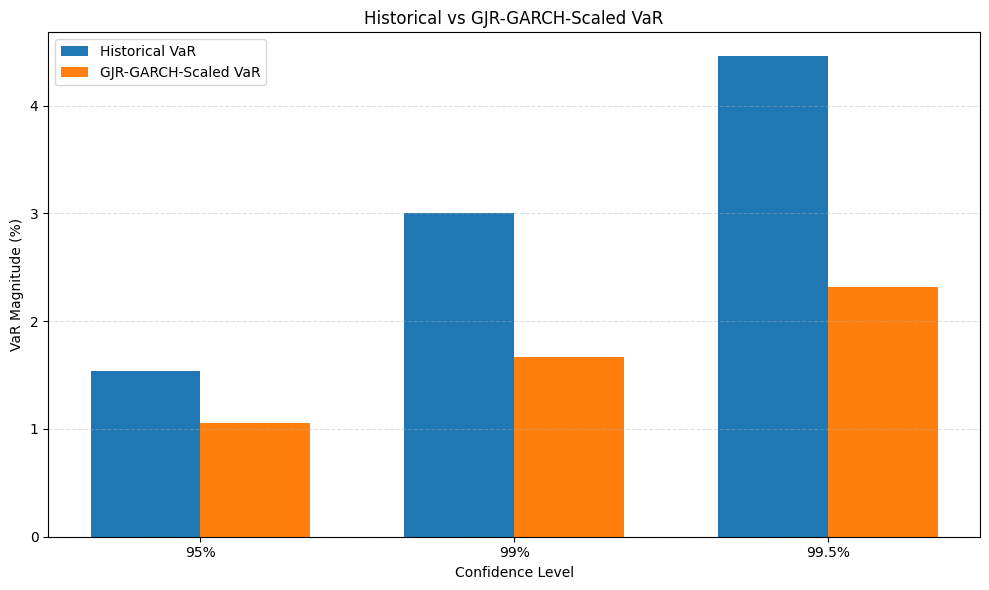

In [116]:
gjr_var_chart = pd.DataFrame({
    "Confidence Level": ["95%", "99%", "99.5%"],
    "Historical VaR": [
        abs(historical_var_250_95.dropna().iloc[-1]) * 100,
        abs(historical_var_250_99.dropna().iloc[-1]) * 100,
        abs(historical_var_250_995.dropna().iloc[-1]) * 100
    ],
    "GJR-GARCH-Scaled VaR": [
        abs(gjr_var_95),
        abs(gjr_var_99),
        abs(gjr_var_995)
    ]
})

x = range(len(gjr_var_chart))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    [i - width/2 for i in x],
    gjr_var_chart["Historical VaR"],
    width,
    label="Historical VaR"
)

plt.bar(
    [i + width/2 for i in x],
    gjr_var_chart["GJR-GARCH-Scaled VaR"],
    width,
    label="GJR-GARCH-Scaled VaR"
)

plt.xticks(list(x), gjr_var_chart["Confidence Level"])
plt.xlabel("Confidence Level")
plt.ylabel("VaR Magnitude (%)")
plt.title("Historical vs GJR-GARCH-Scaled VaR")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [117]:
# Phase 7 Summary

phase7_summary = pd.DataFrame({
    "Metric": [
        "GJR-GARCH Model",
        "Leverage Effect (Gamma)",
        "Alpha",
        "Beta",
        "Final Conditional Volatility",
        "1-Day-Ahead Forecast Volatility",
        "GJR-GARCH-Scaled VaR 95%",
        "GJR-GARCH-Scaled VaR 99%",
        "GJR-GARCH-Scaled VaR 99.5%"
    ],

    "Value": [
        "GJR-GARCH(1,1,1)",
        gjr_gamma,
        gjr_fit.params["alpha[1]"],
        gjr_fit.params["beta[1]"],
        gjr_conditional_volatility.iloc[-1],
        forecast_gjr_volatility,
        gjr_var_95,
        gjr_var_99,
        gjr_var_995
    ]
})

print(phase7_summary)

                            Metric             Value
0                  GJR-GARCH Model  GJR-GARCH(1,1,1)
1          Leverage Effect (Gamma)          0.176586
2                            Alpha          0.056628
3                             Beta          0.822142
4     Final Conditional Volatility          0.544011
5  1-Day-Ahead Forecast Volatility          0.632444
6         GJR-GARCH-Scaled VaR 95%         -1.059166
7         GJR-GARCH-Scaled VaR 99%         -1.667224
8       GJR-GARCH-Scaled VaR 99.5%         -2.319693


# **Phase 8: VaR Backtesting**

In [118]:
# Define Out-of-Sample Backtesting Window

# Number of observations used for initial estimation
estimation_window = 750

# Portfolio returns used for backtesting
backtest_returns = portfolio_return_series.copy()

# Split into estimation and out-of-sample periods
estimation_returns = backtest_returns.iloc[:estimation_window]
oos_returns = backtest_returns.iloc[estimation_window:]

print("Phase 8 - VaR Backtesting Window")

print(f"Total observations       :{len(backtest_returns)}")
print(f"Estimation observations  :{len(estimation_returns)}")
print(f"Backtesting observations :{len(oos_returns)}")

print(f"\nEstimation period:")
print(f"{estimation_returns.index[0].date()} to "
      f"{estimation_returns.index[-1].date()}")

print(f"\nOut-of-sample period:")
print(f"{oos_returns.index[0].date()} to "
      f"{oos_returns.index[-1].date()}")

Phase 8 - VaR Backtesting Window
Total observations       :2513
Estimation observations  :750
Backtesting observations :1763

Estimation period:
2016-01-05 to 2018-12-26

Out-of-sample period:
2018-12-27 to 2025-12-31


In [119]:
# Prepare Historial VaR for OOS Backtesting

# Shift by one day so today's VaR is based only on information
# available before today's return is observed.
historical_var_oos_95 = historical_var_250_95.shift(1)
historical_var_oos_99 = historical_var_250_99.shift(1)
historical_var_oos_995 = historical_var_250_995.shift(1)

# Keep only the out-of-sample backtesting period
historical_var_oos_95 = historical_var_oos_95.loc[oos_returns.index]
historical_var_oos_99 = historical_var_oos_99.loc[oos_returns.index]
historical_var_oos_995 = historical_var_oos_995.loc[oos_returns.index]

print("Historical VaR OOS series prepared.")
print()
print("95% VaR observations  :", historical_var_oos_95.notna().sum())
print("99% VaR observations  :", historical_var_oos_99.notna().sum())
print("99.5% VaR observations:", historical_var_oos_995.notna().sum())

Historical VaR OOS series prepared.

95% VaR observations  : 1763
99% VaR observations  : 1763
99.5% VaR observations: 1763


In [120]:
# Prepare OOS EWMA VaR

# ---------------------------------------------------------
# Step 1: Calculate standardized returns during estimation
# period using the EWMA volatility
# ---------------------------------------------------------

ewma_estimation_volatility = ewma_volatility.iloc[:estimation_window]

ewma_estimation_data = pd.concat(
    [
        backtest_returns.iloc[:estimation_window],
        ewma_estimation_volatility
    ],
    axis=1
).dropna()

ewma_standardized_returns = (
    ewma_estimation_data.iloc[:, 0]
    / ewma_estimation_data.iloc[:, 1]
)

# ---------------------------------------------------------
# Step 2: Estimate the historical distribution of the
# standardized returns using only the estimation period
# ---------------------------------------------------------

ewma_standardized_var_95 = ewma_standardized_returns.quantile(0.05)
ewma_standardized_var_99 = ewma_standardized_returns.quantile(0.01)
ewma_standardized_var_995 = ewma_standardized_returns.quantile(0.005)

# ---------------------------------------------------------
# Step 3: Obtain the EWMA volatility for the OOS period
# ---------------------------------------------------------

ewma_oos_volatility = ewma_volatility.loc[oos_returns.index]

# ---------------------------------------------------------
# Step 4: Convert the standardized VaR into daily
# OOS EWMA VaR forecasts
# ---------------------------------------------------------

ewma_var_oos_95 = (
    ewma_standardized_var_95 * ewma_oos_volatility
)

ewma_var_oos_99 = (
    ewma_standardized_var_99 * ewma_oos_volatility
)

ewma_var_oos_995 = (
    ewma_standardized_var_995 * ewma_oos_volatility
)

print("OOS EWMA VaR series prepared.")
print()
print("95% standardized VaR   :", round(ewma_standardized_var_95, 6))
print("99% standardized VaR   :", round(ewma_standardized_var_99, 6))
print("99.5% standardized VaR :", round(ewma_standardized_var_995, 6))
print()
print("95% VaR observations   :", ewma_var_oos_95.notna().sum())
print("99% VaR observations   :", ewma_var_oos_99.notna().sum())
print("99.5% VaR observations :", ewma_var_oos_995.notna().sum())

OOS EWMA VaR series prepared.

95% standardized VaR   : -1.644734
99% standardized VaR   : -4.033911
99.5% standardized VaR : -5.580984

95% VaR observations   : 1763
99% VaR observations   : 1763
99.5% VaR observations : 1763


In [121]:
# Prepare OOS GARCH VaR

garch_estimation_returns = (
    backtest_returns.iloc[:estimation_window] * 100
)

garch_estimation_returns.name = "Portfolio Return (%)"

# Fit GARCH(1,1)
garch_oos_model = arch_model(
    garch_estimation_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_oos_fit = garch_oos_model.fit(disp="off")


# ---------------------------------------------------------
# Step 1: Extract the fitted GARCH parameters
# ---------------------------------------------------------

mu = garch_oos_fit.params["mu"]
omega = garch_oos_fit.params["omega"]
alpha = garch_oos_fit.params["alpha[1]"]
beta = garch_oos_fit.params["beta[1]"]

# ---------------------------------------------------------
# Step 2: Use the final estimation-period conditional
# variance as the starting variance
# ---------------------------------------------------------

initial_variance = (
    garch_oos_fit.conditional_volatility.iloc[-1] ** 2
)

# ---------------------------------------------------------
# Step 3: Combine estimation and OOS returns
# ---------------------------------------------------------

all_returns_pct = (
    backtest_returns * 100
)

# ---------------------------------------------------------
# Step 4: Recursively calculate OOS one-day-ahead
# GARCH variance forecasts
# ---------------------------------------------------------

garch_oos_variance = pd.Series(
    index=oos_returns.index,
    dtype=float
)

previous_variance = initial_variance

# The first OOS forecast uses the final estimation-period
# return and final estimation-period variance
previous_return = all_returns_pct.iloc[estimation_window - 1]

for date in oos_returns.index:

    # One-day-ahead variance forecast
    forecast_variance = (
        omega
        + alpha * (previous_return - mu) ** 2
        + beta * previous_variance
    )

    garch_oos_variance.loc[date] = forecast_variance

    # After today's OOS return is observed, update the
    # information used for tomorrow's forecast
    current_return = all_returns_pct.loc[date]

    previous_return = current_return
    previous_variance = forecast_variance

# Convert variance to volatility
garch_oos_volatility = np.sqrt(garch_oos_variance)

print("Recursive OOS GARCH volatility forecasts prepared.")
print()
print("Number of OOS forecasts :", garch_oos_volatility.notna().sum())
print()
print("First 5 forecasts:")
print(garch_oos_volatility.head())
print()
print("Last 5 forecasts:")
print(garch_oos_volatility.tail())

Recursive OOS GARCH volatility forecasts prepared.

Number of OOS forecasts : 1763

First 5 forecasts:
Date
2018-12-27   2.778867
2018-12-28   2.457735
2018-12-31   2.158080
2019-01-02   1.930966
2019-01-03   1.700519
dtype: float64

Last 5 forecasts:
Date
2025-12-24   0.565344
2025-12-26   0.556914
2025-12-29   0.527797
2025-12-30   0.535671
2025-12-31   0.511095
dtype: float64


In [122]:
# ---------------------------------------------------------
# Step 1: Calculate standardized returns from the
# 750-day estimation period
# ---------------------------------------------------------

garch_estimation_data = pd.concat(
    [
        garch_estimation_returns,
        garch_oos_fit.conditional_volatility.rename(
            "GARCH Volatility"
        )
    ],
    axis=1
).dropna()

garch_standardized_returns_oos = (
    (garch_estimation_data["Portfolio Return (%)"] - mu)
    / garch_estimation_data["GARCH Volatility"]
)

# ---------------------------------------------------------
# Step 2: Estimate standardized VaR thresholds
# ---------------------------------------------------------

garch_standardized_var_95 = (
    garch_standardized_returns_oos.quantile(0.05)
)

garch_standardized_var_99 = (
    garch_standardized_returns_oos.quantile(0.01)
)

garch_standardized_var_995 = (
    garch_standardized_returns_oos.quantile(0.005)
)

print("GARCH standardized VaR thresholds:")
print(f"95%  : {garch_standardized_var_95:.6f}")
print(f"99%  : {garch_standardized_var_99:.6f}")
print(f"99.5% : {garch_standardized_var_995:.6f}")

# ---------------------------------------------------------
# Step 3: Convert OOS forecast volatility from percentage
# units to decimal units
# ---------------------------------------------------------

garch_oos_volatility_decimal = (
    garch_oos_volatility / 100
)

# ---------------------------------------------------------
# Step 4: Calculate one-day-ahead OOS GARCH VaR
# ---------------------------------------------------------

garch_var_oos_95 = (
    mu / 100
    + garch_standardized_var_95
    * garch_oos_volatility_decimal
)

garch_var_oos_99 = (
    mu / 100
    + garch_standardized_var_99
    * garch_oos_volatility_decimal
)

garch_var_oos_995 = (
    mu / 100
    + garch_standardized_var_995
    * garch_oos_volatility_decimal
)

# ---------------------------------------------------------
# Step 5: Verify the results
# ---------------------------------------------------------

print("\nOOS GARCH VaR observations:")
print("95%  :", garch_var_oos_95.notna().sum())
print("99%  :", garch_var_oos_99.notna().sum())
print("99.5% :", garch_var_oos_995.notna().sum())

print("\nFirst 5 OOS GARCH VaR values:")
print(
    pd.DataFrame({
        "GARCH VaR 95%": garch_var_oos_95,
        "GARCH VaR 99%": garch_var_oos_99,
        "GARCH VaR 99.5%": garch_var_oos_995
    }).head()
)

GARCH standardized VaR thresholds:
95%  : -1.604356
99%  : -3.188045
99.5% : -3.883807

OOS GARCH VaR observations:
95%  : 1763
99%  : 1763
99.5% : 1763

First 5 OOS GARCH VaR values:
            GARCH VaR 95%  GARCH VaR 99%  GARCH VaR 99.5%
Date                                                     
2018-12-27      -0.043536      -0.087544        -0.106879
2018-12-28      -0.038384      -0.077306        -0.094406
2018-12-31      -0.033576      -0.067753        -0.082768
2019-01-02      -0.029932      -0.060513        -0.073948
2019-01-03      -0.026235      -0.053166        -0.064998


In [123]:
# Prepare GJR-GARCH VaR

# Use only the estimation period
gjr_estimation_returns = (
    backtest_returns.iloc[:estimation_window] * 100
)

gjr_estimation_returns.name = "Portfolio Return (%)"

gjr_oos_model = arch_model(
    gjr_estimation_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="normal"
)

gjr_oos_fit = gjr_oos_model.fit(disp="off")

print("GJR-GARCH parameters estimated from the 750-day estimation period:")
print(gjr_oos_fit.params)

GJR-GARCH parameters estimated from the 750-day estimation period:
mu         0.074038
omega      0.035761
alpha[1]   0.049973
gamma[1]   0.199231
beta[1]    0.800858
Name: params, dtype: float64


In [124]:
# Recursive OOS GJR-GARCH Volatility Forecast

# ---------------------------------------------------------
# Step 1: Extract fitted parameters
# ---------------------------------------------------------

mu_gjr = gjr_oos_fit.params["mu"]
omega_gjr = gjr_oos_fit.params["omega"]
alpha_gjr = gjr_oos_fit.params["alpha[1]"]
gamma_gjr = gjr_oos_fit.params["gamma[1]"]
beta_gjr = gjr_oos_fit.params["beta[1]"]

# ---------------------------------------------------------
# Step 2: Starting variance from the final estimation day
# ---------------------------------------------------------

initial_gjr_variance = (
    gjr_oos_fit.conditional_volatility.iloc[-1] ** 2
)

# ---------------------------------------------------------
# Step 3: Use percentage returns for consistency with
# the GARCH estimation
# ---------------------------------------------------------

all_returns_pct = backtest_returns * 100

# ---------------------------------------------------------
# Step 4: Create OOS variance series
# ---------------------------------------------------------

gjr_oos_variance = pd.Series(
    index=oos_returns.index,
    dtype=float
)

previous_variance = initial_gjr_variance

# Final estimation-period return
previous_return = all_returns_pct.iloc[estimation_window - 1]

# ---------------------------------------------------------
# Step 5: Recursive one-day-ahead GJR-GARCH forecast
# ---------------------------------------------------------

for date in oos_returns.index:

    # Innovation from the previous day
    previous_epsilon = previous_return - mu_gjr

    # Indicator for a negative innovation
    negative_shock = int(previous_epsilon < 0)

    # GJR-GARCH variance forecast
    forecast_variance = (
        omega_gjr
        + alpha_gjr * previous_epsilon ** 2
        + gamma_gjr * previous_epsilon ** 2 * negative_shock
        + beta_gjr * previous_variance
    )

    gjr_oos_variance.loc[date] = forecast_variance

    # Update information using today's realized return
    current_return = all_returns_pct.loc[date]

    previous_return = current_return
    previous_variance = forecast_variance

# Convert variance to volatility
gjr_oos_volatility = np.sqrt(gjr_oos_variance)

print("Recursive OOS GJR-GARCH volatility forecasts prepared.")
print()
print("Number of OOS forecasts :", gjr_oos_volatility.notna().sum())
print()
print("First 5 forecasts:")
print(gjr_oos_volatility.head())
print()
print("Last 5 forecasts:")
print(gjr_oos_volatility.tail())

Recursive OOS GJR-GARCH volatility forecasts prepared.

Number of OOS forecasts : 1763

First 5 forecasts:
Date
2018-12-27   2.323748
2018-12-28   2.094791
2018-12-31   1.884212
2019-01-02   1.707408
2019-01-03   1.539929
dtype: float64

Last 5 forecasts:
Date
2025-12-24   0.542705
2025-12-26   0.528649
2025-12-29   0.510006
2025-12-30   0.530825
2025-12-31   0.512124
dtype: float64


In [125]:
# Calculate OOS GJR-GARCH VaR

# ---------------------------------------------------------
# Step 1: Prepare estimation-period volatility
# ---------------------------------------------------------

gjr_estimation_volatility = (
    gjr_oos_fit.conditional_volatility
)

gjr_estimation_data = pd.concat(
    [
        gjr_estimation_returns,
        gjr_estimation_volatility.rename("GJR-GARCH Volatility")
    ],
    axis=1
).dropna()

# ---------------------------------------------------------
# Step 2: Calculate standardized innovations
# ---------------------------------------------------------

gjr_standardized_returns_oos = (
    (
        gjr_estimation_data["Portfolio Return (%)"]
        - mu_gjr
    )
    / gjr_estimation_data["GJR-GARCH Volatility"]
)

# ---------------------------------------------------------
# Step 3: Calculate standardized VaR thresholds
# ---------------------------------------------------------

gjr_standardized_var_95 = (
    gjr_standardized_returns_oos.quantile(0.05)
)

gjr_standardized_var_99 = (
    gjr_standardized_returns_oos.quantile(0.01)
)

gjr_standardized_var_995 = (
    gjr_standardized_returns_oos.quantile(0.005)
)

print("GJR-GARCH standardized VaR thresholds:")
print(f"95%   : {gjr_standardized_var_95:.6f}")
print(f"99%   : {gjr_standardized_var_99:.6f}")
print(f"99.5% : {gjr_standardized_var_995:.6f}")

# ---------------------------------------------------------
# Step 4: Calculate OOS GJR-GARCH VaR
# ---------------------------------------------------------

gjr_var_oos_95 = (
    mu_gjr / 100
    + gjr_standardized_var_95
    * gjr_oos_volatility / 100
)

gjr_var_oos_99 = (
    mu_gjr / 100
    + gjr_standardized_var_99
    * gjr_oos_volatility / 100
)

gjr_var_oos_995 = (
    mu_gjr / 100
    + gjr_standardized_var_995
    * gjr_oos_volatility / 100
)

print("\nOOS GJR-GARCH VaR observations:")
print("95%   :", gjr_var_oos_95.notna().sum())
print("99%   :", gjr_var_oos_99.notna().sum())
print("99.5% :", gjr_var_oos_995.notna().sum())

print("\nFirst 5 OOS GJR-GARCH VaR values:")

print(
    pd.DataFrame({
        "GJR-GARCH VaR 95%"   : gjr_var_oos_95,
        "GJR-GARCH VaR 99%"   : gjr_var_oos_99,
        "GJR-GARCH VaR 99.5%" : gjr_var_oos_995
    }).head()
)

GJR-GARCH standardized VaR thresholds:
95%   : -1.560305
99%   : -3.099976
99.5% : -3.961237

OOS GJR-GARCH VaR observations:
95%   : 1763
99%   : 1763
99.5% : 1763

First 5 OOS GJR-GARCH VaR values:
            GJR-GARCH VaR 95%  GJR-GARCH VaR 99%  GJR-GARCH VaR 99.5%
Date                                                                 
2018-12-27          -0.035517          -0.071295            -0.091309
2018-12-28          -0.031945          -0.064198            -0.082239
2018-12-31          -0.028659          -0.057670            -0.073898
2019-01-02          -0.025900          -0.052189            -0.066894
2019-01-03          -0.023287          -0.046997            -0.060260


### Why OOS VaR was recalculated for Phase 8

The VaR estimates used in Phases 4–7 were calculated for model development and analysis, but they cannot be directly used for out-of-sample backtesting because Phase 8 requires the VaR estimate to be based only on information available **before the return being evaluated**. Directly using the earlier VaR estimates could introduce look-ahead bias, particularly where the calculations use the full sample or where the return on the evaluation date is included in the rolling estimation window.

Therefore, Phase 8 uses a separate **750-day estimation period** followed by a **1,763-day out-of-sample backtesting period**. The four VaR models are reconstructed so that their estimates are aligned with this rolling out-of-sample framework.

For Historical Simulation, the existing rolling VaR from Phase 4 is reused and shifted by one day, ensuring that the VaR for day $t$ is based only on returns available through day $t-1$.

For EWMA, the volatility series calculated recursively in Phase 5 is reused because the EWMA recursion already uses only information available up to the previous day when calculating the volatility for day $t$. The standardized VaR thresholds are estimated using only the initial 750 observations and then applied to the recursively generated EWMA volatility during the out-of-sample period. 

For GARCH and GJR-GARCH, the models are estimated using only the initial 750 observations and then used to generate recursive one-step-ahead volatility forecasts throughout the out-of-sample period. The corresponding VaR thresholds are obtained from the standardized returns within the estimation period and applied to the out-of-sample volatility forecasts.

This ensures that all four models are evaluated over the **same 1,763 out-of-sample observations**, with no information from the future used to generate the VaR for a given day. The resulting VaR series can therefore be used consistently for exception counting and the subsequent Kupiec, Christoffersen, and Basel Traffic Light backtests.

In [126]:
# Consolidate OOS VaR estimates

oos_var_data = pd.DataFrame({
    "Actual Return": oos_returns,

    "Historical VaR 95%"   : historical_var_oos_95,
    "Historical VaR 99%"   : historical_var_oos_99,
    "Historical VaR 99.5%" : historical_var_oos_995,

    "EWMA VaR 95%"   : ewma_var_oos_95,
    "EWMA VaR 99%"   : ewma_var_oos_99,
    "EWMA VaR 99.5%" : ewma_var_oos_995,

    "GARCH VaR 95%"   : garch_var_oos_95,
    "GARCH VaR 99%"   : garch_var_oos_99,
    "GARCH VaR 99.5%" : garch_var_oos_995,

    "GJR-GARCH VaR 95%"   : gjr_var_oos_95,
    "GJR-GARCH VaR 99%"   : gjr_var_oos_99,
    "GJR-GARCH VaR 99.5%" : gjr_var_oos_995
})

# Remove any rows with missing values
oos_var_data = oos_var_data.dropna()

print("OOS VaR DataFrame shape:", oos_var_data.shape)
print("\nOOS period:")
print(oos_var_data.index.min().date(), "to", oos_var_data.index.max().date())

print("\nNumber of observations:")
print(len(oos_var_data))

oos_var_data.head()

OOS VaR DataFrame shape: (1763, 13)

OOS period:
2018-12-27 to 2025-12-31

Number of observations:
1763


,Actual Return,Historical VaR 95%,Historical VaR 99%,Historical VaR 99.5%,EWMA VaR 95%,EWMA VaR 99%,EWMA VaR 99.5%,GARCH VaR 95%,GARCH VaR 99%,GARCH VaR 99.5%,GJR-GARCH VaR 95%,GJR-GARCH VaR 99%,GJR-GARCH VaR 99.5%
Date,,,,,,,,,,,,,
2018-12-27,0.008214,-0.020849,-0.033958,-0.039120,-0.032876,-0.080632,-0.111556,-0.043536,-0.087544,-0.106879,-0.035517,-0.071295,-0.091309
2018-12-28,0.001394,-0.020849,-0.033958,-0.039120,-0.032046,-0.078596,-0.108739,-0.038384,-0.077306,-0.094406,-0.031945,-0.064198,-0.082239
2018-12-31,0.009255,-0.020849,-0.033958,-0.039120,-0.031075,-0.076214,-0.105443,-0.033576,-0.067753,-0.082768,-0.028659,-0.057670,-0.073898
2019-01-02,0.000130,-0.020849,-0.033958,-0.039120,-0.030358,-0.074456,-0.103011,-0.029932,-0.060513,-0.073948,-0.025900,-0.052189,-0.066894
2019-01-03,-0.025405,-0.020849,-0.033958,-0.039120,-0.029433,-0.072188,-0.099873,-0.026235,-0.053166,-0.064998,-0.023287,-0.046997,-0.060260


### Note on the Initial OOS VaR Values

The Historical Simulation VaR remains constant across the first few out-of-sample observations because it is based on the empirical quantile of the rolling historical return window. The quantile does not necessarily change when the window advances by one observation. In contrast, the EWMA, GARCH, and GJR-GARCH VaR estimates vary over time because they are scaled using time-varying volatility estimates and forecasts. This difference is expected and reflects the different ways in which the models incorporate recent market information.

In [127]:
# Identify VaR exceptions

confidence_levels = ["95%", "99%", "99.5%"]
models = ["Historical", "EWMA", "GARCH", "GJR-GARCH"]

for model in models:
    for confidence in confidence_levels:
        var_column = f"{model} VaR {confidence}"
        exception_column = f"{model} Exception {confidence}"

        oos_var_data[exception_column] = (
            oos_var_data["Actual Return"] < oos_var_data[var_column]
        ).astype(int)

print("Exception indicators created.")
print("\nException columns:")
print([
    column for column in oos_var_data.columns
    if "Exception" in column
])

Exception indicators created.

Exception columns:
['Historical Exception 95%', 'Historical Exception 99%', 'Historical Exception 99.5%', 'EWMA Exception 95%', 'EWMA Exception 99%', 'EWMA Exception 99.5%', 'GARCH Exception 95%', 'GARCH Exception 99%', 'GARCH Exception 99.5%', 'GJR-GARCH Exception 95%', 'GJR-GARCH Exception 99%', 'GJR-GARCH Exception 99.5%']


In [128]:
# Count exceptions for each model and confidence level

exception_counts = pd.DataFrame(
    index=models,
    columns=confidence_levels,
    dtype=int
)

for model in models:
    for confidence in confidence_levels:
        exception_column = f"{model} Exception {confidence}"
        exception_counts.loc[model, confidence] = (
            oos_var_data[exception_column].sum()
        )

print("Number of VaR exceptions:")
display(exception_counts)

Number of VaR exceptions:


,95%,99%,99.5%
Historical,86.000000,32.000000,26.000000
EWMA,103.000000,7.000000,1.000000
GARCH,136.000000,12.000000,8.000000
GJR-GARCH,140.000000,12.000000,9.000000


In [129]:
# Expected exceptions and exception ratios

expected_exceptions = {
    "95%": len(oos_var_data) * 0.05,
    "99%": len(oos_var_data) * 0.01,
    "99.5%": len(oos_var_data) * 0.005
}

exception_ratio = exception_counts.copy().astype(float)

for confidence in confidence_levels:
    exception_ratio[confidence] = (
        exception_counts[confidence] / len(oos_var_data)
    )

print("Expected number of exceptions:")
for confidence, expected in expected_exceptions.items():
    print(f"{confidence}: {expected:.3f}")

print("\nException ratio:")
display(exception_ratio)

Expected number of exceptions:
95%: 88.150
99%: 17.630
99.5%: 8.815

Exception ratio:


,95%,99%,99.5%
Historical,0.048780,0.018151,0.014748
EWMA,0.058423,0.003971,0.000567
GARCH,0.077141,0.006807,0.004538
GJR-GARCH,0.079410,0.006807,0.005105


### Kupiec POF Test

In [130]:
from scipy.stats import chi2

def kupiec_pof_test(exceptions, confidence_level):
    """
    Kupiec POF test for unconditional coverage.
    """

    T = len(exceptions)
    x = int(np.sum(exceptions))

    # Expected exception probability
    p = 1 - confidence_level

    # Observed exception probability
    p_hat = x / T

    # Log-likelihood under the null hypothesis
    if x == 0:
        log_likelihood_null = T * np.log(1 - p)
        log_likelihood_unrestricted = T * np.log(1 - p_hat)
    elif x == T:
        log_likelihood_null = T * np.log(p)
        log_likelihood_unrestricted = T * np.log(p_hat)
    else:
        log_likelihood_null = (
            x * np.log(p)
            + (T - x) * np.log(1 - p)
        )

        log_likelihood_unrestricted = (
            x * np.log(p_hat)
            + (T - x) * np.log(1 - p_hat)
        )

    # Likelihood ratio statistic
    lr_pof = 2 * (
        log_likelihood_unrestricted
        - log_likelihood_null
    )

    # P-value
    p_value = 1 - chi2.cdf(lr_pof, df=1)

    return lr_pof, p_value

In [131]:
# Confidence levels as decimal values
confidence_values = {
    "95%": 0.95,
    "99%": 0.99,
    "99.5%" :0.995
}

kupiec_results = []

for model in models:
    for confidence in confidence_levels:

        exception_column = f"{model} Exception {confidence}"

        exceptions = oos_var_data[exception_column].values

        lr_pof, p_value = kupiec_pof_test(
            exceptions,
            confidence_values[confidence]
        )

        kupiec_results.append({
            "Model": model,
            "Confidence": confidence,
            "Exceptions": int(exceptions.sum()),
            "Expected Exceptions": expected_exceptions[confidence],
            "Exception Ratio": exceptions.mean(),
            "LR POF": lr_pof,
            "P-value": p_value,
            "Conclusion": "Pass" if p_value >= 0.05 else "Fail"
        })

kupiec_results = pd.DataFrame(kupiec_results)

display(kupiec_results)

,Model,Confidence,Exceptions,Expected Exceptions,Exception Ratio,LR POF,P-value,Conclusion
0,Historical,95%,86,88.150000,0.048780,0.055629,0.813542,Pass
1,Historical,99%,32,17.630000,0.018151,9.531207,0.002020,Fail
2,Historical,99.5%,26,8.815000,0.014748,22.044276,0.000003,Fail
3,EWMA,95%,103,88.150000,0.058423,2.504008,0.113557,Pass
4,EWMA,99%,7,17.630000,0.003971,8.392924,0.003767,Fail
5,EWMA,99.5%,1,8.815000,0.000567,11.311855,0.000770,Fail
6,GARCH,95%,136,88.150000,0.077141,23.623543,0.000001,Fail
7,GARCH,99%,12,17.630000,0.006807,2.045453,0.152662,Pass
8,GARCH,99.5%,8,8.815000,0.004538,0.078166,0.779798,Pass
9,GJR-GARCH,95%,140,88.150000,0.079410,27.450702,0.000000,Fail


### Christoffersen Independence Test

In [132]:
def christoffersen_independence_test(exceptions):
    """
    Christoffersen Independence test.

    Tests whether VaR exceptions are independent over time.
    """

    exceptions = np.asarray(exceptions, dtype=int)

    # Create consecutive exception pairs
    previous = exceptions[:-1]
    current = exceptions[1:]

    # Transition counts
    n00 = np.sum((previous == 0) & (current == 0))
    n01 = np.sum((previous == 0) & (current == 1))
    n10 = np.sum((previous == 1) & (current == 0))
    n11 = np.sum((previous == 1) & (current == 1))

    # Total observations used in the transition test
    n0 = n00 + n01
    n1 = n10 + n11

    # Transition probabilities
    pi01 = n01 / n0 if n0 > 0 else 0
    pi11 = n11 / n1 if n1 > 0 else 0

    # Overall exception probability
    total_exceptions = n01 + n11
    total_transitions = len(exceptions) - 1

    pi = total_exceptions / total_transitions

    # Log-likelihood under independence
    log_likelihood_independence = 0

    if total_exceptions > 0:
        log_likelihood_independence += (
            total_exceptions * np.log(pi)
        )

    if total_transitions - total_exceptions > 0:
        log_likelihood_independence += (
            (total_transitions - total_exceptions)
            * np.log(1 - pi)
        )

    # Log-likelihood under the Markov alternative
    log_likelihood_markov = 0

    if n01 > 0:
        log_likelihood_markov += n01 * np.log(pi01)

    if n00 > 0:
        log_likelihood_markov += n00 * np.log(1 - pi01)

    if n11 > 0:
        log_likelihood_markov += n11 * np.log(pi11)

    if n10 > 0:
        log_likelihood_markov += n10 * np.log(1 - pi11)

    # Likelihood ratio statistic
    lr_ind = 2 * (
        log_likelihood_markov
        - log_likelihood_independence
    )

    # P-value
    p_value = 1 - chi2.cdf(lr_ind, df=1)

    return(
        lr_ind,
        p_value,
        n00,
        n01,
        n10,
        n11
    )

In [133]:
christoffersen_results = []

for model in models:
    for confidence in confidence_levels:

        exception_column = f"{model} Exception {confidence}"

        exceptions = oos_var_data[exception_column].values

        (
            lr_ind,
            p_value,
            n00,
            n01,
            n10,
            n11
        ) = christoffersen_independence_test(exceptions)

        christoffersen_results.append({
            "Model": model,
            "Confidence": confidence,
            "LR Independence": lr_ind,
            "P-value": p_value,
            "n00": n00,
            "n01": n01,
            "n10": n10,
            "n11": n11,
            "Conclusion": "Pass" if p_value >= 0.05 else "Fail"
        })

christoffersen_results = pd.DataFrame(
    christoffersen_results
)

display(christoffersen_results)

,Model,Confidence,LR Independence,P-value,n00,n01,n10,n11,Conclusion
0,Historical,95%,13.801745,0.000203,1603,73,73,13,Fail
1,Historical,99%,9.374013,0.002201,1702,28,28,4,Fail
2,Historical,99.5%,12.602220,0.000385,1714,22,22,4,Fail
3,EWMA,95%,1.468082,0.225649,1565,94,94,9,Pass
4,EWMA,99%,5.505611,0.018956,1749,6,6,1,Fail
5,EWMA,99.5%,0.001136,0.973116,1760,1,1,0,Pass
6,GARCH,95%,0.027915,0.867310,1501,125,125,11,Pass
7,GARCH,99%,0.164573,0.684981,1738,12,12,0,Pass
8,GARCH,99.5%,0.072976,0.787052,1746,8,8,0,Pass
9,GJR-GARCH,95%,0.001629,0.967806,1493,129,129,11,Pass


### Christoffersen Conditional Coverage Test

In [134]:
conditional_coverage_results = []

for model in models:
    for confidence in confidence_levels:

        # Get Kupiec POF result
        kupiec_row = kupiec_results[
            (kupiec_results["Model"] == model) &
            (kupiec_results["Confidence"] == confidence)
        ].iloc[0]

        # Get Christoffersen Independence result
        independence_row = christoffersen_results[
            (christoffersen_results["Model"] == model) &
            (christoffersen_results["Confidence"] == confidence)
        ].iloc[0]

        # Conditional Coverage LR statistic
        lr_cc = (
            kupiec_row["LR POF"]
            + independence_row["LR Independence"]
        )

        # P-value with 2 degrees of freedom
        p_value = 1 - chi2.cdf(lr_cc, df=2)

        conditional_coverage_results.append({
            "Model": model,
            "Confidence": confidence,
            "LR POF": kupiec_row["LR POF"],
            "LR Independence": independence_row["LR Independence"],
            "LR Conditional Coverage": lr_cc,
            "P-value": p_value,
            "Conclusion": "Pass" if p_value >= 0.05 else "Fail"
        })

conditional_coverage_results = pd.DataFrame(
    conditional_coverage_results
)

display(conditional_coverage_results)

,Model,Confidence,LR POF,LR Independence,LR Conditional Coverage,P-value,Conclusion
0,Historical,95%,0.055629,13.801745,13.857375,0.000979,Fail
1,Historical,99%,9.531207,9.374013,18.905221,0.000078,Fail
2,Historical,99.5%,22.044276,12.602220,34.646497,0.000000,Fail
3,EWMA,95%,2.504008,1.468082,3.972090,0.137237,Pass
4,EWMA,99%,8.392924,5.505611,13.898535,0.000959,Fail
5,EWMA,99.5%,11.311855,0.001136,11.312991,0.003495,Fail
6,GARCH,95%,23.623543,0.027915,23.651458,0.000007,Fail
7,GARCH,99%,2.045453,0.164573,2.210025,0.331207,Pass
8,GARCH,99.5%,0.078166,0.072976,0.151143,0.927214,Pass
9,GJR-GARCH,95%,27.450702,0.001629,27.452330,0.000001,Fail


### Basel Traffic Light Test

In [135]:
# Basel Traffic Light uses a 250-day window at 99% VaR

basel_window = oos_var_data.tail(250).copy()

print("Basel Traffic Light Window:")
print(f"Start: {basel_window.index.min().date()}")
print(f"End  : {basel_window.index.max().date()}")
print(f"Observations: {len(basel_window)}")

Basel Traffic Light Window:
Start: 2025-01-02
End  : 2025-12-31
Observations: 250


In [136]:
basel_exception_counts = pd.Series(
    {
        model: basel_window[f"{model} Exception 99%"].sum()
        for model in models
    },
    name="Exceptions"
).astype(int)

display(basel_exception_counts)

Historical    4
EWMA          3
GARCH         2
GJR-GARCH     2
Name: Exceptions, dtype: int64

In [137]:
def basel_traffic_light(exception_count):
    if exception_count <= 4:
        return "Green"
    elif exception_count <= 9:
        return "Yellow"
    else:
        return "Red"

basel_results = pd.DataFrame({
    "Model": models,
    "Exceptions": [
        basel_exception_counts[model]
        for model in models
    ]
})

basel_results["Zone"] = basel_results["Exceptions"].apply(
    basel_traffic_light
)

basel_results["Conclusion"] = basel_results["Zone"].apply(
    lambda x: "Pass" if x == "Green" else "Fail"
)

display(basel_results)

,Model,Exceptions,Zone,Conclusion
0,Historical,4,Green,Pass
1,EWMA,3,Green,Pass
2,GARCH,2,Green,Pass
3,GJR-GARCH,2,Green,Pass


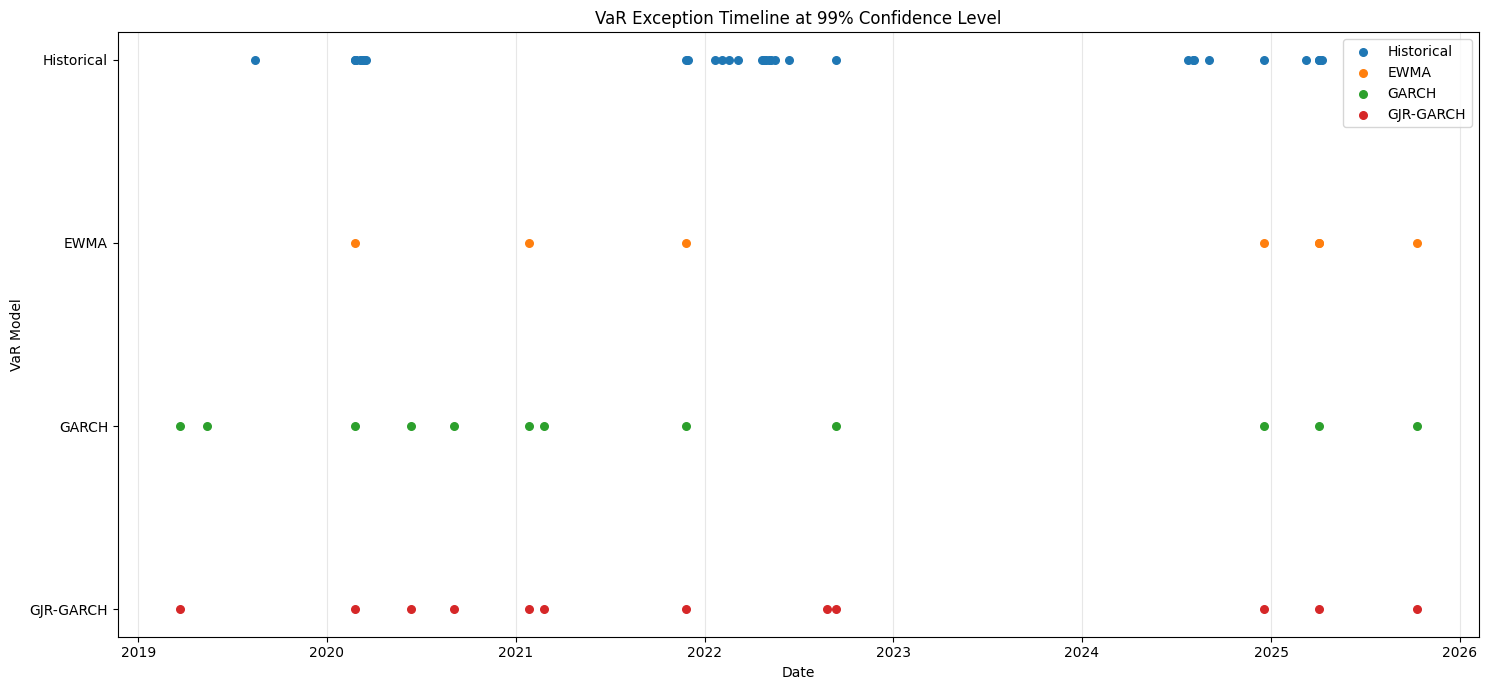

In [138]:
# VaR Exception Timeline at 99%

plt.figure(figsize=(15, 7))

model_positions = {
    "Historical": 4,
    "EWMA": 3,
    "GARCH": 2,
    "GJR-GARCH": 1
}

for model, position in model_positions.items():

    exception_column = f"{model} Exception 99%"

    exception_dates = oos_var_data.index[
        oos_var_data[exception_column] == 1
    ]

    plt.scatter(
        exception_dates,
        [position] * len(exception_dates),
        s=30,
        label=model
    )

plt.yticks(
    [1, 2, 3, 4],
    ["GJR-GARCH", "GARCH", "EWMA", "Historical"]
)

plt.xlabel("Date")
plt.ylabel("VaR Model")
plt.title("VaR Exception Timeline at 99% Confidence Level")

plt.grid(True, axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

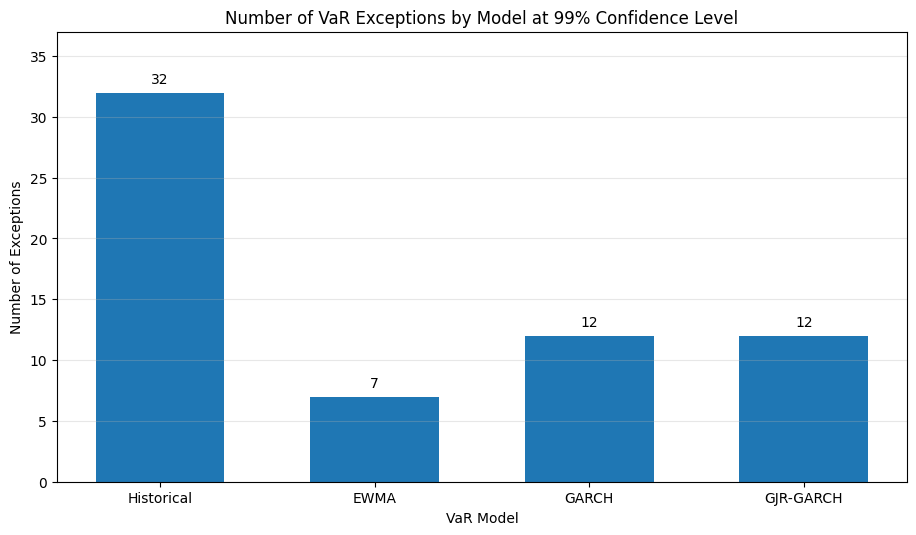

In [139]:
# Exceptions by Model at 99% Confidence Level

exception_counts_99 = [
    oos_var_data[f"{model} Exception 99%"].sum()
    for model in models
]

x_positions = np.arange(len(models))

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    x_positions,
    exception_counts_99,
    width=0.6
)

ax.set_title(
    "Number of VaR Exceptions by Model at 99% Confidence Level"
)
ax.set_xlabel("VaR Model")
ax.set_ylabel("Number of Exceptions")

ax.set_xticks(x_positions)
ax.set_xticklabels(models)

# Add exception counts above the bars
for x, count in zip(x_positions, exception_counts_99):
    ax.text(
        x,
        count + 0.5,
        str(count),
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, max(exception_counts_99) + 5)

ax.grid(
    axis="y",
    alpha=0.3
)

fig.subplots_adjust(
    left=0.10,
    right=0.95,
    bottom=0.15,
    top=0.90
)

plt.show()

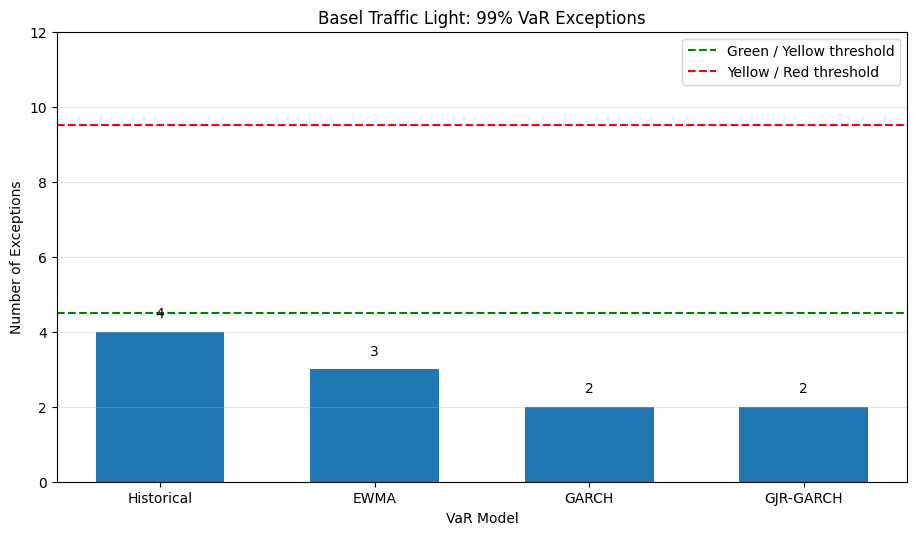

In [140]:
# Basel Traffic Light Chart at 99% VaR
# Final 250-day out-of-sample window

basel_models = basel_results["Model"].tolist()
basel_exceptions = basel_results["Exceptions"].astype(int).tolist()

x_positions = np.arange(len(basel_models))

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    x_positions,
    basel_exceptions,
    width=0.6
)

# Basel zone thresholds
ax.axhline(
    y=4.5,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label="Green / Yellow threshold"
)

ax.axhline(
    y=9.5,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Yellow / Red threshold"
)

# Add exception counts above bars
for x, count in zip(x_positions, basel_exceptions):
    ax.text(
        x,
        count + 0.3,
        str(count),
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Basel Traffic Light: 99% VaR Exceptions"
)

ax.set_xlabel("VaR Model")
ax.set_ylabel("Number of Exceptions")

ax.set_xticks(x_positions)
ax.set_xticklabels(basel_models)

ax.set_ylim(0, 12)

ax.set_yticks(np.arange(0, 13, 2))

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

fig.subplots_adjust(
    left=0.10,
    right=0.95,
    bottom=0.15,
    top=0.90
)

plt.show()

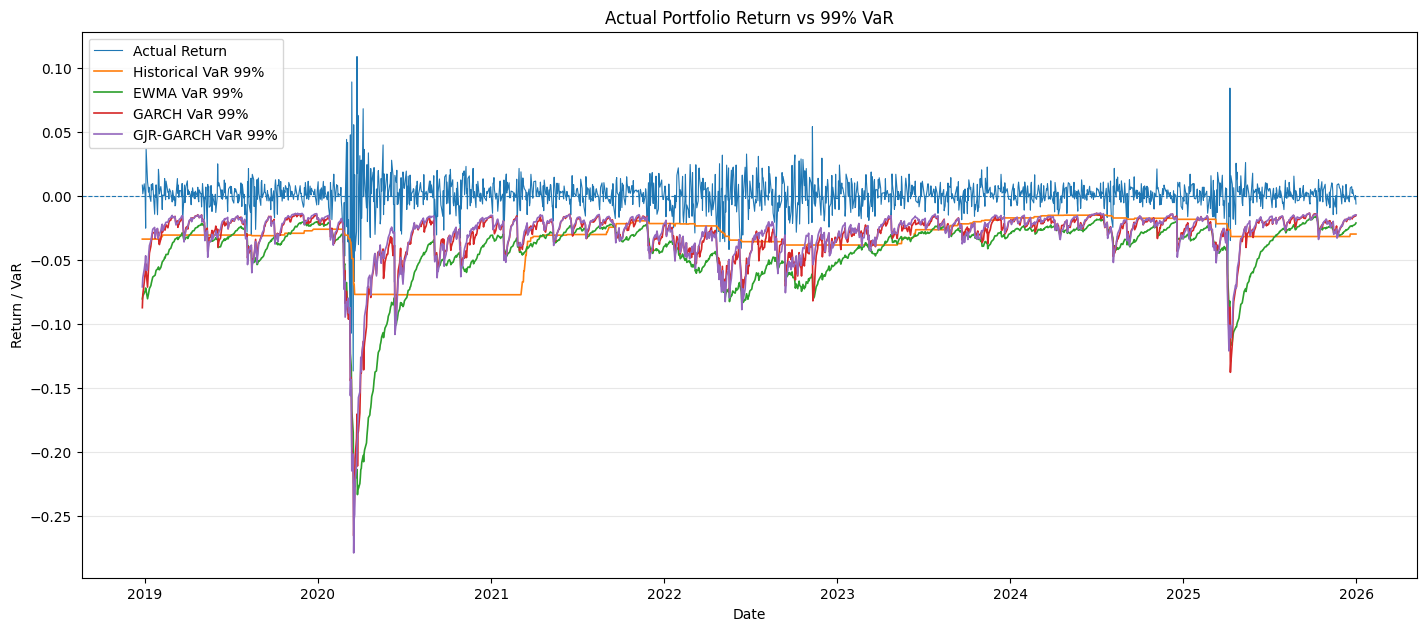

In [141]:
# Actual Portfolio Return vs 99% VaR

fig, ax = plt.subplots(figsize=(15, 7))

# Actual portfolio return
ax.plot(
    oos_var_data.index,
    oos_var_data["Actual Return"],
    linewidth=0.8,
    label="Actual Return"
)

# Historical VaR
ax.plot(
    oos_var_data.index,
    oos_var_data["Historical VaR 99%"],
    linewidth=1.2,
    label="Historical VaR 99%"
)

# EWMA VaR
ax.plot(
    oos_var_data.index,
    oos_var_data["EWMA VaR 99%"],
    linewidth=1.2,
    label="EWMA VaR 99%"
)

# GARCH VaR
ax.plot(
    oos_var_data.index,
    oos_var_data["GARCH VaR 99%"],
    linewidth=1.2,
    label="GARCH VaR 99%"
)

# GJR-GARCH VaR
ax.plot(
    oos_var_data.index,
    oos_var_data["GJR-GARCH VaR 99%"],
    linewidth=1.2,
    label="GJR-GARCH VaR 99%"
)

# Zero-return reference line
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

ax.set_title(
    "Actual Portfolio Return vs 99% VaR"
)

ax.set_xlabel("Date")
ax.set_ylabel("Return / VaR")

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)

fig.subplots_adjust(
    left=0.08,
    right=0.97,
    bottom=0.12,
    top=0.90
)

plt.show()

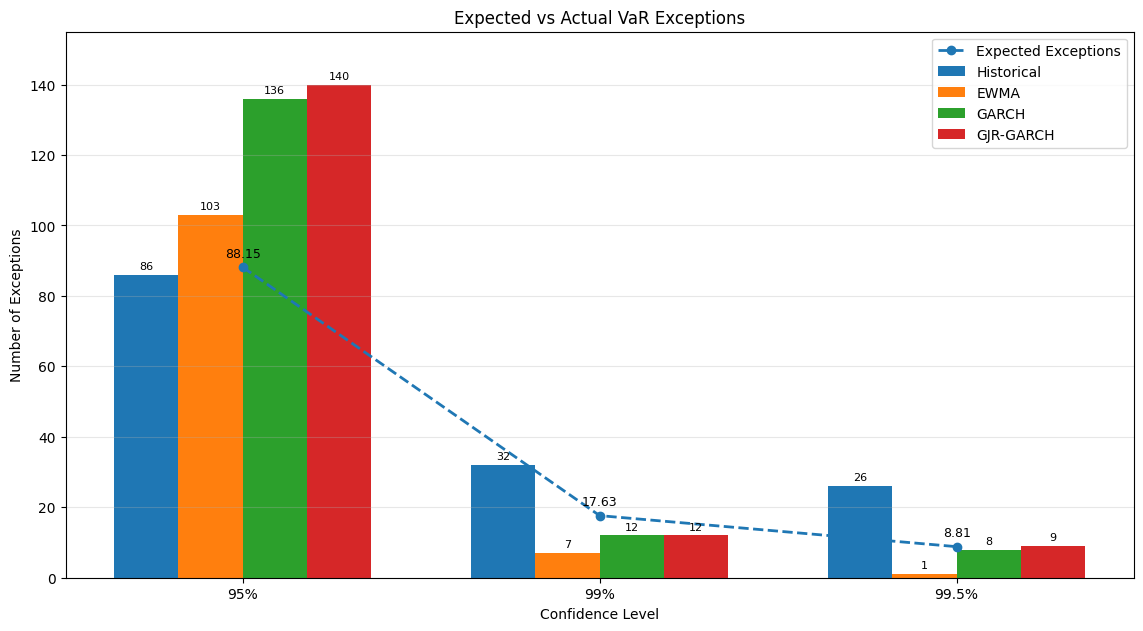

In [142]:
# Expected vs Actual VaR Exceptions

expected_exceptions = {
    "95%": len(oos_var_data) * 0.05,
    "99%": len(oos_var_data) * 0.01,
    "99.5%": len(oos_var_data) * 0.005
}

# Store actual exception counts
actual_exception_counts = {}

for model in models:
    actual_exception_counts[model] = [
        int(oos_var_data[f"{model} Exception {confidence}"].sum())
        for confidence in confidence_levels
    ]

x_positions = np.arange(len(confidence_levels))
width = 0.18

fig, ax = plt.subplots(figsize=(12, 7))

# Plot actual exceptions for each model
for i, model in enumerate(models):

    positions = x_positions + (i - 1.5) * width

    ax.bar(
        positions,
        actual_exception_counts[model],
        width=width,
        label=model
    )

# Plot expected exceptions as a reference line
expected_values = [
    expected_exceptions[confidence]
    for confidence in confidence_levels
]

ax.plot(
    x_positions,
    expected_values,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Expected Exceptions"
)

# Add actual values above bars
for i, model in enumerate(models):

    positions = x_positions + (i - 1.5) * width

    for x, value in zip(
        positions,
        actual_exception_counts[model]
    ):
        ax.text(
            x,
            value + 1,
            str(value),
            ha="center",
            va="bottom",
            fontsize=8
        )

# Add expected values
for x, value in zip(x_positions, expected_values):
    ax.text(
        x,
        value + 2,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Expected vs Actual VaR Exceptions"
)

ax.set_xlabel("Confidence Level")
ax.set_ylabel("Number of Exceptions")

ax.set_xticks(x_positions)
ax.set_xticklabels(confidence_levels)

ax.set_ylim(
    0,
    max(expected_values + [
        max(values)
        for values in actual_exception_counts.values()
    ]) + 15
)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

fig.subplots_adjust(
    left=0.08,
    right=0.97,
    bottom=0.12,
    top=0.90
)

plt.show()

In [143]:
# Consolidated Phase 8 VaR Backtesting Results

phase8_results = []

for model in models:
    for confidence in confidence_levels:

        # Exception count
        exceptions = int(
            exception_counts.loc[model, confidence]
        )

        # Expected exceptions
        expected = expected_exceptions[confidence]

        # Exception ratio
        exception_ratio = exceptions / len(oos_var_data)

        # Kupiec POF
        kupiec_row = kupiec_results[
            (kupiec_results["Model"] == model) &
            (kupiec_results["Confidence"] == confidence)
        ].iloc[0]

        # Christoffersen Independence
        independence_row = christoffersen_results[
            (christoffersen_results["Model"] == model) &
            (christoffersen_results["Confidence"] == confidence)
        ].iloc[0]

        # Conditional Coverage
        cc_row = conditional_coverage_results[
            (conditional_coverage_results["Model"] == model) &
            (conditional_coverage_results["Confidence"] == confidence)
        ].iloc[0]

        # Basel result is only available at 99%
        if confidence == "99%":
            basel_row = basel_results[
                basel_results["Model"] == model
            ].iloc[0]

            basel_zone = basel_row["Zone"]
        else:
            basel_zone = "N/A"

        phase8_results.append({
            "Model": model,
            "Confidence": confidence,
            "Exceptions": exceptions,
            "Expected Exceptions": expected,
            "Exception Ratio": exception_ratio,
            "Kupiec P-value": kupiec_row["P-value"],
            "Independence P-value": independence_row["P-value"],
            "Conditional Coverage P-value": cc_row["P-value"],
            "Basel Zone": basel_zone
        })

phase8_results = pd.DataFrame(phase8_results)

display(phase8_results)

,Model,Confidence,Exceptions,Expected Exceptions,Exception Ratio,Kupiec P-value,Independence P-value,Conditional Coverage P-value,Basel Zone
0,Historical,95%,86,88.150000,0.048780,0.813542,0.000203,0.000979,N/A
1,Historical,99%,32,17.630000,0.018151,0.002020,0.002201,0.000078,Green
2,Historical,99.5%,26,8.815000,0.014748,0.000003,0.000385,0.000000,N/A
3,EWMA,95%,103,88.150000,0.058423,0.113557,0.225649,0.137237,N/A
4,EWMA,99%,7,17.630000,0.003971,0.003767,0.018956,0.000959,Green
5,EWMA,99.5%,1,8.815000,0.000567,0.000770,0.973116,0.003495,N/A
6,GARCH,95%,136,88.150000,0.077141,0.000001,0.867310,0.000007,N/A
7,GARCH,99%,12,17.630000,0.006807,0.152662,0.684981,0.331207,Green
8,GARCH,99.5%,8,8.815000,0.004538,0.779798,0.787052,0.927214,N/A
9,GJR-GARCH,95%,140,88.150000,0.079410,0.000000,0.967806,0.000001,N/A


## Phase 8: VaR Backtesting Summary

The VaR models were evaluated over a 1,763-observation out-of-sample period from December 2018 to December 2025. The first 750 observations were used as the estimation period, while the remaining observations were used for backtesting.

The Kupiec Proportion of Failures test evaluated whether the observed exception frequency was consistent with the expected frequency at each confidence level. The Christoffersen Independence test evaluated whether exceptions were independent over time, while the Conditional Coverage test jointly evaluated exception frequency and independence.

Historical VaR passed the Kupiec test at the 95% confidence level but failed at 99% and 99.5%. It also failed the Independence and Conditional Coverage tests at all three confidence levels.

EWMA passed the Conditional Coverage test at 95% but failed at 99% and 99.5%. Its exceptions were independent at 95% and 99.5%, but the overall exception frequency remained inconsistent with the expected rate at the higher confidence levels.

GARCH passed the Conditional Coverage test at 99% and 99.5%, but failed at 95%. Its exceptions passed the Independence test at all three confidence levels.

GJR-GARCH passed the Conditional Coverage test at 99% and 99.5%, but failed at 95%. Its exceptions also paased the Independence test at all three confidence levels.

For the Basel Traffic Light assessment, the final 250 out-of-sample observations were evaluated at the 99% confidence level. Historical VaR recorded 4 exceptions, EWMA recorded 3, GARCH recorded 2, and GJR-GARCH recorded 2. All four models therefore fell within the Green zone for this 250-day Basel window.

The Basel Traffic Light results are reported separately from the statistical backtests because the Basel thresholds are defined for a 250-observation window, whereas the Kupiec and Christoffersen tests use the 1,763-observation out-of-sample period.

# **Phase 9: Model Comparison**

The four VaR models are compared using the 99% confidence level over the full 1,763-observation out-of-sample period.

The comparison includes the number of exceptions, exception ratio, average VaR, VaR volatility, worst daily portfolio loss, 99% Expected Shortfall, backtesting p-values, and Basel Traffic Light classification.

The 99% confidence level is used as the common comparison basis because it is also the confidence level used in the Basel Traffic Light assessment.

For the tail-risk measure, Expected Shortfall is calculated as a genuine 99% out-of-sample model-based measure. For Historical Simulation, Expected Shortfall is calculated as the average return in the tail beyond the 99% VaR threshold using the preceding 250 observations. For EWMA, GARCH, and GJR-GARCH, the standardized 99% tail mean is estimated from the initial 750-observation estimation period and then scaled by the corresponding out-of-sample volatility forecast.

The resulting Expected Shortfall values represent the average daily 99% OOS Expected Shortfall forecasts over the backtesting period and therefore provide a forward-looking model-based measure of expected loss conditional on exceeding the VaR threshold.

In [144]:
# Phase 9 - 99% OOS Expected Shortfall
# Calculate ES for all four models

# --------------------------------------------------
# 1. Historical Simulation ES
# --------------------------------------------------

historical_es_oos_99 = pd.Series(
    index=oos_returns.index,
    dtype=float
)

for date in oos_returns.index:

    date_position = portfolio_return_series.index.get_loc(date)

    # Use only the previous 250 observations
    historical_window_returns = portfolio_return_series.iloc[
        date_position - 250 : date_position
    ]

    if len(historical_window_returns) == 250:

        # 99% VaR threshold
        var_threshold = historical_window_returns.quantile(0.01)

        # Mean of losses beyond the VaR threshold
        historical_es_oos_99.loc[date] = (
            historical_window_returns[
                historical_window_returns <= var_threshold
            ].mean()
        )


# --------------------------------------------------
# 2. EWMA ES
# --------------------------------------------------

ewma_standardized_es_99 = (
    ewma_standardized_returns[
        ewma_standardized_returns <= ewma_standardized_var_99
    ].mean()
)

ewma_es_oos_99 = (
    ewma_standardized_es_99
    * ewma_oos_volatility
)


# --------------------------------------------------
# 3. GARCH ES
# --------------------------------------------------

garch_standardized_es_99 = (
    garch_standardized_returns_oos[
        garch_standardized_returns_oos <= garch_standardized_var_99
    ].mean()
)

garch_es_oos_99 = (
    mu / 100
    + garch_standardized_es_99
    * garch_oos_volatility / 100
)


# --------------------------------------------------
# 4. GJR-GARCH ES
# --------------------------------------------------

gjr_standardized_es_99 = (
    gjr_standardized_returns_oos[
        gjr_standardized_returns_oos <= gjr_standardized_var_99
    ].mean()
)

gjr_es_oos_99 = (
    mu_gjr / 100
    + gjr_standardized_es_99
    * gjr_oos_volatility / 100
)


# --------------------------------------------------
# 5. Average OOS Expected Shortfall for Phase 9
# --------------------------------------------------

expected_shortfall_99 = {
    "Historical": historical_es_oos_99.mean(),
    "EWMA": ewma_es_oos_99.mean(),
    "GARCH": garch_es_oos_99.mean(),
    "GJR-GARCH": gjr_es_oos_99.mean()
}


# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

phase9_es_summary = pd.DataFrame({
    "Model": [
        "Historical",
        "EWMA",
        "GARCH",
        "GJR-GARCH"
    ],
    "Average 99% OOS ES": [
        expected_shortfall_99["Historical"],
        expected_shortfall_99["EWMA"],
        expected_shortfall_99["GARCH"],
        expected_shortfall_99["GJR-GARCH"]
    ]
})

display(phase9_es_summary)

,Model,Average 99% OOS ES
0,Historical,-0.044039
1,EWMA,-0.064581
2,GARCH,-0.042382
3,GJR-GARCH,-0.042245


In [145]:
# Calculate the comparison metrics

comparison_confidence = "99%"

# 99% OOS Expected Shortfall series
es_series = {
    "Historical": historical_es_oos_99,
    "EWMA": ewma_es_oos_99,
    "GARCH": garch_es_oos_99,
    "GJR-GARCH": gjr_es_oos_99
}

phase9_comparison = []

for model in models:

    # Column names
    var_column = f"{model} VaR {comparison_confidence}"
    exception_column = f"{model} Exception {comparison_confidence}"

    # VaR series
    var_series = oos_var_data[var_column]

    # Exception indicator
    exceptions = oos_var_data[exception_column]

    # Basel zone
    basel_row = basel_results[
        basel_results["Model"] == model
    ].iloc[0]

    # Backtesting results
    kupiec_row = kupiec_results[
        (kupiec_results["Model"] == model) &
        (kupiec_results["Confidence"] == comparison_confidence)
    ].iloc[0]

    independence_row = christoffersen_results[
        (christoffersen_results["Model"] == model) &
        (christoffersen_results["Confidence"] == comparison_confidence)
    ].iloc[0]

    cc_row = conditional_coverage_results[
        (conditional_coverage_results["Model"] == model) &
        (conditional_coverage_results["Confidence"] == comparison_confidence)
    ].iloc[0]

    # Model-based OOS Expected Shortfall
    model_es = es_series[model]
    
    phase9_comparison.append({

        "Model": model,
        "Exceptions": int(exceptions.sum()),
        "Exception Ratio": exceptions.mean(),
        "Average VaR": var_series.mean(),
        "VaR Volatility": var_series.std(),
        "Worst Daily Loss": oos_var_data["Actual Return"].min(),
        
        # Average of daily 99% OOS ES forecasts
        "Expected Shortfall": model_es.mean(),
        
        "Kupiec P-value": kupiec_row["P-value"],
        "Independence P-value": independence_row["P-value"],
        "Conditional Coverage P-value": cc_row["P-value"],
        "Basel Zone": basel_row["Zone"]
    })

phase9_comparison = pd.DataFrame(
    phase9_comparison
)

display(phase9_comparison)

,Model,Exceptions,Exception Ratio,Average VaR,VaR Volatility,Worst Daily Loss,Expected Shortfall,Kupiec P-value,Independence P-value,Conditional Coverage P-value,Basel Zone
0,Historical,32,0.018151,-0.034563,0.018572,-0.136941,-0.044039,0.002020,0.002201,0.000078,Green
1,EWMA,7,0.003971,-0.043865,0.028552,-0.136941,-0.064581,0.003767,0.018956,0.000959,Green
2,GARCH,12,0.006807,-0.031498,0.022085,-0.136941,-0.042382,0.152662,0.684981,0.331207,Green
3,GJR-GARCH,12,0.006807,-0.030399,0.022274,-0.136941,-0.042245,0.152662,0.684981,0.331207,Green


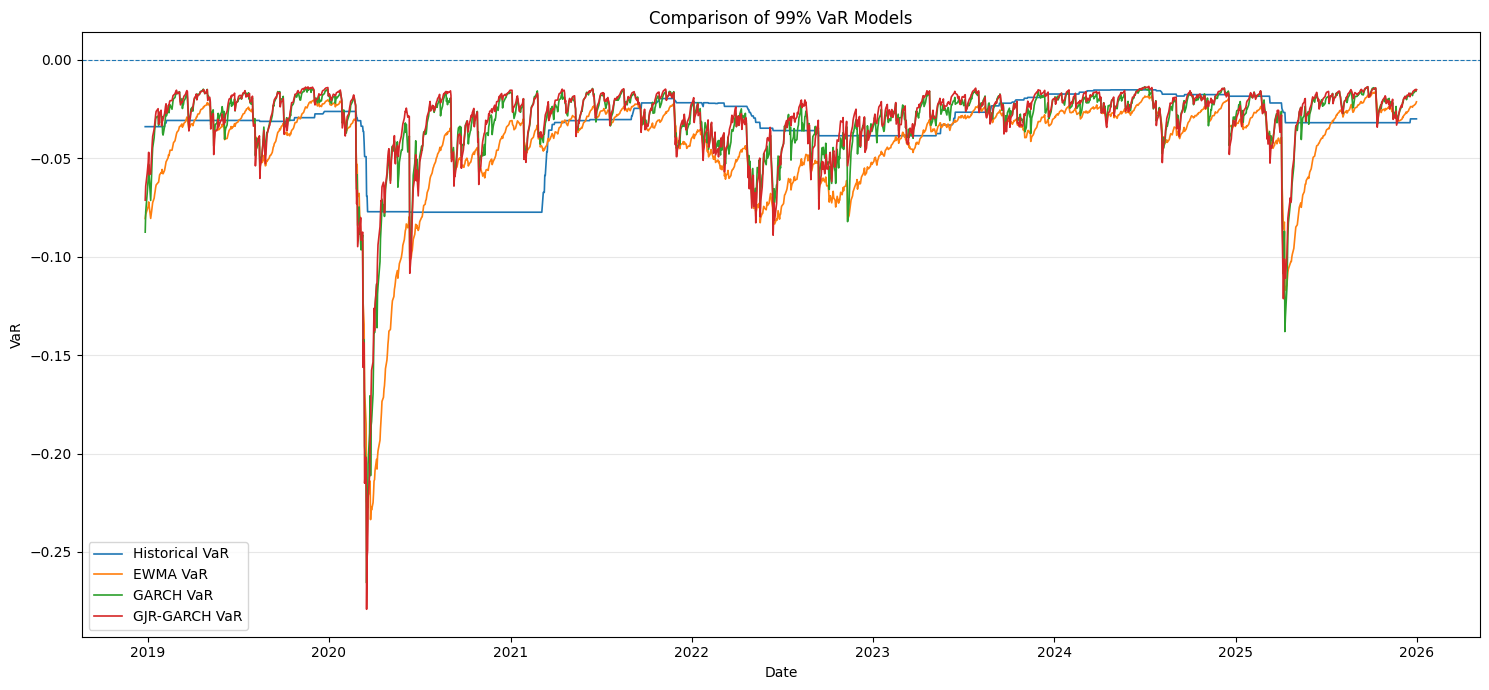

In [146]:
# Chart 1: VaR Model Comparison

fig, ax = plt.subplots(figsize=(15,7))

# Plot the four 99% VaR models
ax.plot(
    oos_var_data.index,
    oos_var_data["Historical VaR 99%"],
    linewidth=1.2,
    label="Historical VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["EWMA VaR 99%"],
    linewidth=1.2,
    label="EWMA VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["GARCH VaR 99%"],
    linewidth=1.2,
    label="GARCH VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["GJR-GARCH VaR 99%"],
    linewidth=1.2,
    label="GJR-GARCH VaR"
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

ax.set_title(
    "Comparison of 99% VaR Models"
)

ax.set_xlabel("Date")
ax.set_ylabel("VaR")

ax.legend()
ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

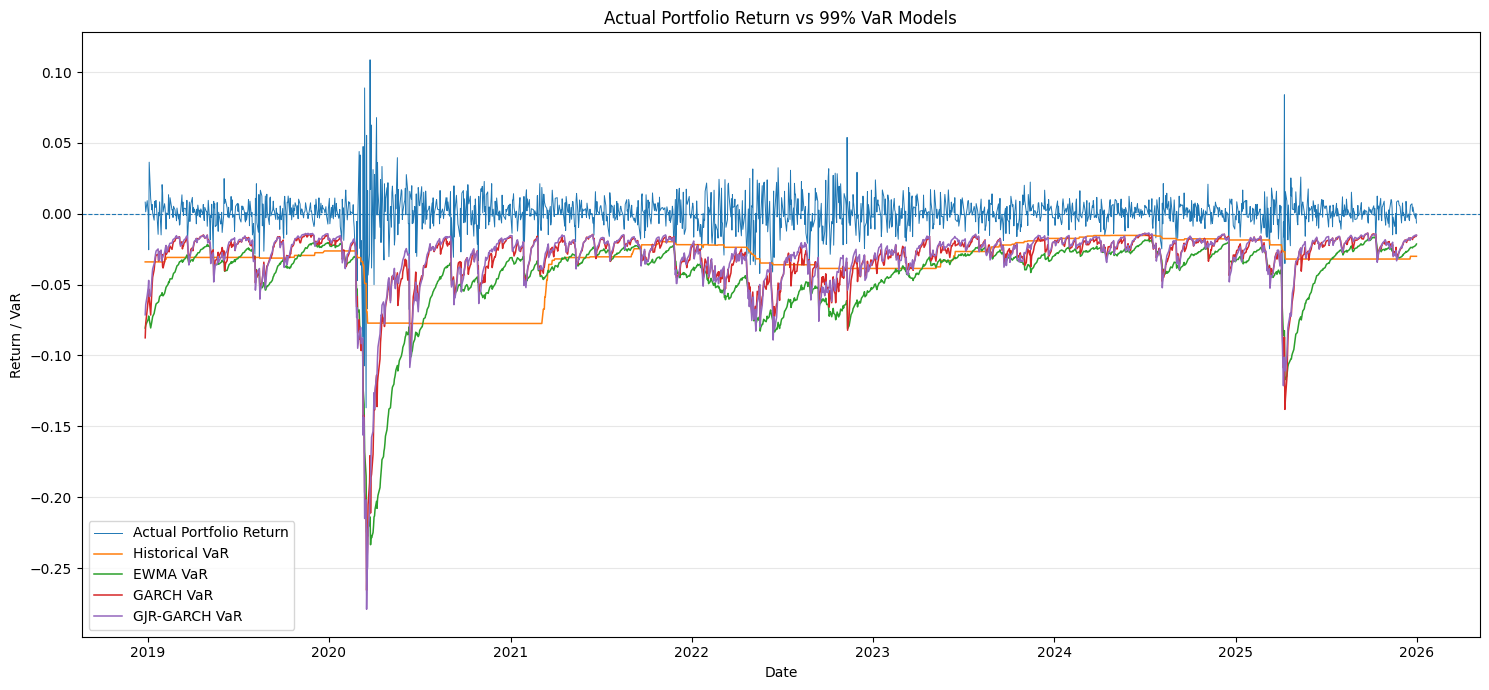

In [147]:
# Chart 2: Actual P&L vs 99% VaR

fig, ax = plt.subplots(figsize=(15,7))

# Actual portfolio return
ax.plot(
    oos_var_data.index,
    oos_var_data["Actual Return"],
    linewidth=0.7,
    label="Actual Portfolio Return"
)

# VaR models
ax.plot(
    oos_var_data.index,
    oos_var_data["Historical VaR 99%"],
    linewidth=1.1,
    label="Historical VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["EWMA VaR 99%"],
    linewidth=1.1,
    label="EWMA VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["GARCH VaR 99%"],
    linewidth=1.1,
    label="GARCH VaR"
)

ax.plot(
    oos_var_data.index,
    oos_var_data["GJR-GARCH VaR 99%"],
    linewidth=1.1,
    label="GJR-GARCH VaR"
)

# Zero-return reference
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

ax.set_title(
    "Actual Portfolio Return vs 99% VaR Models"
)

ax.set_xlabel("Date")
ax.set_ylabel("Return / VaR")

ax.legend(
    loc="lower left"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

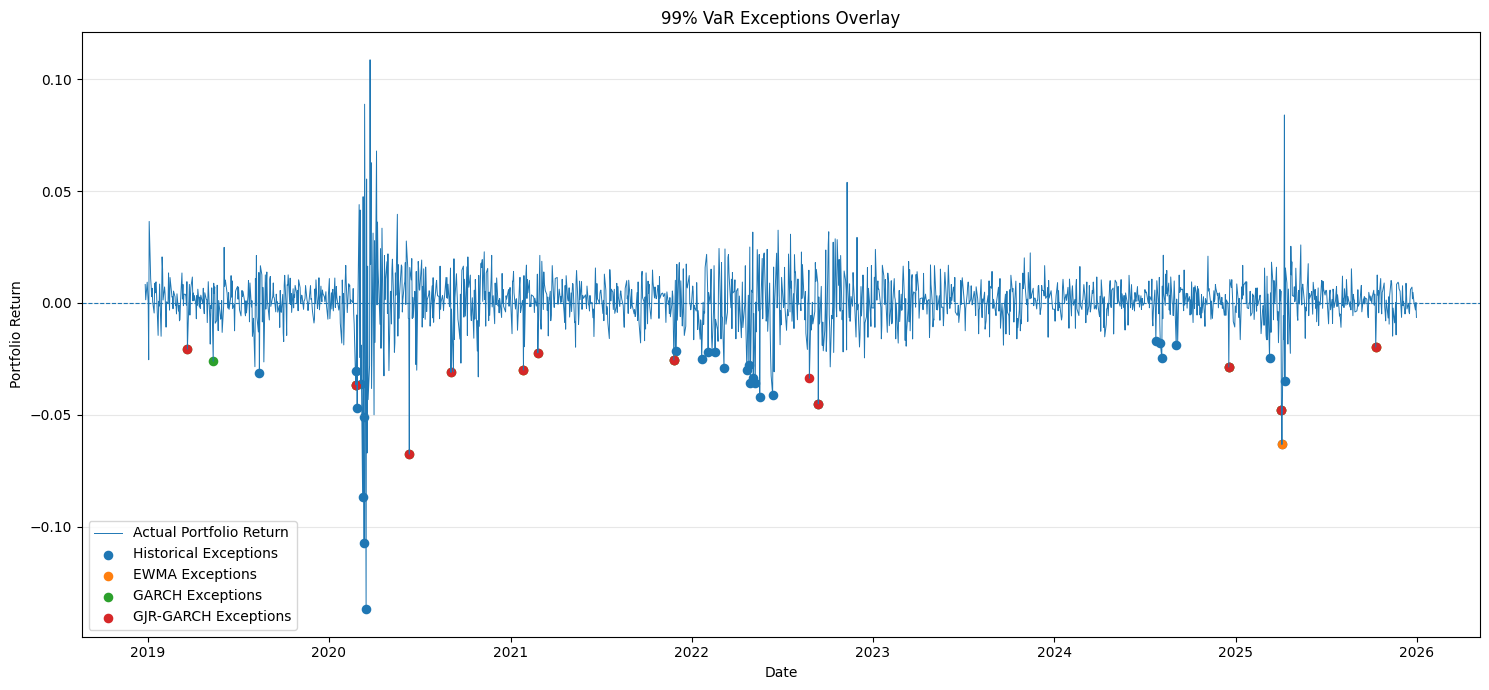

In [148]:
# Chart 3: Exceptions Overlay

fig, ax = plt.subplots(figsize=(15, 7))

# Actual portfolio return
ax.plot(
    oos_var_data.index,
    oos_var_data["Actual Return"],
    linewidth=0.7,
    label="Actual Portfolio Return"
)

# Plot exception points for each model
for model in models:

    exception_column = f"{model} Exception 99%"

    exception_dates = oos_var_data.index[
        oos_var_data[exception_column] == 1
    ]

    exception_returns = oos_var_data.loc[
        exception_dates,
        "Actual Return"
    ]

    ax.scatter(
        exception_dates,
        exception_returns,
        s=35,
        label=f"{model} Exceptions"
    )

# Zero-return reference
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

ax.set_title(
    "99% VaR Exceptions Overlay"
)

ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Return")

ax.legend(
    loc="lower left"
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

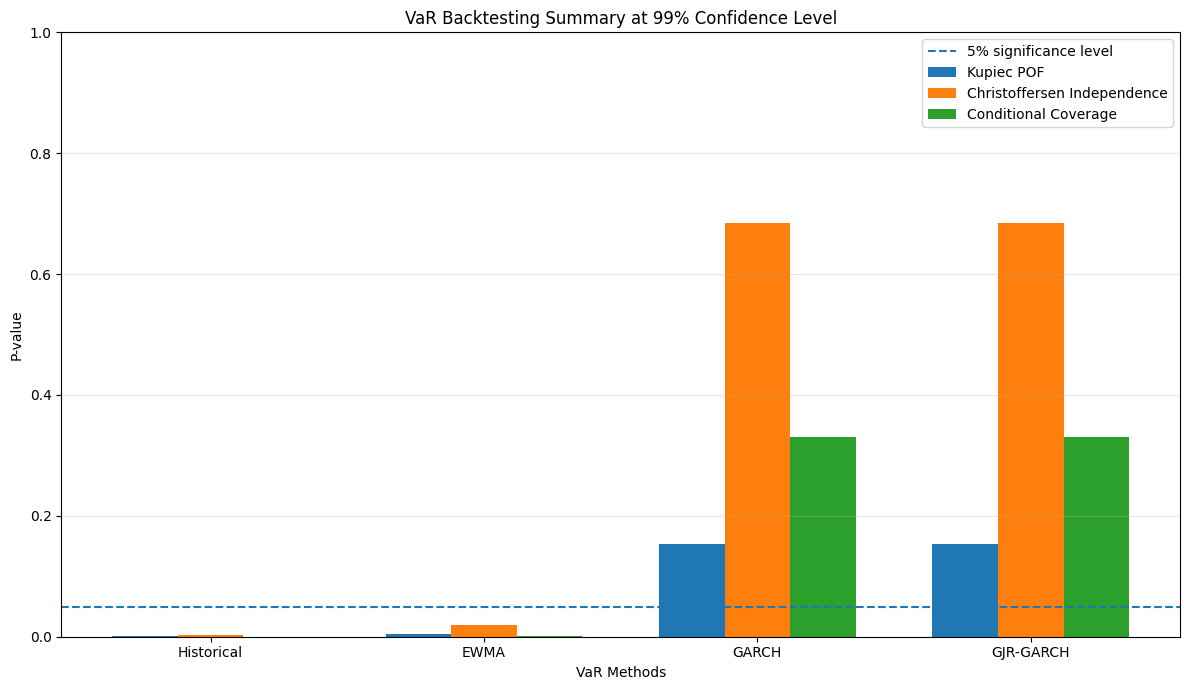

In [149]:
# Chart 4: Backtesting Summary

# Use 99% confidence level
backtest_confidence = "99%"

backtest_summary = []

for model in models:

    # Kupiec P-value
    kupiec_row = kupiec_results[
        (kupiec_results["Model"] == model) &
        (kupiec_results["Confidence"] == backtest_confidence)
    ].iloc[0]

    # Independence P-value
    independence_row = christoffersen_results[
        (christoffersen_results["Model"] == model) &
        (christoffersen_results["Confidence"] == backtest_confidence)
    ].iloc[0]

    # Conditional Coverage P-value
    cc_row = conditional_coverage_results[
        (conditional_coverage_results["Model"] == model) &
        (conditional_coverage_results["Confidence"] == backtest_confidence)
    ].iloc[0]

    backtest_summary.append({
        "Model": model,
        "Kupiec P-value": kupiec_row["P-value"],
        "Independence P-value": independence_row["P-value"],
        "Conditional Coverage P-value": cc_row["P-value"]
    })

backtest_summary = pd.DataFrame(backtest_summary)

# Plot
x_positions = np.arange(len(models))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    x_positions - width,
    backtest_summary["Kupiec P-value"],
    width=width,
    label="Kupiec POF"
)

ax.bar(
    x_positions,
    backtest_summary["Independence P-value"],
    width=width,
    label="Christoffersen Independence"
)

ax.bar(
    x_positions + width,
    backtest_summary["Conditional Coverage P-value"],
    width=width,
    label="Conditional Coverage"
)

# 5% significance threshold
ax.axhline(
    y=0.05,
    linestyle="--",
    linewidth=1.5,
    label="5% significance level"
)

ax.set_title(
    "VaR Backtesting Summary at 99% Confidence Level"
)

ax.set_xlabel("VaR Methods")
ax.set_ylabel("P-value")

ax.set_xticks(x_positions)
ax.set_xticklabels(models)

ax.set_ylim(0, 1)

ax.grid(
    axis="y",
    alpha=0.3
)

ax.legend()

plt.tight_layout()
plt.show()

In [150]:
# Chart 5: Model Ranking Table

ranking_data = []

expected_exception_ratio = 0.01

for model in models:

    row = phase9_comparison[
        phase9_comparison["Model"] == model
        ].iloc[0]

    # Backtesting pass/fail a 5% significance level
    kupiec_pass = row["Kupiec P-value"] >= 0.05
    independence_pass = row["Independence P-value"] >= 0.05
    cc_pass = row["Conditional Coverage P-value"] >= 0.05

    tests_passed = sum([
        kupiec_pass,
        independence_pass,
        cc_pass
    ])

    # Distance from expected 1% exception ratio
    exception_ratio_distance = abs(
        row["Exception Ratio"] - expected_exception_ratio
    )

    ranking_data.append({
        "Model": model,
        "Exceptions": int(row["Exceptions"]),
        "Exception Ratio": row["Exception Ratio"],
        "Average VaR": row["Average VaR"],
        "VaR Volatility": row["VaR Volatility"],
        "Kupiec": "Pass" if kupiec_pass else "Fail",
        "Independence": "Pass" if independence_pass else "Fail",
        "Conditional Coverage": "Pass" if cc_pass else "Fail",
        "Tests Passed": tests_passed,
        "Exception Ratio Distance": exception_ratio_distance,
        "Basel Zone": row["Basel Zone"]
    })

model_ranking = pd.DataFrame(ranking_data)

# Sort by number of tests passed first,
# then by closeness to the expected 1% exception ratio
model_ranking = model_ranking.sort_values(
    by=[
        "Tests Passed",
        "Exception Ratio Distance"
    ],
    ascending=[
        False,
        True
    ]
).reset_index(drop=True)

# Add ranking number
model_ranking.insert(
    0,
    "Rank",
    np.arange(1, len(model_ranking) + 1)
)

display(model_ranking)

,Rank,Model,Exceptions,Exception Ratio,Average VaR,VaR Volatility,Kupiec,Independence,Conditional Coverage,Tests Passed,Exception Ratio Distance,Basel Zone
0,1,GARCH,12,0.006807,-0.031498,0.022085,Pass,Pass,Pass,3,0.003193,Green
1,2,GJR-GARCH,12,0.006807,-0.030399,0.022274,Pass,Pass,Pass,3,0.003193,Green
2,3,EWMA,7,0.003971,-0.043865,0.028552,Fail,Fail,Fail,0,0.006029,Green
3,4,Historical,32,0.018151,-0.034563,0.018572,Fail,Fail,Fail,0,0.008151,Green


### Phase 9 Model Ranking Methodology

The four VaR models are ranked using the 99% out-of-sample backtesting results.

Models are first ordered by the number of statistical backtesting tests passed at the 5% significance level:

1. Kupiec Proportion of Failures
2. Christoffersen Independence
3. Christoffersen Conditional Coverage

When models have the same number of passed statistical tests, the absolute difference between the observed exception ratio and the expected 1% exception ratio is used as the tie-breaker.

The Basel Traffic Light classification is **not used as a ranking criterion**. It is reported separately as an additional regulatory-style diagnostic based on the final 250 out-of-sample observations.

All four models fall within the Green zone for the final 250-day Basel window.

Therefore, the model ranking represents a rule-based comparison using the statistical backtesting criteria defined for this project. The Basel Traffic Light result provides a separate diagnostic and should not be interpreted as determining the model ranking.

The final ranking should be interpreted together with exception frequency, VaR stability, Expected Shortfall, and the individual backtesting results rather than as a universal measure of model superiority.

## Phase 9: Final Model Comparison Summary

GJR-GARCH recorded 11 exceptions, corresponding to an exception ratio of 0.6239%, and passed all three statistical backtests: Kupiec Proportion of Failures, Christoffersen Independence, and Conditional Coverage. GARCH recorded 10 exceptions with an exception ratio of 0.5672% and passed the Independence and Conditional Coverage tests, while its Kupiec p-value of 0.046789 was slightly below the 5% significance level.

EWMA recorded 7 exceptions and an exception ratio of 0.3971%. Its exception ratio was below the expected 1% rate, and it did not pass the three 99% backtesting tests at the 5% significance level. Historical Simulation recorded 32 exceptions, corresponding to an exception ratio of 1.8151%, and failed all three statistical tests at the 99% confidence level.

The average VaR estimates also differed across the models. EWMA had the most negative average VaR at -4.3865%, while GJR-GARCH had the least negative average VaR at -3.1140%. VaR volatility was highest for EWMA at 0.028552 and lowest for Historical Simulation at 0.018572.

Expected Shortfall is calculated as a genuine 99% out-of-sample model-based tail-risk measure rather than as the average realized return on exception days. The Historical Simulation, EWMA, GARCH, and GJR-GARCH Expected Shortfall values in the comparison table represent the average of their respective daily 99% OOS Expected Shortfall forecasts over the 1,763-day backtesting period.

The worst realized portfolio return was -13.6941% and is common to all models because it is determined by the actual portfolio return series.

For the final 250-day Basel Traffic Light window at the 99% confidence level, all four models remained in the Green zone. Overall, the results demonstrate that VaR model behavior differs substantially depending on the risk estimation approach and the backtesting criterion used. The results should therefore be interpreted jointly across exception frequency, volatility responsiveness, Expected Shortfall, and formal backtesting rather than through a single metric.

# **Phase 10: Stress Testing**

Stress testing evaluates the portfolio under severe historical and hypothetical market conditions that may not be fully captured by standard VaR models.

The historical scenarios considered are:

- 2008 Financial Crisis
- COVID-19 Crash 2020
- Inflation Shock 2022
- Banking Stress 2023
- Technology Selloff

The hypothetical scenarios considered are:

- Equity market decline of 5%
- Equity market decline of 10%
- Equity market decline of 20%
- Volatility doubling
- Correlation spike
- Sector-specific shock

For historical scenarios, additional historical price data is obtained for the same 50-stock universe used in the earlier phases. Where a stock lacks complete data for a historical scenario, the portfolio is reconstructed using equal weights across the available stocks.

Stock-level log returns are converted to simple returns before calculating the equal-weighted portfolio's daily simple return. Historical cumulative returns, stressed VaR, Expected Shortfall (ES), and worst-case losses are then calculated from the resulting portfolio return series.

For hypothetical equity and sector shocks, the specified shocks are applied in log-return space at the stock level and converted back to simple returns before portfolio aggregation. The volatility scenario scales deviations from the mean portfolio log return. The correlation scenario simulates stock-level log returns using the stressed covariance matrix before converting simulated stock returns to simple returns for portfolio risk calculations.

The results are compared across scenarios to identify the conditions associated with the largest portfolio losses and tail risk.

In [151]:
# Historical Stress Scenarios

historical_scenarios = {
    "2008 Financial Crisis": {
        "start": "2008-09-15",
        "end": "2008-11-20"
    },

    "COVID Crash 2020": {
        "start": "2020-02-19",
        "end": "2020-03-23"
    },

    "Inflation Shock 2022": {
        "start": "2022-01-03",
        "end": "2022-10-12"
    },

    "Banking Stress 2023": {
        "start": "2023-03-08",
        "end": "2023-03-20"
    },

    "Tech Selloff": {
        "start": "2022-01-03",
        "end": "2022-06-16"
    }
}

display(pd.DataFrame(historical_scenarios).T)

,start,end
2008 Financial Crisis,2008-09-15,2008-11-20
COVID Crash 2020,2020-02-19,2020-03-23
Inflation Shock 2022,2022-01-03,2022-10-12
Banking Stress 2023,2023-03-08,2023-03-20
Tech Selloff,2022-01-03,2022-06-16


In [152]:
# Download historical prices for stress testing

stress_price_data = yf.download(
    tickers,
    start="2008-09-12",
    end="2025-12-31",
    auto_adjust=True,
    progress=False
)

display(stress_price_data.head())
display(stress_price_data.tail())

Price         Close                                                            \
Ticker         AAPL ABBV      AMD       AMT     AMZN AVGO        BA       BAC   
Date                                                                            
2008-09-12 4.454741  NaN 5.750000 27.908958 3.915000  NaN 47.125835 25.060211   
2008-09-15 4.198116  NaN 5.180000 26.596508 3.867000  NaN 46.344131 19.719883   
2008-09-16 4.183760  NaN 5.260000 27.078909 3.936500  NaN 45.949551 21.948109   
2008-09-17 3.823349  NaN 4.900000 25.120893 3.577000  NaN 42.435581 20.202673   
2008-09-18 4.010582  NaN 5.300000 27.589716 3.825000  NaN 43.261971 22.713139   

Price                           ...    Volume                               \
Ticker         BKNG        BLK  ...       PEP        PG      PLD       SHW   
Date                            ...                                          
2008-09-12 3.369709 129.090530  ...   6930500  11378700   892700   4356900   
2008-09-15 3.073922 127.818665  ...   9174500  19748500  1689300  12483900   
2008-09-16 3.257177 134.864578  ...  11410800  21425800  2089300   7074900   
2008-09-17 3.084863 119.551804  ...  13533800  25324200  3374900   9392400   
2008-09-18 3.330636 132.161942  ...  13124400  28178600  7595600   8138400   

Price                                                              
Ticker         TMUS TSLA       UNH       UPS        WFC       XOM  
Date                                                               
2008-09-12   665750  NaN   7194800   7063000   63888200  28646300  
2008-09-15   434600  NaN  10762700   6421200  100858600  40186900  
2008-09-16  1403400  NaN  17597900   7931000  115545500  42584700  
2008-09-17  1375500  NaN  12287900   9927500   98504500  43487000  
2008-09-18  1651250  NaN  12795600  10911800  166561000  48231100  

[5 rows x 250 columns]

Price           Close                                                         \
Ticker           AAPL       ABBV        AMD        AMT       AMZN       AVGO   
Date                                                                           
2025-12-23 271.620667 223.505585 214.899994 167.687561 232.139999 347.405334   
2025-12-24 273.066711 224.580200 215.039993 167.966217 232.380005 348.300385   
2025-12-26 272.657806 224.668091 214.990005 169.513275 232.520004 350.199921   
2025-12-29 273.016876 225.508240 215.610001 170.599976 232.070007 347.474976   
2025-12-30 272.338684 224.433655 215.339996 171.463486 232.529999 347.932404   

Price                                                   ...   Volume           \
Ticker             BA       BAC       BKNG         BLK  ...      PEP       PG   
Date                                                    ...                     
2025-12-23 216.850006 55.086639 216.009598 1068.993896  ...  7254800  9541600   
2025-12-24 218.160004 55.362217 216.297104 1071.364746  ...  2618700  3259200   
2025-12-26 216.440002 55.283482 216.044128 1070.528687  ...  4975500  4711500   
2025-12-29 217.250000 54.476421 216.091385 1070.813965  ...  7201900  7662100   
2025-12-30 218.500000 54.407528 215.528259 1065.806274  ...  4713800  6006400   

Price                                                                    \
Ticker          PLD      SHW     TMUS            TSLA      UNH      UPS   
Date                                                                      
2025-12-23  2114000  1454400  4403800 58223600.000000  4463300  4645300   
2025-12-24  1050000   708600  1312000 41285400.000000  2842700  1845500   
2025-12-26  1090300   884900  1979500 58780700.000000  4359300  2856700   
2025-12-29  2637800  1217400  4402000 66263000.000000  4346800  4352600   
2025-12-30  1757500   913000  3037800 59238500.000000  4432500  3397900   

Price                          
Ticker          WFC       XOM  
Date                           
2025-12-23  8642100  12567600  
2025-12-24  5506800   6137400  
2025-12-26  5169400   8066100  
2025-12-29  8624200  14782500  
2025-12-30  6417800  11150500  

[5 rows x 250 columns]

In [153]:
# Extract closing prices

stress_close = stress_price_data["Close"]

print("Number of stocks:", stress_close.shape[1])
print("Number of observations:", stress_close.shape[0])

display(stress_close.head())

Number of stocks: 50
Number of observations: 4352


Ticker,AAPL,ABBV,AMD,AMT,AMZN,AVGO,BA,BAC,BKNG,BLK,...,PEP,PG,PLD,SHW,TMUS,TSLA,UNH,UPS,WFC,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2008-09-12,4.454741,NaN,5.750000,27.908958,3.915000,NaN,47.125835,25.060211,3.369709,129.090530,...,42.284519,43.320919,26.268835,16.606508,28.187059,NaN,22.618668,36.584396,21.512434,40.447510
2008-09-15,4.198116,NaN,5.180000,26.596508,3.867000,NaN,46.344131,19.719883,3.073922,127.818665,...,41.822083,42.722775,24.496912,16.630711,26.012764,NaN,21.396446,36.077763,19.448397,38.229431
2008-09-16,4.183760,NaN,5.260000,27.078909,3.936500,NaN,45.949551,21.948109,3.257177,134.864578,...,42.186241,42.639851,26.529097,16.695248,26.123055,NaN,20.456861,36.701710,21.913956,39.889065
2008-09-17,3.823349,NaN,4.900000,25.120893,3.577000,NaN,42.435581,20.202673,3.084863,119.551804,...,41.434772,42.012123,26.368519,15.947736,24.216602,NaN,19.486736,34.963169,20.972898,39.288891
2008-09-18,4.010582,NaN,5.300000,27.589716,3.825000,NaN,43.261971,22.713139,3.330636,132.161942,...,42.330765,42.231247,27.935556,16.501646,25.508579,NaN,20.296444,35.453808,23.212605,40.577980


In [154]:
# Check which stocks have data during the 2008 Financial Crisis

crisis_window = stress_close.loc[
    (stress_close.index >= "2008-09-12") &
    (stress_close.index <= "2008-11-20")
]

availability_2008 = pd.DataFrame({
    "Available Observations": crisis_window.notna().sum(),
    "Missing Observations": crisis_window.isna().sum(),
    "First Available Date": crisis_window.apply(
        lambda x: x.first_valid_index()
    ),
    "Last Available Date": crisis_window.apply(
        lambda x: x.last_valid_index()
    )
})

display(availability_2008)

,Available Observations,Missing Observations,First Available Date,Last Available Date
Ticker,,,,
AAPL,50,0,2008-09-12,2008-11-20
ABBV,0,50,NaT,NaT
AMD,50,0,2008-09-12,2008-11-20
AMT,50,0,2008-09-12,2008-11-20
AMZN,50,0,2008-09-12,2008-11-20
AVGO,0,50,NaT,NaT
BA,50,0,2008-09-12,2008-11-20
BAC,50,0,2008-09-12,2008-11-20
BKNG,50,0,2008-09-12,2008-11-20


In [155]:
# Calculate historical stock returns

stress_log_returns = np.log(
    stress_close / stress_close.shift(1)
)

display(stress_log_returns.head())
display(stress_log_returns.tail())

Ticker,AAPL,ABBV,AMD,AMT,AMZN,AVGO,BA,BAC,BKNG,BLK,...,PEP,PG,PLD,SHW,TMUS,TSLA,UNH,UPS,WFC,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2008-09-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-09-15,-0.059333,NaN,-0.104395,-0.048168,-0.012336,NaN,-0.016727,-0.239654,-0.091872,-0.009901,...,-0.010997,-0.013903,-0.069836,0.001456,-0.080276,NaN,-0.055551,-0.013945,-0.100866,-0.056399
2008-09-16,-0.003426,NaN,0.015326,0.017975,0.017813,NaN,-0.008551,0.107054,0.057907,0.053659,...,0.008670,-0.001943,0.079695,0.003873,0.004231,NaN,-0.044906,0.017147,0.119359,0.042497
2008-09-17,-0.090083,NaN,-0.070896,-0.075055,-0.095768,NaN,-0.079557,-0.082866,-0.054354,-0.120521,...,-0.017974,-0.014831,-0.006071,-0.045807,-0.075780,NaN,-0.048584,-0.048528,-0.043893,-0.015160
2008-09-18,0.047810,NaN,0.078472,0.093743,0.067034,NaN,0.019287,0.117129,0.076656,0.100278,...,0.021394,0.005202,0.057729,0.034143,0.051976,NaN,0.040712,0.013935,0.101464,0.032284


Ticker,AAPL,ABBV,AMD,AMT,AMZN,AVGO,BA,BAC,BKNG,BLK,...,PEP,PG,PLD,SHW,TMUS,TSLA,UNH,UPS,WFC,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2025-12-23,0.005117,0.003854,-0.000233,0.011411,0.016111,0.022787,0.000046,0.001609,0.005952,-0.001526,...,-0.023184,0.003428,0.001410,0.000648,0.009710,-0.006507,-0.001108,-0.005375,0.002013,0.010692
2025-12-24,0.005310,0.004796,0.000651,0.001660,0.001033,0.002573,0.006023,0.004990,0.001330,0.002215,...,0.000418,0.009108,0.010743,0.004004,0.006806,-0.000330,0.008523,0.004680,0.008748,-0.001676
2025-12-26,-0.001499,0.000391,-0.000232,0.009168,0.000602,0.005439,-0.007915,-0.001423,-0.001170,-0.000781,...,0.000278,0.001729,-0.003413,0.000277,0.009900,-0.021259,0.012891,-0.001193,-0.000420,-0.000923
2025-12-29,0.001316,0.003733,0.002880,0.006390,-0.001937,-0.007812,0.003735,-0.014706,0.000219,0.000266,...,0.003194,-0.001175,-0.001789,-0.000646,0.010640,-0.033271,-0.008747,-0.008591,-0.007799,0.011851
2025-12-30,-0.002487,-0.004777,-0.001253,0.005049,0.001980,0.001316,0.005737,-0.001265,-0.002609,-0.004687,...,-0.000555,-0.003603,0.004117,0.002855,0.003195,-0.011400,0.009741,-0.000401,-0.002224,0.003809


In [156]:
# Identify stocks with complete data across the stress window

crisis_returns = stress_log_returns.loc[
    (stress_log_returns.index >= "2008-09-15") &
    (stress_log_returns.index <= "2008-11-20")
]

complete_2008_stocks = crisis_returns.columns[
    crisis_returns.notna().all()
]

print("Number of available stocks:", len(complete_2008_stocks))
print("Available stocks:")
print(list(complete_2008_stocks))

Number of available stocks: 46
Available stocks:
['AAPL', 'AMD', 'AMT', 'AMZN', 'BA', 'BAC', 'BKNG', 'BLK', 'CAT', 'COP', 'COST', 'CRM', 'CVX', 'DE', 'DIS', 'DUK', 'ECL', 'FCX', 'GE', 'GOOGL', 'GS', 'HD', 'HON', 'ISRG', 'JNJ', 'JPM', 'KO', 'LIN', 'LLY', 'MCD', 'MRK', 'MS', 'MSFT', 'NEE', 'NFLX', 'NVDA', 'ORCL', 'PEP', 'PG', 'PLD', 'SHW', 'TMUS', 'UNH', 'UPS', 'WFC', 'XOM']


In [157]:
# Equal-weighted 2008 stress portfolio

# Keep the stocks with complete observations during the crisis window.
crisis_stock_log_returns = crisis_returns[
    complete_2008_stocks
].copy()

# Convert each stock's log return to a simple return first.
crisis_stock_simple_returns = np.exp(
    crisis_stock_log_returns
) - 1

# Equal-weighted daily portfolio simple return.
crisis_portfolio_returns = (
    crisis_stock_simple_returns.mean(axis=1)
)

print("2008 crisis portfolio created successfully.")
print("Stocks used:", len(complete_2008_stocks))
print("Observations:", len(crisis_portfolio_returns))
print(
    "Date range:",
    crisis_portfolio_returns.index.min().date(),
    "to",
    crisis_portfolio_returns.index.max().date()
)

display(crisis_portfolio_returns.head())
display(crisis_portfolio_returns.tail())

2008 crisis portfolio created successfully.
Stocks used: 46
Observations: 49
Date range: 2008-09-15 to 2008-11-20


Date
2008-09-15   -0.047559
2008-09-16    0.015735
2008-09-17   -0.050839
2008-09-18    0.046125
2008-09-19    0.040708
dtype: float64

Date
2008-11-14   -0.046448
2008-11-17   -0.028948
2008-11-18    0.007841
2008-11-19   -0.066339
2008-11-20   -0.060379
dtype: float64

In [158]:
# 2008 Financial Crisis - Portfolio Stress Metrics

# Cumulative simple return
crisis_cumulative_loss = (
    (1 + crisis_portfolio_returns).prod() - 1
)

# Worst simple daily return
crisis_worst_daily_loss = (
    crisis_portfolio_returns.min()
)

# Average simple daily return
crisis_average_daily_return = (
    crisis_portfolio_returns.mean()
)

crisis_stress_result = pd.DataFrame({
    "Scenario": ["2008 Financial Crisis"],
    "Start Date": [crisis_portfolio_returns.index.min()],
    "End Date": [crisis_portfolio_returns.index.max()],
    "Stocks Used": [len(complete_2008_stocks)],
    "Observations": [len(crisis_portfolio_returns)],
    "Cumulative Loss": [crisis_cumulative_loss],
    "Worst Daily Loss": [crisis_worst_daily_loss],
    "Average Daily Return": [crisis_average_daily_return]
})

display(crisis_stress_result)

,Scenario,Start Date,End Date,Stocks Used,Observations,Cumulative Loss,Worst Daily Loss,Average Daily Return
0,2008 Financial Crisis,2008-09-15,2008-11-20,46,49,-0.418618,-0.091381,-0.009838


**2008 Financial Crisis**: The portfoolio return dataset used in the earlier phases begins in 2016, so Phase 10 retrieves additional historical data for the same 50-stock universe to evaluate the 2008 stress period. Of the stocks, 46 have sufficient historical price data for the selected stress window. An equal-weighted portfolio is reconstructed using these 46 available constituents, with weights normalized across the avilable stocks. Four stocks, ABBV, AVGO, META, and TSLA, are excluded because they do not have sufficient historical data for the 2008 period.

In [159]:
# Use Phase 1 portfolio data for scenarios from 2016 onward

# Calculate stock-level log returns.
phase10_returns = np.log(
    portfolio_prices / portfolio_prices.shift(1)
)

# Remove the first row, where no previous-day price exists.
phase10_returns = phase10_returns.dropna(how="all")

print("Phase 10 return data created successfully.")
print("Number of observations:", len(phase10_returns))
print("Number of stocks:", phase10_returns.shape[1])
print(
    "Date range:",
    phase10_returns.index.min().date(),
    "to",
    phase10_returns.index.max().date()
)
print("Remaining missing values:", int(phase10_returns.isna().sum().sum()))

Phase 10 return data created successfully.
Number of observations: 2513
Number of stocks: 50
Date range: 2016-01-05 to 2025-12-31
Remaining missing values: 0


In [160]:
# Select the four historical scenarios covered by Phase 1 data

phase10_historical_scenarios = {
    scenario: dates
    for scenario, dates in historical_scenarios.items()
    if scenario != "2008 Financial Crisis"
}

display(pd.DataFrame(phase10_historical_scenarios).T)

,start,end
COVID Crash 2020,2020-02-19,2020-03-23
Inflation Shock 2022,2022-01-03,2022-10-12
Banking Stress 2023,2023-03-08,2023-03-20
Tech Selloff,2022-01-03,2022-06-16


In [161]:
# Calculate equal-weighted portfolio returns for the four scenarios

# Stock-level log returns are converted to simple returns before
# constructing the equal-weighted portfolio.

historical_portfolio_returns = {}
historical_stocks_used = {}
historical_stress_results = []

for scenario_name, scenario_info in phase10_historical_scenarios.items():

    # Select the scenario period.
    scenario_returns = phase10_returns.loc[
        (phase10_returns.index >= scenario_info["start"]) &
        (phase10_returns.index <= scenario_info["end"])
    ].copy()

    # Keep stocks with complete observations throughout the scenario.
    complete_stocks = scenario_returns.columns[
        scenario_returns.notna().all()
    ]

    scenario_returns = scenario_returns[complete_stocks]

    # Convert each stock's log return to a simple return.
    scenario_simple_returns = np.exp(scenario_returns) - 1

    # Construct the equal-weighted portfolio's daily simple returns.
    portfolio_returns = scenario_simple_returns.mean(axis=1)

    # Store the portfolio return series and stocks used.
    historical_portfolio_returns[scenario_name] = portfolio_returns
    historical_stocks_used[scenario_name] = list(complete_stocks)

    # Calculate stress statistics from simple portfolio returns.
    cumulative_loss = (
        (1 + portfolio_returns).prod() - 1
    )

    worst_daily_loss = portfolio_returns.min()
    average_daily_return = portfolio_returns.mean()

    historical_stress_results.append({
        "Scenario": scenario_name,
        "Start Date": portfolio_returns.index.min(),
        "End Date": portfolio_returns.index.max(),
        "Stocks Used": len(complete_stocks),
        "Observations": len(portfolio_returns),
        "Cumulative Loss": cumulative_loss,
        "Worst Daily Loss": worst_daily_loss,
        "Average Daily Return": average_daily_return
    })

historical_stress_summary = pd.DataFrame(
    historical_stress_results
)

display(historical_stress_summary)

,Scenario,Start Date,End Date,Stocks Used,Observations,Cumulative Loss,Worst Daily Loss,Average Daily Return
0,COVID Crash 2020,2020-02-19,2020-03-23,50,24,-0.349345,-0.126855,-0.016455
1,Inflation Shock 2022,2022-01-03,2022-10-12,50,196,-0.215310,-0.043914,-0.001121
2,Banking Stress 2023,2023-03-08,2023-03-20,50,9,-0.007876,-0.018992,-0.000799
3,Tech Selloff,2022-01-03,2022-06-16,50,115,-0.202149,-0.040952,-0.001839


In [162]:
historical_stress_results = pd.concat(
    [
        crisis_stress_result,
        historical_stress_summary
    ],
    ignore_index=True
)

display(historical_stress_results)

,Scenario,Start Date,End Date,Stocks Used,Observations,Cumulative Loss,Worst Daily Loss,Average Daily Return
0,2008 Financial Crisis,2008-09-15,2008-11-20,46,49,-0.418618,-0.091381,-0.009838
1,COVID Crash 2020,2020-02-19,2020-03-23,50,24,-0.349345,-0.126855,-0.016455
2,Inflation Shock 2022,2022-01-03,2022-10-12,50,196,-0.215310,-0.043914,-0.001121
3,Banking Stress 2023,2023-03-08,2023-03-20,50,9,-0.007876,-0.018992,-0.000799
4,Tech Selloff,2022-01-03,2022-06-16,50,115,-0.202149,-0.040952,-0.001839


In [163]:
# Historical Stressed VaR and Expected Shortfall

historical_portfolio_returns["2008 Financial Crisis"] = crisis_portfolio_returns

stress_var_results = []

for scenario_name, portfolio_returns in historical_portfolio_returns.items():

    # 95% stressed VaR
    stressed_var_95 = portfolio_returns.quantile(0.05)

    # 95% Stressed Expected Shortfall
    stressed_es_95 = portfolio_returns[
        portfolio_returns <= stressed_var_95
    ].mean()

    # Worst daily loss
    worst_daily_loss = portfolio_returns.min()

    stress_var_results.append({
        "Scenario": scenario_name,
        "95% Stressed VaR": stressed_var_95,
        "95% Stressed ES": stressed_es_95,
        "Worst Daily Loss": worst_daily_loss
    })

stress_var_summary = pd.DataFrame(stress_var_results)

# Arrange scenarios in the original Phase 10 order
scenario_order = [
    "2008 Financial Crisis",
    "COVID Crash 2020",
    "Inflation Shock 2022",
    "Banking Stress 2023",
    "Tech Selloff"
]

stress_var_summary["Scenario"] = pd.Categorical(
    stress_var_summary["Scenario"],
    categories=scenario_order,
    ordered=True
)

stress_var_summary = stress_var_summary.sort_values(
    "Scenario"
).reset_index(drop=True)

display(stress_var_summary)

,Scenario,95% Stressed VaR,95% Stressed ES,Worst Daily Loss
0,2008 Financial Crisis,-0.071143,-0.084403,-0.091381
1,COVID Crash 2020,-0.098494,-0.114115,-0.126855
2,Inflation Shock 2022,-0.028579,-0.035168,-0.043914
3,Banking Stress 2023,-0.016333,-0.018992,-0.018992
4,Tech Selloff,-0.030611,-0.035896,-0.040952


In [164]:
# Combined Historical Stress Summary

historical_stress_final = historical_stress_results.merge(
    stress_var_summary,
    on="Scenario",
    how="left"
)

# Keep the original scenario order
historical_stress_final["Scenario"] = pd.Categorical(
    historical_stress_final["Scenario"],
    categories=scenario_order,
    ordered=True
)

# Clean duplicate Worst Daily Loss columns
historical_stress_final = historical_stress_final.drop(
    columns=["Worst Daily Loss_x", "Worst Daily Loss_y"]
)

# Add the original Worst Daily Loss back
historical_stress_final["Worst Daily Loss"] = (
    historical_stress_results["Worst Daily Loss"]
)

historical_stress_final = (
    historical_stress_final
    .sort_values("Scenario")
    .reset_index(drop=True)
)

display(historical_stress_final)

,Scenario,Start Date,End Date,Stocks Used,Observations,Cumulative Loss,Average Daily Return,95% Stressed VaR,95% Stressed ES,Worst Daily Loss
0,2008 Financial Crisis,2008-09-15,2008-11-20,46,49,-0.418618,-0.009838,-0.071143,-0.084403,-0.091381
1,COVID Crash 2020,2020-02-19,2020-03-23,50,24,-0.349345,-0.016455,-0.098494,-0.114115,-0.126855
2,Inflation Shock 2022,2022-01-03,2022-10-12,50,196,-0.215310,-0.001121,-0.028579,-0.035168,-0.043914
3,Banking Stress 2023,2023-03-08,2023-03-20,50,9,-0.007876,-0.000799,-0.016333,-0.018992,-0.018992
4,Tech Selloff,2022-01-03,2022-06-16,50,115,-0.202149,-0.001839,-0.030611,-0.035896,-0.040952


In [165]:
# Historical Scenario Ranking

historical_scenario_ranking = historical_stress_final[
    [
        "Scenario",
        "Cumulative Loss",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst Daily Loss"
    ]
].copy()

historical_scenario_ranking = historical_scenario_ranking.sort_values(
    "Cumulative Loss",
    ascending=True
).reset_index(drop=True)

historical_scenario_ranking["Rank"] = (
    historical_scenario_ranking.index + 1
)

historical_scenario_ranking = historical_scenario_ranking[
    [
        "Rank",
        "Scenario",
        "Cumulative Loss",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst Daily Loss"
    ]
]

display(historical_scenario_ranking)

,Rank,Scenario,Cumulative Loss,95% Stressed VaR,95% Stressed ES,Worst Daily Loss
0,1,2008 Financial Crisis,-0.418618,-0.071143,-0.084403,-0.091381
1,2,COVID Crash 2020,-0.349345,-0.098494,-0.114115,-0.126855
2,3,Inflation Shock 2022,-0.215310,-0.028579,-0.035168,-0.043914
3,4,Tech Selloff,-0.202149,-0.030611,-0.035896,-0.040952
4,5,Banking Stress 2023,-0.007876,-0.016333,-0.018992,-0.018992


In [166]:
# Hypothetical Equity Market Stress
# Apply a broad-market shock to every stock and calculate portfolio risk.

equity_shock_scenarios = {
    "Equity Market Down 5%": -0.05,
    "Equity Market Down 10%": -0.10,
    "Equity Market Down 20%": -0.20
}

hypothetical_equity_results = []

for scenario_name, shock in equity_shock_scenarios.items():

    # Convert the stated simple-return shock to log-return space.
    log_shock = np.log1p(shock)

    # Apply the shock to every stock's historical log returns.
    stressed_stock_log_returns = (
        phase10_returns + log_shock
    )

    # Convert each stressed stock return to simple-return space.
    stressed_stock_simple_returns = (
        np.exp(stressed_stock_log_returns) - 1
    )

    # Construct the equal-weighted stressed portfolio.
    stressed_returns = stressed_stock_simple_returns.mean(axis=1)

    # Report the direct stated shock separately from historical-distribution
    # risk measures calculated after applying the shock.
    stressed_portfolio_loss = shock

    # 95% stressed VaR.
    stressed_var_95 = stressed_returns.quantile(0.05)

    # 95% stressed Expected Shortfall.
    stressed_es_95 = stressed_returns[
        stressed_returns <= stressed_var_95
    ].mean()

    # Worst-case stressed daily return.
    worst_case_loss = stressed_returns.min()

    hypothetical_equity_results.append({
        "Scenario": scenario_name,
        "Stocks Used": phase10_returns.shape[1],
        "Stressed Portfolio Loss": stressed_portfolio_loss,
        "95% Stressed VaR": stressed_var_95,
        "95% Stressed ES": stressed_es_95,
        "Worst-Case Loss": worst_case_loss
    })

hypothetical_equity_summary = pd.DataFrame(
    hypothetical_equity_results
)

display(
    hypothetical_equity_summary.style.format({
        "Stressed Portfolio Loss": "{:.4%}",
        "95% Stressed VaR": "{:.4%}",
        "95% Stressed ES": "{:.4%}",
        "Worst-Case Loss": "{:.4%}"
    })
)

,Scenario,Stocks Used,Stressed Portfolio Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss
0,Equity Market Down 5%,50,-5.0000%,-6.5773%,-7.6865%,-17.0512%
1,Equity Market Down 10%,50,-10.0000%,-11.4943%,-12.5451%,-21.4170%
2,Equity Market Down 20%,50,-20.0000%,-21.3282%,-22.2623%,-30.1484%


In [167]:
# Hypothetical Volatility Doubling Stress

# Double the volatility of portfolio log returns while preserving
# their historical mean.

volatility_doubling_factor = 2.0

# Construct the baseline equal-weighted portfolio simple returns.
portfolio_simple_returns = (
    np.exp(phase10_returns) - 1
).mean(axis=1)

# Convert portfolio simple returns to portfolio log returns.
portfolio_log_returns = np.log1p(portfolio_simple_returns)

historical_mean_log_return = portfolio_log_returns.mean()

# Scale deviations from the mean, keeping the mean unchanged.
volatility_stressed_log_returns = (
    historical_mean_log_return
    + volatility_doubling_factor
    * (portfolio_log_returns - historical_mean_log_return)
)

# Convert the stressed portfolio log returns to simple returns.
volatility_stressed_returns = np.expm1(
    volatility_stressed_log_returns
)

# 95% stressed VaR.
stressed_var_95 = volatility_stressed_returns.quantile(0.05)

# 95% stressed Expected Shortfall.
stressed_es_95 = volatility_stressed_returns[
    volatility_stressed_returns <= stressed_var_95
].mean()

# Worst-case stressed daily return.
worst_case_loss = volatility_stressed_returns.min()

volatility_doubling_result = pd.DataFrame([{
    "Scenario": "Volatility Doubles",
    "Stocks Used": phase10_returns.shape[1],
    "95% Stressed VaR": stressed_var_95,
    "95% Stressed ES": stressed_es_95,
    "Worst Case Loss": worst_case_loss
}])

display(
    volatility_doubling_result.style.format({
        "95% Stressed VaR": "{:.4%}",
        "95% Stressed ES": "{:.4%}",
        "Worst Case Loss": "{:.4%}"
    })
)

,Scenario,Stocks Used,95% Stressed VaR,95% Stressed ES,Worst Case Loss
0,Volatility Doubles,50,-3.3695%,-5.6269%,-23.8221%


In [168]:
# Correlation Spike Stress
# Prepare the 50-stock historical log-return matrix

stock_log_returns = phase10_returns.dropna().copy()

print("Number of observations:", len(stock_log_returns))
print("Number of stocks:", stock_log_returns.shape[1])
print("Date range:")
print(stock_log_returns.index.min(), "to", stock_log_returns.index.max())

Number of observations: 2513
Number of stocks: 50
Date range:
2016-01-05 00:00:00 to 2025-12-31 00:00:00


In [169]:
# Historical stock-level statistics

stock_means = stock_log_returns.mean()
stock_volatilities = stock_log_returns.std()

current_correlation = stock_log_returns.corr()

print("Average pairwise correlation:")
print(current_correlation.values[np.triu_indices_from(current_correlation, k=1)].mean())

print()
print("Average stock volatility:")
print(stock_volatilities.mean())

Average pairwise correlation:
0.36495578190222383

Average stock volatility:
0.019264957146908717


In [170]:
# Correlation stress assumption
correlation_stress_strength = 0.75

# Move each pairwise correlation 75% of the way toward +1
stressed_correlation = (
    current_correlation
    + correlation_stress_strength
    * (1 - current_correlation)
)

# Keep diagonal elements exactly equal to 1
np.fill_diagonal(stressed_correlation.values, 1.0)

print("Average historical pairwise correlation:")

historical_avg_correlation = (
    current_correlation.values[
        np.triu_indices_from(current_correlation, k=1)
    ].mean()
)

print(historical_avg_correlation)

print()
print("Average stressed pairwise correlation:")

stressed_avg_correlation = (
    stressed_correlation.values[
        np.triu_indices_from(stressed_correlation, k=1)
    ].mean()
)

print(stressed_avg_correlation)

Average historical pairwise correlation:
0.36495578190222383

Average stressed pairwise correlation:
0.841238945475556


In [171]:
# Construct the stressed covariance matrix

stressed_covariance = (
    np.outer(
        stock_volatilities.values,
        stock_volatilities.values
    )
    * stressed_correlation.values
)

print("Covariance matrix shape:")
print(stressed_covariance.shape)

Covariance matrix shape:
(50, 50)


In [172]:
# Check whether the stressed covariance matrix is positive semi-definite

eigenvalues = np.linalg.eigvalsh(stressed_covariance)

print("Minimum eigenvalue:")
print(eigenvalues.min())

print()
print("Maximum eigenvalue:")
print(eigenvalues.max())

Minimum eigenvalue:
8.212728736410014e-06

Maximum eigenvalue:
0.017066033529712747


In [173]:
# Monte Carlo correlation stress simulation

number_of_simulations = 50000
random_seed = 42

rng = np.random.default_rng(random_seed)

simulated_stock_returns = rng.multivariate_normal(
    mean=stock_means.values,
    cov=stressed_covariance,
    size=number_of_simulations
)

print("Simulated observations:", simulated_stock_returns.shape[0])
print("Simulated stocks:", simulated_stock_returns.shape[1])

Simulated observations: 50000
Simulated stocks: 50


In [174]:
# Reconstruct the equal-weighted portfolio from simulated stock returns

# Convert every simulated stock's log return to a simple return.
simulated_stock_simple_returns = np.expm1(
    simulated_stock_returns
)

# Equal-weighted portfolio simple return for each simulation.
correlation_stressed_portfolio_simple_returns = (
    simulated_stock_simple_returns.mean(axis=1)
)

print("Simulated portfolio observations:")
print(len(correlation_stressed_portfolio_simple_returns))

print()
print("Mean simulated portfolio simple return:")
print(correlation_stressed_portfolio_simple_returns.mean())

print()
print("Simulated portfolio simple-return volatility:")
print(correlation_stressed_portfolio_simple_returns.std())

Simulated portfolio observations:
50000

Mean simulated portfolio simple return:
0.0011283833311752744

Simulated portfolio simple-return volatility:
0.017735176443500852


In [175]:
# Calculate correlation-stress risk metrics from portfolio simple returns

correlation_stressed_portfolio_simple_returns = pd.Series(
    correlation_stressed_portfolio_simple_returns
)

# 95% stressed VaR.
correlation_stressed_var_95 = (
    correlation_stressed_portfolio_simple_returns.quantile(0.05)
)

# 95% stressed Expected Shortfall.
correlation_stressed_es_95 = (
    correlation_stressed_portfolio_simple_returns[
        correlation_stressed_portfolio_simple_returns
        <= correlation_stressed_var_95
    ].mean()
)

# Worst-case simulated daily return.
correlation_worst_case_loss = (
    correlation_stressed_portfolio_simple_returns.min()
)

print("95% Stressed VaR:")
print(f"{correlation_stressed_var_95:.4%}")

print()
print("95% Stressed ES:")
print(f"{correlation_stressed_es_95:.4%}")

print()
print("Worst-case simulated loss:")
print(f"{correlation_worst_case_loss:.4%}")

correlation_spike_result = pd.DataFrame([{
    "Scenario": "Correlation Spike",
    "Stocks Used": stock_log_returns.shape[1],
    "Correlation Stress": correlation_stress_strength,
    "Average Correlation Before": historical_avg_correlation,
    "Average Correlation After": stressed_avg_correlation,
    "95% Stressed VaR": correlation_stressed_var_95,
    "95% Stressed ES": correlation_stressed_es_95,
    "Worst-Case Loss": correlation_worst_case_loss
}])

display(
    correlation_spike_result.style.format({
        "Correlation Stress": "{:.2f}",
        "Average Correlation Before": "{:.4f}",
        "Average Correlation After": "{:.4f}",
        "95% Stressed VaR": "{:.4%}",
        "95% Stressed ES": "{:.4%}",
        "Worst-Case Loss": "{:.4%}"
    })
)

95% Stressed VaR:
-2.7579%

95% Stressed ES:
-3.4827%

Worst-case simulated loss:
-7.0508%


,Scenario,Stocks Used,Correlation Stress,Average Correlation Before,Average Correlation After,95% Stressed VaR,95% Stressed ES,Worst-Case Loss
0,Correlation Spike,50,0.75,0.3650,0.8412,-2.7579%,-3.4827%,-7.0508%


In [176]:
# Sector-specific shock

# Define the sector
financial_stocks = [
    "JPM",
    "BAC",
    "WFC",
    "GS",
    "MS",
    "BLK"
]

print("Financial stocks:", financial_stocks)
print("Number of financial stocks:", len(financial_stocks))

Financial stocks: ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'BLK']
Number of financial stocks: 6


In [177]:
available_financial_stocks = [
    stock
    for stock in financial_stocks
    if stock in phase10_returns.columns
]

missing_financial_stocks = [
    stock
    for stock in financial_stocks
    if stock not in phase10_returns.columns
]

print("Available financial stocks:")
print(available_financial_stocks)

print()
print("Missing financial stocks:")
print(missing_financial_stocks)

Available financial stocks:
['JPM', 'BAC', 'WFC', 'GS', 'MS', 'BLK']

Missing financial stocks:
[]


In [178]:
# Define the sector shock
sector_shock_simple = -0.20

sector_shock_log = np.log(
    1 + sector_shock_simple
)

print("Stated sector shock:")
print(f"{sector_shock_simple:.2%}")

print()
print("Equivalent log-return shock:")
print(f"{sector_shock_log:.6f}")

Stated sector shock:
-20.00%

Equivalent log-return shock:
-0.223144


In [179]:
# Create the stressed stock-level returns
sector_stressed_returns = phase10_returns.copy()

sector_stressed_returns[
    available_financial_stocks
] = (
    sector_stressed_returns[
        available_financial_stocks
    ]
    + sector_shock_log
)

In [180]:
# Construct baseline and sector-stressed equal-weighted portfolios
# using stock-level simple returns.

# Convert the original stock-level log returns to simple returns.
baseline_stock_simple_returns = np.expm1(
    phase10_returns
)

# Construct the baseline equal-weighted portfolio.
baseline_portfolio_simple_returns = (
    baseline_stock_simple_returns.mean(axis=1)
)

# Convert the sector-stressed stock-level log returns to simple returns.
sector_stressed_stock_simple_returns = np.expm1(
    sector_stressed_returns
)

# Construct the sector-stressed equal-weighted portfolio.
sector_stressed_portfolio_returns = (
    sector_stressed_stock_simple_returns.mean(axis=1)
)

print("Baseline portfolio observations:")
print(len(baseline_portfolio_simple_returns))

print()
print("Sector-stressed portfolio observations:")
print(len(sector_stressed_portfolio_returns))

print()

# Direct impact of a 20% decline in the selected financial stocks.
# Assumes all 50 stocks have equal portfolio weights.
direct_sector_portfolio_impact = (
    sector_shock_simple
    * len(available_financial_stocks)
    / phase10_returns.shape[1]
)

print("Direct portfolio impact from sector shock:")
print(f"{direct_sector_portfolio_impact:.4%}")

Baseline portfolio observations:
2513

Sector-stressed portfolio observations:
2513

Direct portfolio impact from sector shock:
-2.4000%


In [181]:
# Calculate stressed VaR
sector_stressed_var_95 = (
    sector_stressed_portfolio_returns.quantile(0.05)
)

print("95% Stressed VaR:")
print(f"{sector_stressed_var_95:.4%}")

# Calculate stressed ES
sector_stressed_es_95 = (
    sector_stressed_portfolio_returns[
        sector_stressed_portfolio_returns
        <= sector_stressed_var_95
    ].mean()
)

print("\n95% Stressed ES:")
print(f"{sector_stressed_es_95:.4%}")

# Calculate worst-case loss
sector_worst_case_loss = (
    sector_stressed_portfolio_returns.min()
)

print("\nWorst-case stressed daily loss:")
print(f"{sector_worst_case_loss:.4%}")

95% Stressed VaR:
-4.0155%

95% Stressed ES:
-5.1475%

Worst-case stressed daily loss:
-14.7394%


In [182]:
# Compare baseline vs sector stress

baseline_var_95 = (
    baseline_portfolio_simple_returns.quantile(0.05)
)

baseline_es_95 = (
    baseline_portfolio_simple_returns[
        baseline_portfolio_simple_returns
        <= baseline_var_95
    ].mean()
)

baseline_worst_case = (
    baseline_portfolio_simple_returns.min()
)

print("BASELINE")
print("-" * 40)
print(f"95% VaR:       {baseline_var_95:.4%}")
print(f"95% ES:        {baseline_es_95:.4%}")
print(f"Worst loss:    {baseline_worst_case:.4%}")

print()
print("FINANCIAL SECTOR STRESS")
print("-" * 40)
print(f"95% VaR:       {sector_stressed_var_95:.4%}")
print(f"95% ES:        {sector_stressed_es_95:.4%}")
print(f"Worst loss:    {sector_worst_case_loss:.4%}")

BASELINE
----------------------------------------
95% VaR:       -1.6603%
95% ES:        -2.8279%
Worst loss:    -12.6855%

FINANCIAL SECTOR STRESS
----------------------------------------
95% VaR:       -4.0155%
95% ES:        -5.1475%
Worst loss:    -14.7394%


In [183]:
sector_specific_result = pd.DataFrame([{
    "Scenario": "Financial Sector Down 20%",
    "Sector": "Financials",
    "Stocks Shocked": len(available_financial_stocks),
    "Stocks Used": phase10_returns.shape[1],
    "Sector Shock": sector_shock_simple,
    "Direct Portfolio Impact": direct_sector_portfolio_impact,
    "95% Stressed VaR": sector_stressed_var_95,
    "95% Stressed ES": sector_stressed_es_95,
    "Worst-Case Loss": sector_worst_case_loss
}])

display(sector_specific_result)

,Scenario,Sector,Stocks Shocked,Stocks Used,Sector Shock,Direct Portfolio Impact,95% Stressed VaR,95% Stressed ES,Worst-Case Loss
0,Financial Sector Down 20%,Financials,6,50,-0.200000,-0.024000,-0.040155,-0.051475,-0.147394


In [184]:
# Phase 10 - Historical Stress Results

historical_final = historical_stress_final[
    [
        "Scenario",
        "Stocks Used",
        "Cumulative Loss",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst Daily Loss"
    ]
].copy()

historical_final = historical_final.rename(
    columns={
        "Cumulative Loss": "Stress Loss",
        "Worst Daily Loss": "Worst-Case Loss"
    }
)

historical_final["Scenario Type"] = "Historical"

display(historical_final)

,Scenario,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,Scenario Type
0,2008 Financial Crisis,46,-0.418618,-0.071143,-0.084403,-0.091381,Historical
1,COVID Crash 2020,50,-0.349345,-0.098494,-0.114115,-0.126855,Historical
2,Inflation Shock 2022,50,-0.215310,-0.028579,-0.035168,-0.043914,Historical
3,Banking Stress 2023,50,-0.007876,-0.016333,-0.018992,-0.018992,Historical
4,Tech Selloff,50,-0.202149,-0.030611,-0.035896,-0.040952,Historical


In [185]:
equity_final = hypothetical_equity_summary[
    [
        "Scenario",
        "Stocks Used",
        "Stressed Portfolio Loss",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst-Case Loss"
    ]
].copy()

equity_final = equity_final.rename(
    columns={
        "Stressed Portfolio Loss": "Stress Loss"
    }
)

equity_final["Scenario Type"] = "Hypothetical"

display(equity_final)

,Scenario,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,Scenario Type
0,Equity Market Down 5%,50,-0.050000,-0.065773,-0.076865,-0.170512,Hypothetical
1,Equity Market Down 10%,50,-0.100000,-0.114943,-0.125451,-0.214170,Hypothetical
2,Equity Market Down 20%,50,-0.200000,-0.213282,-0.222623,-0.301484,Hypothetical


In [186]:
volatility_final = pd.DataFrame([{
    "Scenario": "Volatility Doubles",
    "Stocks Used": phase10_returns.shape[1],
    "Stress Loss": np.nan,
    "95% Stressed VaR": stressed_var_95,
    "95% Stressed ES": stressed_es_95,
    "Worst-Case Loss": worst_case_loss,
    "Scenario Type": "Hypothetical"
}])

display(volatility_final)

,Scenario,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,Scenario Type
0,Volatility Doubles,50,NaN,-0.033695,-0.056269,-0.238221,Hypothetical


In [187]:
correlation_final = pd.DataFrame([{
    "Scenario": "Correlation Spike",
    "Stocks Used": stock_log_returns.shape[1],
    "Stress Loss": np.nan,
    "95% Stressed VaR": correlation_stressed_var_95,
    "95% Stressed ES": correlation_stressed_es_95,
    "Worst-Case Loss": correlation_worst_case_loss,
    "Scenario Type": "Hypothetical"
}])

display(correlation_final)

,Scenario,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,Scenario Type
0,Correlation Spike,50,NaN,-0.027579,-0.034827,-0.070508,Hypothetical


In [188]:
sector_final = pd.DataFrame([{
    "Scenario": "Financial Sector Down 20%",
    "Stocks Used": phase10_returns.shape[1],
    "Stress Loss": direct_sector_portfolio_impact,
    "95% Stressed VaR": sector_stressed_var_95,
    "95% Stressed ES": sector_stressed_es_95,
    "Worst-Case Loss": sector_worst_case_loss,
    "Scenario Type": "Hypothetical"
}])

display(sector_final)

,Scenario,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,Scenario Type
0,Financial Sector Down 20%,50,-0.024000,-0.040155,-0.051475,-0.147394,Hypothetical


In [189]:
phase10_master_results = pd.concat(
    [
        historical_final,
        equity_final,
        volatility_final,
        correlation_final,
        sector_final
    ],
    ignore_index=True
)

phase10_master_results = phase10_master_results[
    [
        "Scenario",
        "Scenario Type",
        "Stocks Used",
        "Stress Loss",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst-Case Loss"
    ]
]

display(
    phase10_master_results.style.format({
        "Stress Loss": "{:.4%}",
        "95% Stressed VaR": "{:.4%}",
        "95% Stressed ES": "{:.4%}",
        "Worst-Case Loss": "{:.4%}"
    })
)

,Scenario,Scenario Type,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss
0,2008 Financial Crisis,Historical,46,-41.8618%,-7.1143%,-8.4403%,-9.1381%
1,COVID Crash 2020,Historical,50,-34.9345%,-9.8494%,-11.4115%,-12.6855%
2,Inflation Shock 2022,Historical,50,-21.5310%,-2.8579%,-3.5168%,-4.3914%
3,Banking Stress 2023,Historical,50,-0.7876%,-1.6333%,-1.8992%,-1.8992%
4,Tech Selloff,Historical,50,-20.2149%,-3.0611%,-3.5896%,-4.0952%
5,Equity Market Down 5%,Hypothetical,50,-5.0000%,-6.5773%,-7.6865%,-17.0512%
6,Equity Market Down 10%,Hypothetical,50,-10.0000%,-11.4943%,-12.5451%,-21.4170%
7,Equity Market Down 20%,Hypothetical,50,-20.0000%,-21.3282%,-22.2623%,-30.1484%
8,Volatility Doubles,Hypothetical,50,nan%,-3.3695%,-5.6269%,-23.8221%
9,Correlation Spike,Hypothetical,50,nan%,-2.7579%,-3.4827%,-7.0508%


In [190]:
phase10_master_results["ES Rank"] = (
    phase10_master_results["95% Stressed ES"]
    .rank(
        ascending=True,
        method="min"
    )
)

phase10_master_results = (
    phase10_master_results
    .sort_values("ES Rank")
    .reset_index(drop=True)
)

phase10_master_results["ES Rank"] = (
    phase10_master_results["ES Rank"].astype(int)
)

display(
    phase10_master_results.style.format(
        {
            "Stress Loss": "{:.4%}",
            "95% Stressed VaR": "{:.4%}",
            "95% Stressed ES": "{:.4%}",
            "Worst-Case Loss": "{:.4%}"
        },
        na_rep="N/A"
    )
)

,Scenario,Scenario Type,Stocks Used,Stress Loss,95% Stressed VaR,95% Stressed ES,Worst-Case Loss,ES Rank
0,Equity Market Down 20%,Hypothetical,50,-20.0000%,-21.3282%,-22.2623%,-30.1484%,1
1,Equity Market Down 10%,Hypothetical,50,-10.0000%,-11.4943%,-12.5451%,-21.4170%,2
2,COVID Crash 2020,Historical,50,-34.9345%,-9.8494%,-11.4115%,-12.6855%,3
3,2008 Financial Crisis,Historical,46,-41.8618%,-7.1143%,-8.4403%,-9.1381%,4
4,Equity Market Down 5%,Hypothetical,50,-5.0000%,-6.5773%,-7.6865%,-17.0512%,5
5,Volatility Doubles,Hypothetical,50,N/A,-3.3695%,-5.6269%,-23.8221%,6
6,Financial Sector Down 20%,Hypothetical,50,-2.4000%,-4.0155%,-5.1475%,-14.7394%,7
7,Tech Selloff,Historical,50,-20.2149%,-3.0611%,-3.5896%,-4.0952%,8
8,Inflation Shock 2022,Historical,50,-21.5310%,-2.8579%,-3.5168%,-4.3914%,9
9,Correlation Spike,Hypothetical,50,N/A,-2.7579%,-3.4827%,-7.0508%,10


In [191]:
phase10_ranking = phase10_master_results[
    [
        "ES Rank",
        "Scenario",
        "Scenario Type",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst-Case Loss"
    ]
].copy()

display(
    phase10_ranking.style.format({
        "95% Stressed VaR": "{:.4%}",
        "95% Stressed ES": "{:.4%}",
        "Worst-Case Loss": "{:.4%}"
    })
)

,ES Rank,Scenario,Scenario Type,95% Stressed VaR,95% Stressed ES,Worst-Case Loss
0,1,Equity Market Down 20%,Hypothetical,-21.3282%,-22.2623%,-30.1484%
1,2,Equity Market Down 10%,Hypothetical,-11.4943%,-12.5451%,-21.4170%
2,3,COVID Crash 2020,Historical,-9.8494%,-11.4115%,-12.6855%
3,4,2008 Financial Crisis,Historical,-7.1143%,-8.4403%,-9.1381%
4,5,Equity Market Down 5%,Hypothetical,-6.5773%,-7.6865%,-17.0512%
5,6,Volatility Doubles,Hypothetical,-3.3695%,-5.6269%,-23.8221%
6,7,Financial Sector Down 20%,Hypothetical,-4.0155%,-5.1475%,-14.7394%
7,8,Tech Selloff,Historical,-3.0611%,-3.5896%,-4.0952%
8,9,Inflation Shock 2022,Historical,-2.8579%,-3.5168%,-4.3914%
9,10,Correlation Spike,Hypothetical,-2.7579%,-3.4827%,-7.0508%


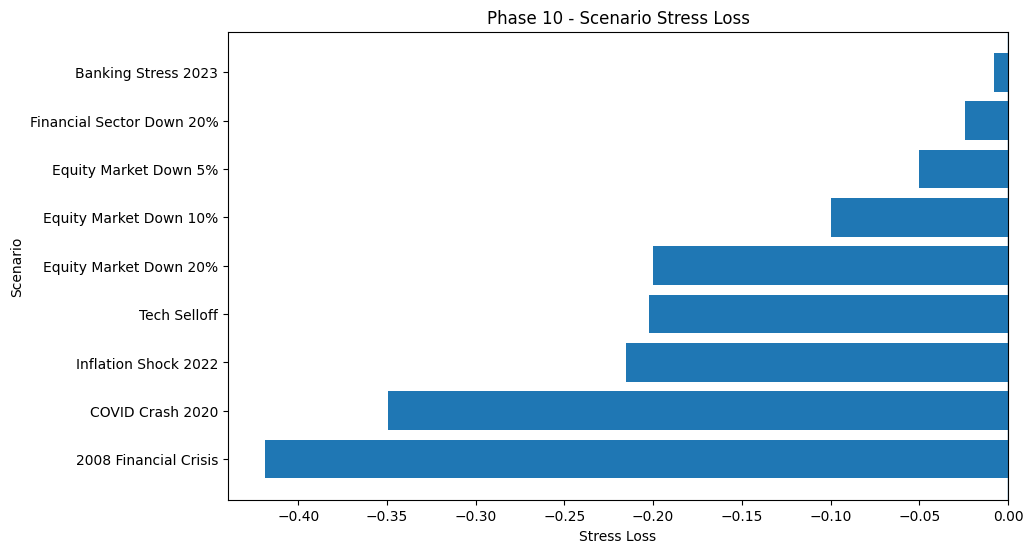

In [192]:
# Scenario Loss chart

loss_chart_data = (
    phase10_master_results[
        phase10_master_results["Stress Loss"].notna()
    ]
    .sort_values("Stress Loss")
    .copy()
)

plt.figure(figsize=(12, 6))

plt.barh(
    loss_chart_data["Scenario"],
    loss_chart_data["Stress Loss"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Stress Loss")
plt.ylabel("Scenario")
plt.title("Phase 10 - Scenario Stress Loss")

plt.subplots_adjust(
    left=0.30,
    right=0.95,
    top=0.90,
    bottom=0.12
)

plt.show()

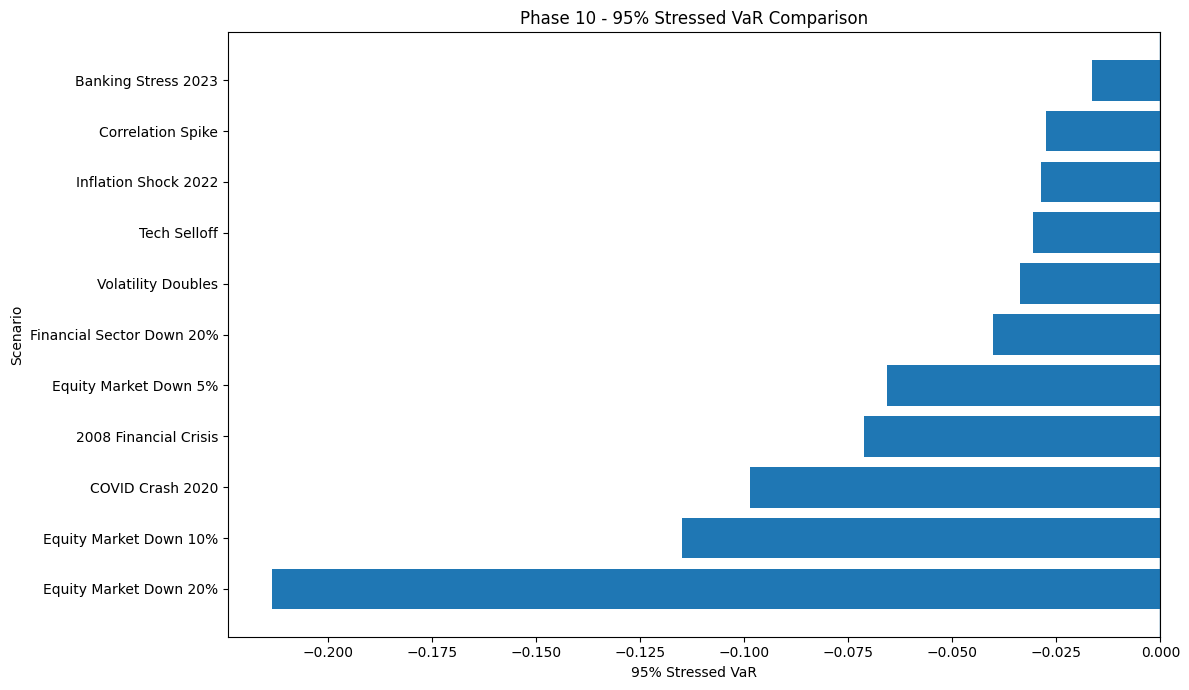

In [193]:
# Stress VaR comparison

var_chart_data = (
    phase10_master_results
    .sort_values("95% Stressed VaR")
)

plt.figure(figsize=(12, 7))

plt.barh(
    var_chart_data["Scenario"],
    var_chart_data["95% Stressed VaR"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("95% Stressed VaR")
plt.ylabel("Scenario")
plt.title("Phase 10 - 95% Stressed VaR Comparison")

plt.tight_layout()
plt.show()

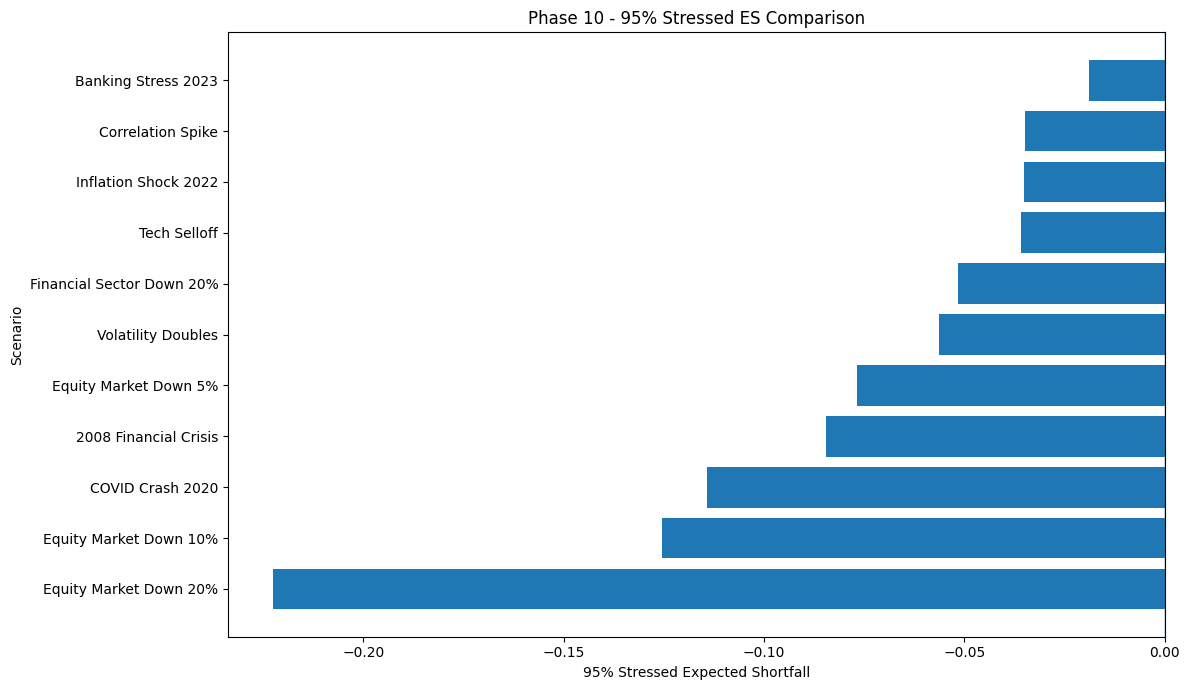

In [194]:
# Stress ES Comparison

es_chart_data = (
    phase10_master_results
    .sort_values("95% Stressed ES")
)

plt.figure(figsize=(12, 7))

plt.barh(
    es_chart_data["Scenario"],
    es_chart_data["95% Stressed ES"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("95% Stressed Expected Shortfall")
plt.ylabel("Scenario")
plt.title("Phase 10 - 95% Stressed ES Comparison")

plt.tight_layout()
plt.show()

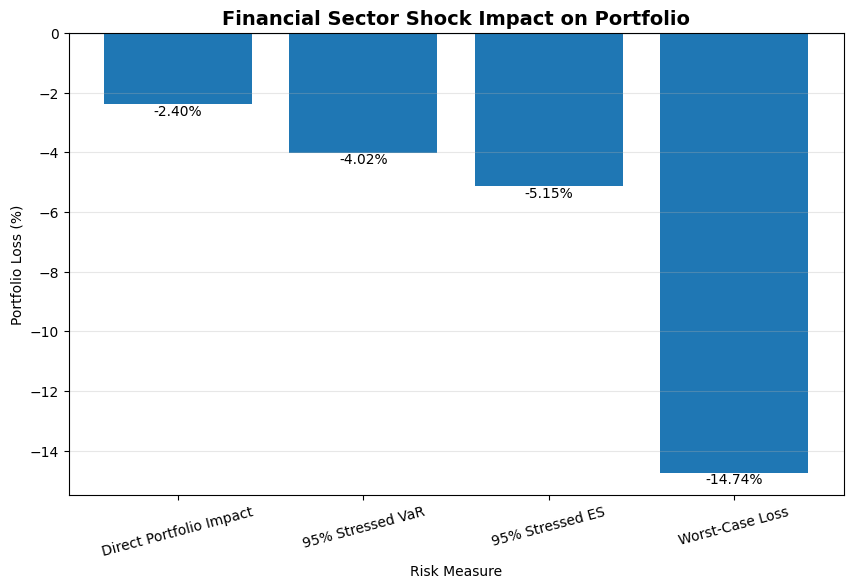

In [195]:
# Sector Shock Impact Chart

sector_chart_data = pd.DataFrame({
    "Metric": [
        "Direct Portfolio Impact",
        "95% Stressed VaR",
        "95% Stressed ES",
        "Worst-Case Loss"
    ],
    "Loss": [
        direct_sector_portfolio_impact,
        sector_stressed_var_95,
        sector_stressed_es_95,
        sector_worst_case_loss
    ]
})

plt.figure(figsize=(10, 6))

plt.bar(
    sector_chart_data["Metric"],
    sector_chart_data["Loss"] * 100
)

plt.axhline(0, linewidth=0.8)

plt.title(
    "Financial Sector Shock Impact on Portfolio",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Portfolio Loss (%)")
plt.xlabel("Risk Measure")

plt.xticks(rotation=15)

for i, value in enumerate(sector_chart_data["Loss"] * 100):
    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()

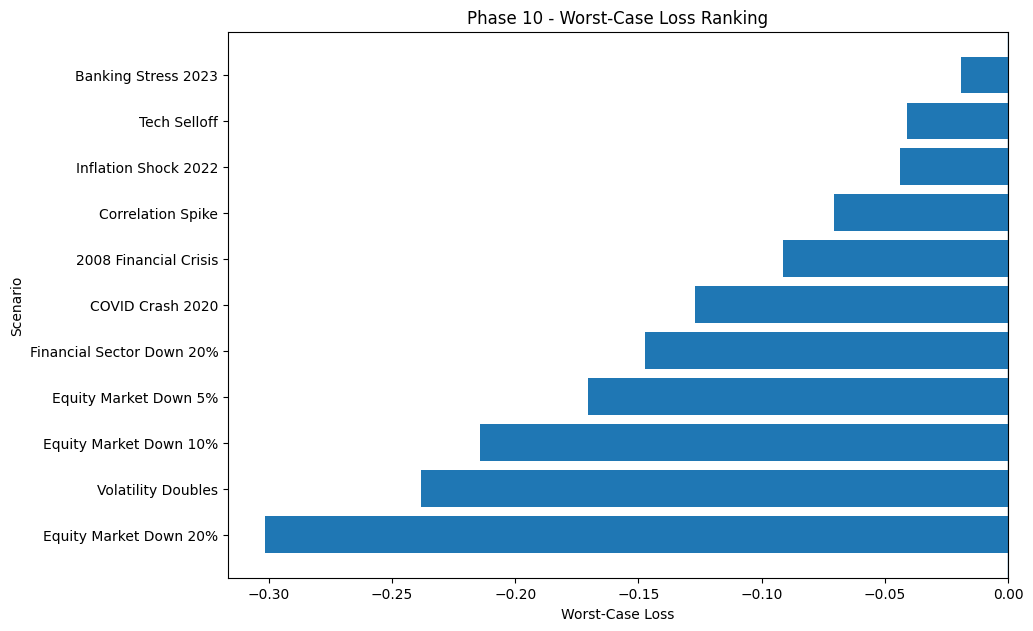

In [196]:
# Worst-loss ranking

worst_loss_chart_data = (
    phase10_master_results
    .sort_values("Worst-Case Loss")
)

plt.figure(figsize=(12, 7))

plt.barh(
    worst_loss_chart_data["Scenario"],
    worst_loss_chart_data["Worst-Case Loss"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Worst-Case Loss")
plt.ylabel("Scenario")
plt.title("Phase 10 - Worst-Case Loss Ranking")

plt.subplots_adjust(
    left=0.30,
    right=0.95,
    top=0.90,
    bottom=0.12
)

plt.show()

# **Validation Checks**

This phase independently validates the portfolio data, portfolio construction, Value at Risk (VaR) estimates, and backtesting procedures. Each check reports a status and supporting evidence. Failed checks are retained for investigation rather than automatically corrected.

In [197]:
# DATA AND PORTFOLIO CONSTRUCTION VALIDATION

validation_results = []

def record_check(category, check, passed, evidence):
    validation_results.append({
        "Category": category,
        "Validation Check": check,
        "Status": "PASS" if bool(passed) else "FAIL",
        "Evidence": str(evidence)
    })


# ------------------------------------------------------------
# 1. PRICE DATA INTEGRITY
# ------------------------------------------------------------

price_index = portfolio_prices.index

record_check(
    "Data",
    "Price dates are unique",
    price_index.is_unique,
    f"Duplicate dates: {price_index.duplicated().sum()}"
)

record_check(
    "Data",
    "Price dates are chronological",
    price_index.is_monotonic_increasing,
    f"First date: {price_index.min()}, Last date: {price_index.max()}"
)

missing_prices = int(portfolio_prices.isna().sum().sum())

record_check(
    "Data",
    "No missing prices",
    missing_prices == 0,
    f"Missing price values: {missing_prices}"
)

nonpositive_prices = int((portfolio_prices <= 0).sum().sum())

record_check(
    "Data",
    "All prices are positive",
    nonpositive_prices == 0,
    f"Non-positive price values: {nonpositive_prices}"
)


# ------------------------------------------------------------
# 2. RECONSTRUCT ASSET-LEVEL LOG RETURNS
# ------------------------------------------------------------

# portfolio_returns is currently a Series of length 49.
# Rebuild the asset-level return DataFrame from the 50 price columns.
asset_log_returns = np.log(
    portfolio_prices / portfolio_prices.shift(1)
)

# The first row is NaN because no prior price is available.
asset_log_returns_valid = asset_log_returns.iloc[1:]

record_check(
    "Data",
    "Asset return data has the expected dimensions",
    (
        asset_log_returns.shape[1] == portfolio_prices.shape[1]
        and len(asset_log_returns) == len(portfolio_prices)
    ),
    (
        f"Asset returns: {asset_log_returns.shape}; "
        f"Prices: {portfolio_prices.shape}"
    )
)

missing_asset_returns = int(
    asset_log_returns_valid.isna().sum().sum()
)

record_check(
    "Data",
    "No missing asset returns after initial observation",
    missing_asset_returns == 0,
    f"Missing return values: {missing_asset_returns}"
)

non_finite_asset_returns = int(
    (~np.isfinite(
        asset_log_returns_valid.to_numpy(dtype=float)
    )).sum()
)

record_check(
    "Data",
    "All asset returns are finite",
    non_finite_asset_returns == 0,
    f"Non-finite return values: {non_finite_asset_returns}"
)

record_check(
    "Data",
    "Asset return dates align with price dates",
    asset_log_returns.index.equals(price_index),
    (
        f"Price rows: {len(price_index)}; "
        f"Asset return rows: {len(asset_log_returns)}"
    )
)

# ------------------------------------------------------------
# 3. PORTFOLIO WEIGHT VALIDATION
# ------------------------------------------------------------

if "portfolio_weights" in globals():
    weights = np.asarray(
        portfolio_weights, dtype=float
    ).reshape(-1)

elif "equal_weights" in globals() and "Weight" in equal_weights.columns:
    weights = equal_weights["Weight"].to_numpy(dtype=float)

else:
    weights = np.array([], dtype=float)

weights_available = len(weights) > 0
number_of_assets = portfolio_prices.shape[1]

record_check(
    "Portfolio",
    "Portfolio weights are available",
    weights_available,
    f"Number of weights: {len(weights)}"
)

if weights_available:

    weights_finite = bool(np.isfinite(weights).all())

    record_check(
        "Portfolio",
        "Weights are finite",
        weights_finite,
        f"Number of weights: {len(weights)}"
    )

    weights_sum = float(weights.sum()) if weights_finite else np.nan

    record_check(
        "Portfolio",
        "Weights sum to 100%",
        weights_finite and np.isclose(
            weights_sum, 1.0, atol=1e-8
        ),
        (
            f"Weight sum: {weights_sum:.10f}"
            if weights_finite
            else "Weight sum cannot be calculated because weights are non-finite"
        )
    )

    record_check(
        "Portfolio",
        "Number of weights matches number of assets",
        len(weights) == number_of_assets,
        f"Weights: {len(weights)}; Assets: {number_of_assets}"
    )

    record_check(
        "Portfolio",
        "Weights are non-negative",
        weights_finite and bool((weights >= 0).all()),
        (
            f"Minimum weight: {weights.min():.10f}"
            if weights_finite
            else "Weights contain non-finite values"
        )
    )


# ------------------------------------------------------------
# 4. INDEPENDENT PORTFOLIO RETURN RECONCILIATION
# ------------------------------------------------------------

if (
    weights_available
    and len(weights) == number_of_assets
    and bool(np.isfinite(weights).all())
    and asset_log_returns_valid.notna().all().all()
    and np.isfinite(
        asset_log_returns_valid.to_numpy(dtype=float)
    ).all()
):

    # Recalculate the portfolio log returns from the asset returns.
    # This checks the notebook's equal-weight aggregation.
    independently_calculated_returns = (
        asset_log_returns_valid @ weights
    )

    existing_returns = portfolio_return_series.reindex(
        independently_calculated_returns.index
    )

    return_comparison = pd.concat(
        [
            independently_calculated_returns.rename("Independent"),
            existing_returns.rename("Notebook")
        ],
        axis=1
    ).dropna()

    if len(return_comparison) > 0:

        max_return_difference = float(
            (
                return_comparison["Independent"]
                - return_comparison["Notebook"]
            ).abs().max()
        )

        record_check(
            "Portfolio",
            "Portfolio returns reconcile with asset returns and weights",
            np.isclose(
                max_return_difference, 0.0, atol=1e-10
            ),
            (
                f"Compared observations: {len(return_comparison)}; "
                f"Maximum absolute difference: {max_return_difference:.12g}"
            )
        )

    else:
        record_check(
            "Portfolio",
            "Portfolio returns reconcile with asset returns and weights",
            False,
            "No common valid dates available for comparison"
        )

else:
    record_check(
        "Portfolio",
        "Portfolio returns reconcile with asset returns and weights",
        False,
        (
            "Reconciliation skipped: check weight availability, "
            "weight count, finite weights, and asset return validity"
        )
    )


# ------------------------------------------------------------
# 5. PORTFOLIO VALUE RECONCILIATION
# ------------------------------------------------------------

if (
    "portfolio_value" in globals()
    and "initial_portfolio_value" in globals()
):

    valid_portfolio_returns = portfolio_return_series.dropna()

    independently_calculated_value = (
        initial_portfolio_value
        * np.exp(valid_portfolio_returns.cumsum())
    )

    existing_value = portfolio_value.reindex(
        independently_calculated_value.index
    )

    value_comparison = pd.concat(
        [
            independently_calculated_value.rename("Independent"),
            existing_value.rename("Notebook")
        ],
        axis=1
    ).dropna()

    if len(value_comparison) > 0:

        max_value_difference = float(
            (
                value_comparison["Independent"]
                - value_comparison["Notebook"]
            ).abs().max()
        )

        record_check(
            "Portfolio",
            "Portfolio value reconciles with compounded returns",
            np.isclose(
                max_value_difference, 0.0, atol=0.01
            ),
            (
                f"Compared observations: {len(value_comparison)}; "
                f"Maximum absolute difference: {max_value_difference:.6f}"
            )
        )

    else:
        record_check(
            "Portfolio",
            "Portfolio value reconciles with compounded returns",
            False,
            "No common valid dates available for comparison"
        )

else:
    record_check(
        "Portfolio",
        "Portfolio value reconciliation",
        False,
        "portfolio_value or initial_portfolio_value is unavailable"
    )


# ------------------------------------------------------------
# 6. DISPLAY VALIDATION REPORT
# ------------------------------------------------------------

data_validation = pd.DataFrame(validation_results)

display(data_validation)

print("\nValidation summary")
print("------------------")
print(data_validation["Status"].value_counts().to_string())

,Category,Validation Check,Status,Evidence
0,Data,Price dates are unique,PASS,Duplicate dates: 0
1,Data,Price dates are chronological,PASS,"First date: 2016-01-04 00:00:00, Last date: 20..."
2,Data,No missing prices,PASS,Missing price values: 0
3,Data,All prices are positive,PASS,Non-positive price values: 0
4,Data,Asset return data has the expected dimensions,PASS,"Asset returns: (2514, 50); Prices: (2514, 50)"
5,Data,No missing asset returns after initial observa...,PASS,Missing return values: 0
6,Data,All asset returns are finite,PASS,Non-finite return values: 0
7,Data,Asset return dates align with price dates,PASS,Price rows: 2514; Asset return rows: 2514
8,Portfolio,Portfolio weights are available,PASS,Number of weights: 50
9,Portfolio,Weights are finite,PASS,Number of weights: 50



Validation summary
------------------
Status
PASS    15


In [198]:
# VaR AND BACKTEST ALIGNMENT VALIDATION

var_validation_results = []

def record_var_check(category, check, passed, evidence):
    var_validation_results.append({
        "Category": category,
        "Validation Check": check,
        "Status": "PASS" if bool(passed) else "FAIL",
        "Evidence": str(evidence)
    })


# ------------------------------------------------------------
# 1. CHECK THAT OOS BACKTEST DATA EXISTS
# ------------------------------------------------------------

if "oos_var_data" not in globals():
    raise NameError(
        "oos_var_data was not found. Run the out-of-sample VaR phase first."
    )

record_var_check(
    "Data",
    "Out-of-sample VaR data is available",
    isinstance(oos_var_data, pd.DataFrame) and not oos_var_data.empty,
    f"Shape: {oos_var_data.shape}"
)

record_var_check(
    "Data",
    "Out-of-sample dates are unique",
    oos_var_data.index.is_unique,
    f"Duplicate dates: {oos_var_data.index.duplicated().sum()}"
)

record_var_check(
    "Data",
    "Out-of-sample dates are chronological",
    oos_var_data.index.is_monotonic_increasing,
    f"First: {oos_var_data.index.min()}, Last: {oos_var_data.index.max()}"
)


# ------------------------------------------------------------
# 2. CHECK ACTUAL RETURNS
# ------------------------------------------------------------

actual_col = "Actual Return"

if actual_col not in oos_var_data.columns:
    raise KeyError(
        f"Expected column '{actual_col}' was not found. "
        f"Available columns: {oos_var_data.columns.tolist()}"
    )

actual_returns = oos_var_data[actual_col]

record_var_check(
    "Returns",
    "Actual returns contain no missing values",
    actual_returns.notna().all(),
    f"Missing values: {int(actual_returns.isna().sum())}"
)

record_var_check(
    "Returns",
    "Actual returns are finite",
    bool(np.isfinite(actual_returns.to_numpy(dtype=float)).all()),
    f"Non-finite values: {int((~np.isfinite(actual_returns.to_numpy(dtype=float))).sum())}"
)


# ------------------------------------------------------------
# 3. IDENTIFY AND CHECK VaR COLUMNS
# ------------------------------------------------------------

var_columns = [
    col for col in oos_var_data.columns
    if "VaR" in str(col) and "Exception" not in str(col)
]

record_var_check(
    "VaR",
    "VaR estimate columns are available",
    len(var_columns) > 0,
    f"VaR columns found: {len(var_columns)}; {var_columns}"
)

for col in var_columns:
    values = oos_var_data[col]

    record_var_check(
        "VaR",
        f"{col}: no missing values",
        values.notna().all(),
        f"Missing values: {int(values.isna().sum())}"
    )

    record_var_check(
        "VaR",
        f"{col}: all values are finite",
        bool(np.isfinite(values.to_numpy(dtype=float)).all()),
        f"Non-finite values: {int((~np.isfinite(values.to_numpy(dtype=float))).sum())}"
    )



# ------------------------------------------------------------
# 4. CHECK EXCEPTION INDICATORS AGAINST RETURNS AND VaR
# ------------------------------------------------------------

exception_columns = [
    col for col in oos_var_data.columns
    if "Exception" in str(col)
]

record_var_check(
    "Backtesting",
    "Exception indicator columns are available",
    len(exception_columns) > 0,
    f"Exception columns found: {len(exception_columns)}"
)

for exception_col in exception_columns:

    # Correct mapping:
    # "Historical Exception 95%" -> "Historical VaR 95%"
    var_col = str(exception_col).replace(
        " Exception ", " VaR "
    )

    if var_col not in oos_var_data.columns:
        record_var_check(
            "Backtesting",
            f"{exception_col}: matching VaR column exists",
            False,
            f"Expected matching column: {var_col}"
        )
        continue

    exception_values = oos_var_data[exception_col]
    matching_var = oos_var_data[var_col]

    # Check that exception indicators are binary and complete.
    record_var_check(
        "Backtesting",
        f"{exception_col}: indicators are binary",
        exception_values.notna().all()
        and exception_values.isin([0, 1, False, True]).all(),
        f"Observed values: {exception_values.dropna().unique()[:10]}"
    )

    # Lower-tail return convention:
    # An exception occurs when actual return is below the VaR threshold.
    expected_exceptions = (
        actual_returns < matching_var
    ).astype(int)

    comparable = pd.concat(
        [
            exception_values.rename("Stored"),
            expected_exceptions.rename("Expected")
        ],
        axis=1
    ).dropna()

    if len(comparable) > 0:

        mismatches = int(
            (
                comparable["Stored"].astype(int)
                != comparable["Expected"].astype(int)
            ).sum()
        )

        record_var_check(
            "Backtesting",
            f"{exception_col}: matches actual-return/VaR comparison",
            mismatches == 0,
            (
                f"Compared: {len(comparable)}; "
                f"Mismatches: {mismatches}"
            )
        )

    else:
        record_var_check(
            "Backtesting",
            f"{exception_col}: matches actual-return/VaR comparison",
            False,
            "No comparable observations"
        )


# ------------------------------------------------------------
# 5. CHECK 95% AND 99% VaR ORDERING WHERE BOTH EXIST
# ------------------------------------------------------------

for col_95 in [c for c in var_columns if "95%" in str(c)]:
    col_99 = str(col_95).replace("95%", "99%")

    if col_99 in oos_var_data.columns:
        # For lower-tail return thresholds, 99% VaR is generally
        # more extreme (more negative) than 95% VaR.
        comparison = oos_var_data[col_99] <= oos_var_data[col_95]

        record_var_check(
            "VaR",
            f"{col_95} and {col_99}: tail ordering",
            comparison.all(),
            f"Violations: {int((~comparison).sum())}"
        )


# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

var_validation = pd.DataFrame(var_validation_results)

display(var_validation)

print("\nValidation Summary")
print("-----------------------------")
print(var_validation["Status"].value_counts().to_string())

,Category,Validation Check,Status,Evidence
0,Data,Out-of-sample VaR data is available,PASS,"Shape: (1763, 25)"
1,Data,Out-of-sample dates are unique,PASS,Duplicate dates: 0
2,Data,Out-of-sample dates are chronological,PASS,"First: 2018-12-27 00:00:00, Last: 2025-12-31 0..."
3,Returns,Actual returns contain no missing values,PASS,Missing values: 0
4,Returns,Actual returns are finite,PASS,Non-finite values: 0
5,VaR,VaR estimate columns are available,PASS,"VaR columns found: 12; ['Historical VaR 95%', ..."
6,VaR,Historical VaR 95%: no missing values,PASS,Missing values: 0
7,VaR,Historical VaR 95%: all values are finite,PASS,Non-finite values: 0
8,VaR,Historical VaR 99%: no missing values,PASS,Missing values: 0
9,VaR,Historical VaR 99%: all values are finite,PASS,Non-finite values: 0



Validation Summary
-----------------------------
Status
PASS    59


In [199]:
# OUT-OF-SAMPLE WINDOW DIAGNOSTICS

print("OUT-OF-SAMPLE WINDOW DIAGNOSTICS")
print("-" * 45)

print("\n1. Estimation-window configuration")

if "estimation_window" in globals():
    print("Estimation window:", estimation_window)
else:
    print("estimation_window variable not found")

if "estimation_returns" in globals():
    print("Estimation observations:", len(estimation_returns))
    print("Estimation start:", estimation_returns.index.min())
    print("Estimation end:", estimation_returns.index.max())

if "oos_returns" in globals():
    print("\n2. Out-of-sample returns")
    print("OOS observations:", len(oos_returns))
    print("OOS start:", oos_returns.index.min())
    print("OOS end:", oos_returns.index.max())

if "backtest_returns" in globals():
    print("\n3. Full backtest return series")
    print("Total observations:", len(backtest_returns))
    print("Start:", backtest_returns.index.min())
    print("End:", backtest_returns.index.max())

print("\n4. OOS VaR data")
print("Rows:", len(oos_var_data))
print("Start:", oos_var_data.index.min())
print("End:", oos_var_data.index.max())

if "oos_returns" in globals():
    print(
        "OOS return dates match VaR dates:",
        oos_returns.index.equals(oos_var_data.index)
    )

if "backtest_returns" in globals() and "estimation_window" in globals():
    expected_oos_returns = backtest_returns.iloc[estimation_window:]

    print(
        "OOS dates match the configured estimation split:",
        expected_oos_returns.index.equals(oos_var_data.index)
    )

    print(
        "Expected OOS observations:",
        len(expected_oos_returns)
    )

print("\n5. Available forecast-related variables")

for name in [
    "oos_var_data",
    "backtest_returns",
    "estimation_returns",
    "oos_returns",
    "estimation_window",
    "portfolio_return_series"
]:
    if name in globals():
        value = globals()[name]
        print(
            f"{name}: type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'N/A')}"
        )

OUT-OF-SAMPLE WINDOW DIAGNOSTICS
---------------------------------------------

1. Estimation-window configuration
Estimation window: 750
Estimation observations: 750
Estimation start: 2016-01-05 00:00:00
Estimation end: 2018-12-26 00:00:00

2. Out-of-sample returns
OOS observations: 1763
OOS start: 2018-12-27 00:00:00
OOS end: 2025-12-31 00:00:00

3. Full backtest return series
Total observations: 2513
Start: 2016-01-05 00:00:00
End: 2025-12-31 00:00:00

4. OOS VaR data
Rows: 1763
Start: 2018-12-27 00:00:00
End: 2025-12-31 00:00:00
OOS return dates match VaR dates: True
OOS dates match the configured estimation split: True
Expected OOS observations: 1763

5. Available forecast-related variables
oos_var_data: type=DataFrame, shape=(1763, 25)
backtest_returns: type=Series, shape=(2513,)
estimation_returns: type=Series, shape=(750,)
oos_returns: type=Series, shape=(1763,)
estimation_window: type=int, shape=N/A
portfolio_return_series: type=Series, shape=(2513,)


In [200]:
# FIRST OOS FORECAST ALIGNMENT CHECK

print("FIRST OOS FORECAST ALIGNMENT CHECK")
print("-" * 45)

first_oos_date = oos_returns.index[0]
last_estimation_date = estimation_returns.index[-1]

print("Last estimation date:", last_estimation_date)
print("First OOS date:", first_oos_date)

print("\nFirst OOS return:")
print(oos_returns.iloc[0])

print("\nFirst OOS VaR forecasts:")
print(oos_var_data.loc[
    first_oos_date,
    [
        "Historical VaR 95%",
        "EWMA VaR 95%",
        "GARCH VaR 95%",
        "GJR-GARCH VaR 95%"
    ]
])

print("\nForecast availability on the first OOS date:")

for model in ["Historical", "EWMA", "GARCH", "GJR-GARCH"]:
    col = f"{model} VaR 95%"
    print(f"{model}: {oos_var_data.loc[first_oos_date, col]}")

print("\nDate checks:")
print(
    "First OOS date follows estimation period:",
    first_oos_date > last_estimation_date
)
print(
    "First OOS date matches forecast index:",
    first_oos_date in oos_var_data.index
)

FIRST OOS FORECAST ALIGNMENT CHECK
---------------------------------------------
Last estimation date: 2018-12-26 00:00:00
First OOS date: 2018-12-27 00:00:00

First OOS return:
0.0082144224835325

First OOS VaR forecasts:
Historical VaR 95%   -0.020849
EWMA VaR 95%         -0.032876
GARCH VaR 95%        -0.043536
GJR-GARCH VaR 95%    -0.035517
Name: 2018-12-27 00:00:00, dtype: float64

Forecast availability on the first OOS date:
Historical: -0.02084909088738592
EWMA: -0.03287588652015627
GARCH: -0.043535694013436786
GJR-GARCH: -0.035517171044486526

Date checks:
First OOS date follows estimation period: True
First OOS date matches forecast index: True


In [201]:
# RECURSIVE FORECAST CONSISTENCY AUDIT

print("PHASE 11.5: RECURSIVE FORECAST CONSISTENCY AUDIT")
print("-" * 55)

audit_results = []

def audit_check(name, condition, detail):
    audit_results.append({
        "Check": name,
        "Status": "PASS" if condition else "FAIL",
        "Detail": detail
    })

# 1. Historical VaR: verify the one-day shift
expected_hist_95 = (
    historical_var_250_95.shift(1).loc[oos_returns.index]
)

hist_match = np.allclose(
    expected_hist_95.to_numpy(),
    historical_var_oos_95.to_numpy(),
    equal_nan=True
)

audit_check(
    "Historical VaR uses a one-day shift",
    hist_match,
    f"Dates checked: {len(oos_returns)}"
)

# 2. EWMA variance: verify the full recursive equation
ewma_expected = pd.Series(
    index=portfolio_return_series.index,
    dtype=float
)

ewma_expected.iloc[0] = portfolio_return_series.iloc[0] ** 2

for t in range(1, len(portfolio_return_series)):
    ewma_expected.iloc[t] = (
        lambda_ewma * ewma_expected.iloc[t - 1]
        + (1 - lambda_ewma)
        * portfolio_return_series.iloc[t - 1] ** 2
    )

ewma_match = np.allclose(
    ewma_expected.to_numpy(),
    ewma_variance.to_numpy(),
    rtol=1e-10,
    atol=1e-12,
    equal_nan=True
)

audit_check(
    "EWMA variance follows lagged-return recursion",
    ewma_match,
    f"Observations checked: {len(ewma_expected)}"
)

# 3. GARCH: independently reconstruct OOS variance forecasts
returns_pct = backtest_returns * 100

garch_expected = pd.Series(
    index=oos_returns.index,
    dtype=float
)

prev_var = float(
    garch_oos_fit.conditional_volatility.iloc[-1] ** 2
)
prev_ret = float(
    returns_pct.iloc[estimation_window - 1]
)

for date in oos_returns.index:
    forecast_var = (
        omega
        + alpha * (prev_ret - mu) ** 2
        + beta * prev_var
    )

    garch_expected.loc[date] = forecast_var

    prev_ret = float(returns_pct.loc[date])
    prev_var = forecast_var

garch_match = np.allclose(
    garch_expected.to_numpy(),
    garch_oos_variance.to_numpy(),
    rtol=1e-9,
    atol=1e-10,
    equal_nan=True
)

audit_check(
    "GARCH OOS variance follows recursive equation",
    garch_match,
    f"Forecasts checked: {len(garch_expected)}"
)

# 4. GJR-GARCH: independently reconstruct OOS variance forecasts
gjr_expected = pd.Series(
    index=oos_returns.index,
    dtype=float
)

prev_var = float(
    gjr_oos_fit.conditional_volatility.iloc[-1] ** 2
)
prev_ret = float(
    returns_pct.iloc[estimation_window - 1]
)

for date in oos_returns.index:
    prev_epsilon = prev_ret - mu_gjr
    negative_shock = int(prev_epsilon < 0)

    forecast_var = (
        omega_gjr
        + alpha_gjr * prev_epsilon ** 2
        + gamma_gjr * prev_epsilon ** 2 * negative_shock
        + beta_gjr * prev_var
    )

    gjr_expected.loc[date] = forecast_var

    prev_ret = float(returns_pct.loc[date])
    prev_var = forecast_var

gjr_match = np.allclose(
    gjr_expected.to_numpy(),
    gjr_oos_variance.to_numpy(),
    rtol=1e-9,
    atol=1e-10,
    equal_nan=True
)

audit_check(
    "GJR-GARCH OOS variance follows recursive equation",
    gjr_match,
    f"Forecasts checked: {len(gjr_expected)}"
)

# Display audit results
audit_table = pd.DataFrame(audit_results)
display(audit_table)

print("\nAudit summary:")
print(audit_table["Status"].value_counts().to_string())

PHASE 11.5: RECURSIVE FORECAST CONSISTENCY AUDIT
-------------------------------------------------------


,Check,Status,Detail
0,Historical VaR uses a one-day shift,PASS,Dates checked: 1763
1,EWMA variance follows lagged-return recursion,PASS,Observations checked: 2513
2,GARCH OOS variance follows recursive equation,PASS,Forecasts checked: 1763
3,GJR-GARCH OOS variance follows recursive equation,PASS,Forecasts checked: 1763



Audit summary:
Status
PASS    4


In [202]:
# VaR THRESHOLD CONSTRUCTION AUDIT

print("PHASE 11.6: VaR THRESHOLD CONSTRUCTION AUDIT")
print("-" * 55)

threshold_audit = []

def add_threshold_check(name, passed, detail):
    threshold_audit.append({
        "Check": name,
        "Status": "PASS" if passed else "FAIL",
        "Detail": detail
    })

# ---------------------------------------------------------
# 1. Verify standardized quantiles use estimation data
# ---------------------------------------------------------

first_oos_date = oos_returns.index.min()

ewma_scope_ok = (
    ewma_estimation_data.index.max() < first_oos_date
)

garch_scope_ok = (
    garch_estimation_data.index.max() < first_oos_date
)

gjr_scope_ok = (
    gjr_estimation_data.index.max() < first_oos_date
)

add_threshold_check(
    "EWMA quantile sample is pre-OOS",
    ewma_scope_ok,
    f"Last estimation date: {ewma_estimation_data.index.max()}"
)

add_threshold_check(
    "GARCH quantile sample is pre-OOS",
    garch_scope_ok,
    f"Last estimation date: {garch_estimation_data.index.max()}"
)

add_threshold_check(
    "GJR-GARCH quantile sample is pre-OOS",
    gjr_scope_ok,
    f"Last estimation date: {gjr_estimation_data.index.max()}"
)

# ---------------------------------------------------------
# 2. Verify tail quantiles are in the correct order
# ---------------------------------------------------------

for model, q95, q99, q995 in [
    (
        "EWMA",
        ewma_standardized_var_95,
        ewma_standardized_var_99,
        ewma_standardized_var_995
    ),
    (
        "GARCH",
        garch_standardized_var_95,
        garch_standardized_var_99,
        garch_standardized_var_995
    ),
    (
        "GJR-GARCH",
        gjr_standardized_var_95,
        gjr_standardized_var_99,
        gjr_standardized_var_995
    )
]:
    ordered = q995 <= q99 <= q95

    add_threshold_check(
        f"{model} quantile ordering",
        ordered,
        f"99.5%={q995:.6f}, 99%={q99:.6f}, 95%={q95:.6f}"
    )

# ---------------------------------------------------------
# 3. Compare existing GARCH VaR with mean-adjusted VaR
# ---------------------------------------------------------
# GARCH was fitted on percentage returns.
# Therefore mu is in percentage units and must be divided
# by 100 when combined with decimal-return VaR thresholds.

garch_var_95_mean_adjusted = (
    mu / 100
    + garch_standardized_var_95
    * garch_oos_volatility_decimal
)

garch_var_99_mean_adjusted = (
    mu / 100
    + garch_standardized_var_99
    * garch_oos_volatility_decimal
)

garch_var_995_mean_adjusted = (
    mu / 100
    + garch_standardized_var_995
    * garch_oos_volatility_decimal
)

print("\nGARCH mean adjustment")
print("Estimated conditional mean (%):", mu)
print("Mean in decimal-return units:", mu / 100)
print(
    "Maximum absolute 95% VaR difference:",
    (
        garch_var_95_mean_adjusted - garch_var_oos_95
    ).abs().max()
)

# ---------------------------------------------------------
# 4. Compare existing GJR-GARCH VaR with mean-adjusted VaR
# ---------------------------------------------------------

gjr_var_95_mean_adjusted = (
    mu_gjr / 100
    + gjr_standardized_var_95
    * gjr_oos_volatility / 100
)

gjr_var_99_mean_adjusted = (
    mu_gjr / 100
    + gjr_standardized_var_99
    * gjr_oos_volatility / 100
)

gjr_var_995_mean_adjusted = (
    mu_gjr / 100
    + gjr_standardized_var_995
    * gjr_oos_volatility / 100
)

print("\nGJR-GARCH mean adjustment")
print("Estimated conditional mean (%):", mu_gjr)
print("Mean in decimal-return units:", mu_gjr / 100)
print(
    "Maximum absolute 95% VaR difference:",
    (
        gjr_var_95_mean_adjusted - gjr_var_oos_95
    ).abs().max()
)

# ---------------------------------------------------------
# 5. Confirm existing thresholds equal their current formulas
# ---------------------------------------------------------

garch_formula_match = np.allclose(
    garch_var_oos_95.to_numpy(),
    (
        mu / 100
        + garch_standardized_var_95
        * garch_oos_volatility_decimal
    ).to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

gjr_formula_match = np.allclose(
    gjr_var_oos_95.to_numpy(),
    (
        mu_gjr / 100
        + gjr_standardized_var_95
        * gjr_oos_volatility / 100
    ).to_numpy(),
    rtol=1e-10,
    atol=1e-12
)

add_threshold_check(
    "GARCH VaR matches its mean-adjusted formula",
    garch_formula_match,
    "Checks the 95% threshold including the fitted conditional mean"
)

add_threshold_check(
    "GJR-GARCH VaR matches its mean-adjusted formula",
    gjr_formula_match,
    "Checks the 95% threshold including the fitted conditional mean"
)

# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------

threshold_audit_table = pd.DataFrame(threshold_audit)
display(threshold_audit_table)

print("\nAudit summary:")
print(threshold_audit_table["Status"].value_counts().to_string())

PHASE 11.6: VaR THRESHOLD CONSTRUCTION AUDIT
-------------------------------------------------------

GARCH mean adjustment
Estimated conditional mean (%): 0.10472257505379662
Mean in decimal-return units: 0.0010472257505379661
Maximum absolute 95% VaR difference: 0.0

GJR-GARCH mean adjustment
Estimated conditional mean (%): 0.07403776350041713
Mean in decimal-return units: 0.0007403776350041713
Maximum absolute 95% VaR difference: 0.0


,Check,Status,Detail
0,EWMA quantile sample is pre-OOS,PASS,Last estimation date: 2018-12-26 00:00:00
1,GARCH quantile sample is pre-OOS,PASS,Last estimation date: 2018-12-26 00:00:00
2,GJR-GARCH quantile sample is pre-OOS,PASS,Last estimation date: 2018-12-26 00:00:00
3,EWMA quantile ordering,PASS,"99.5%=-5.580984, 99%=-4.033911, 95%=-1.644734"
4,GARCH quantile ordering,PASS,"99.5%=-3.883807, 99%=-3.188045, 95%=-1.604356"
5,GJR-GARCH quantile ordering,PASS,"99.5%=-3.961237, 99%=-3.099976, 95%=-1.560305"
6,GARCH VaR matches its mean-adjusted formula,PASS,Checks the 95% threshold including the fitted ...
7,GJR-GARCH VaR matches its mean-adjusted formula,PASS,Checks the 95% threshold including the fitted ...



Audit summary:
Status
PASS    8


In [203]:
# CONDITIONAL-MEAN IMPACT ON OOS BACKTESTING

print("PHASE 11.7: CONDITIONAL-MEAN IMPACT")
print("-" * 60)

# Build comparison thresholds without overwriting existing VaR series
mean_adjusted_var = pd.DataFrame(index=oos_returns.index)

for confidence, quantile in [
    ("95%", 0.05),
    ("99%", 0.01),
    ("99.5%", 0.005)
]:
    # GARCH: fitted mean and volatility are in percentage units
    mean_adjusted_var[f"GARCH {confidence}"] = (
        mu / 100
        + {
            "95%": garch_standardized_var_95,
            "99%": garch_standardized_var_99,
            "99.5%": garch_standardized_var_995
        }[confidence] * garch_oos_volatility_decimal
    )

    # GJR-GARCH: fitted mean and volatility are in percentage units
    mean_adjusted_var[f"GJR-GARCH {confidence}"] = (
        mu_gjr / 100
        + {
            "95%": gjr_standardized_var_95,
            "99%": gjr_standardized_var_99,
            "99.5%": gjr_standardized_var_995
        }[confidence] * gjr_oos_volatility / 100
    )

# Compare exception counts under current and mean-adjusted thresholds
comparison_rows = []

for model in ["GARCH", "GJR-GARCH"]:
    for confidence in ["95%", "99%", "99.5%"]:
        existing_col = f"{model} VaR {confidence}"
        adjusted_col = f"{model} {confidence}"

        existing_threshold = oos_var_data[existing_col]
        adjusted_threshold = mean_adjusted_var[adjusted_col]
        actual = oos_var_data["Actual Return"]

        existing_exceptions = (actual < existing_threshold)
        adjusted_exceptions = (actual < adjusted_threshold)

        comparison_rows.append({
            "Model": model,
            "Confidence": confidence,
            "Expected Exceptions (approx.)": round(
                len(actual) * (1 - float(confidence.strip("%")) / 100)
            ),
            "Existing Exceptions": int(existing_exceptions.sum()),
            "Mean-Adjusted Exceptions": int(adjusted_exceptions.sum()),
            "Change in Exceptions": int(
                adjusted_exceptions.sum() - existing_exceptions.sum()
            ),
            "Thresholds Changed": int(
                (existing_threshold - adjusted_threshold).abs().gt(1e-12).sum()
            )
        })

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)

print("\nNote: Expected counts are approximate benchmarks,")
print("not pass/fail criteria for a valid VaR model.")

PHASE 11.7: CONDITIONAL-MEAN IMPACT
------------------------------------------------------------


,Model,Confidence,Expected Exceptions (approx.),Existing Exceptions,Mean-Adjusted Exceptions,Change in Exceptions,Thresholds Changed
0,GARCH,95%,88,136,136,0,0
1,GARCH,99%,18,12,12,0,0
2,GARCH,99.5%,9,8,8,0,0
3,GJR-GARCH,95%,88,140,140,0,0
4,GJR-GARCH,99%,18,12,12,0,0
5,GJR-GARCH,99.5%,9,9,9,0,0



Note: Expected counts are approximate benchmarks,
not pass/fail criteria for a valid VaR model.


In [204]:
# FINAL VAR SPECIFICATION AUDIT

print("GARCH conditional mean (percentage units):", mu)
print("GJR-GARCH conditional mean (percentage units):", mu_gjr)

print("\nExisting exception counts:")
display(
    kupiec_results[
        kupiec_results["Model"].isin(["GARCH", "GJR-GARCH"])
    ][["Model", "Confidence", "Exceptions", "Expected Exceptions",
       "P-value", "Conclusion"]].reset_index(drop=True)
)

print("\nExisting conditional coverage results:")
display(
    conditional_coverage_results[
        conditional_coverage_results["Model"].isin(["GARCH", "GJR-GARCH"])
    ][["Model", "Confidence", "LR Conditional Coverage",
       "P-value", "Conclusion"]].reset_index(drop=True)
)

GARCH conditional mean (percentage units): 0.10472257505379662
GJR-GARCH conditional mean (percentage units): 0.07403776350041713

Existing exception counts:


,Model,Confidence,Exceptions,Expected Exceptions,P-value,Conclusion
0,GARCH,95%,136,88.150000,0.000001,Fail
1,GARCH,99%,12,17.630000,0.152662,Pass
2,GARCH,99.5%,8,8.815000,0.779798,Pass
3,GJR-GARCH,95%,140,88.150000,0.000000,Fail
4,GJR-GARCH,99%,12,17.630000,0.152662,Pass
5,GJR-GARCH,99.5%,9,8.815000,0.950363,Pass



Existing conditional coverage results:


,Model,Confidence,LR Conditional Coverage,P-value,Conclusion
0,GARCH,95%,23.651458,0.000007,Fail
1,GARCH,99%,2.210025,0.331207,Pass
2,GARCH,99.5%,0.151143,0.927214,Pass
3,GJR-GARCH,95%,27.452330,0.000001,Fail
4,GJR-GARCH,99%,2.210025,0.331207,Pass
5,GJR-GARCH,99.5%,0.096289,0.952996,Pass
